# [기초-실습] 통계 101x데이터 분석: (5-6장) 다양한 가설검정

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [31]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!pip install statsmodels
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

In [34]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 게임 아이템 뽑기 확률, 정말 10%일까? (난이도: 하)

**📘 문제**

- 어떤 게임 개발사에서 새로운 아이템의 뽑기 확률이 **10%**로 설정되었다고 주장하고 있습니다.

- 그런데 유저 커뮤니티에서는 "실제 확률은 10%보다 낮은 것 같다"는 의혹이 제기되었습니다.

- 이를 확인하기 위해 한 유저가 아이템을 **200번 뽑았고, 그중 12번 성공**했습니다.

- 이번 실습에서는 **이항검정(Binomial Test)**으로 이 결과가 개발사의 주장을 기각할 만큼 유의미한지 확인하고,
  시뮬레이션을 통해 **p-값이 무엇을 의미하는지**를 직접 눈으로 확인해 봅니다.

📌 [이항분포 수식 대입 및 해석]
• 이항분포 PMF 공식: P(X = k) = nCk * p^k * (1-p)^(n-k)
• 수치 대입: P(X = 12) = 200C12 * (0.10)^12 * (0.90)^188
• 정확히 12회 성공할 확률: P(X = 12) = 0.015257 (1.5257%)
------------------------------------------------------------
📌 [단측 이항검정 결과 (H1: p < 0.10)]
• p-value 수식: P(X ≤ 12) = P(X=0) + P(X=1) + ... + P(X=12)
• 계산된 p-value (유의확률): 0.032047 (3.2047%)
------------------------------------------------------------
👉 결론: p-value < 0.05 이므로 개발사의 주장(10%)을 기각합니다.
   (실제 뽑기 확률이 10%보다 낮다고 볼 통계적으로 유의미한 근거가 있습니다.)


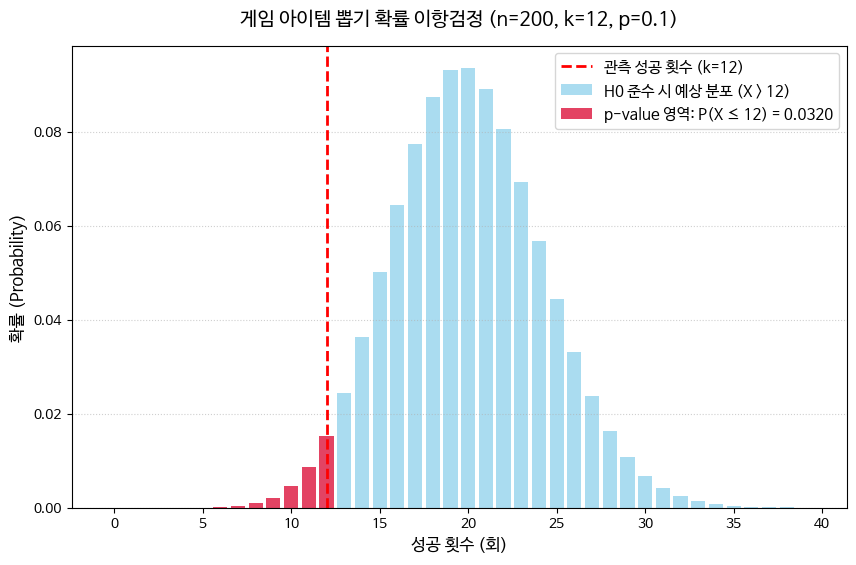

In [35]:
# 1. 나눔폰트 설치 및 맷플롯립 캐시 정리
!sudo apt-get install -y fonts-nanum > /dev/null
!fc-cache -fv > /dev/null

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
from scipy.stats import binom, binomtest

# 2. 폰트 경로 명시 (한글 깨짐 방지)
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_name = fm.FontProperties(fname=font_path).get_name()
plt.rc('font', family=font_name)
plt.rcParams['axes.unicode_minus'] = False

# 3. 데이터 및 조건 정의
n = 200        # 총 시행 횟수
k = 12         # 관측된 성공 횟수
p_0 = 0.10     # 귀무가설 H0 아래에서의 성공 확률 (10%)

"""
======================================================================
[이항분포 확률 공식 및 풀이 설명]

이항분포 B(n, p)에서 정확히 k번 성공할 수식이 되는 확률질량함수(PMF):
    P(X = k) = ₀Cₖ * p^k * (1 - p)^(n - k)
             = [n! / (k! * (n - k)!)] * p^k * (1 - p)^(n - k)

[대입 수치 (n=200, k=12, p=0.10)]:
    P(X = 12) = ₂₀₀C₁₂ * (0.10)¹² * (0.90)¹⁸⁸

단측검정(less)의 p-value는 성공 횟수가 12회 이하일 확률의 합입니다:
    p-value = P(X ≤ 12) = ∑ [k=0 to 12] P(X = k)
======================================================================
"""

# 4. 이항검정 (Binomial Test) 계산
result = binomtest(k, n, p_0, alternative='less')
p_value = result.pvalue

# 정확히 12번 성공할 확률 P(X = 12) 계산
prob_exact_12 = binom.pmf(k, n, p_0)

# 출력문 구성
print("=" * 60)
print("📌 [이항분포 수식 대입 및 해석]")
print(f"• 이항분포 PMF 공식: P(X = k) = nCk * p^k * (1-p)^(n-k)")
print(f"• 수치 대입: P(X = 12) = 200C12 * (0.10)^12 * (0.90)^188")
print(f"• 정확히 12회 성공할 확률: P(X = 12) = {prob_exact_12:.6f} ({prob_exact_12*100:.4f}%)")
print("-" * 60)
print("📌 [단측 이항검정 결과 (H1: p < 0.10)]")
print(f"• p-value 수식: P(X ≤ 12) = P(X=0) + P(X=1) + ... + P(X=12)")
print(f"• 계산된 p-value (유의확률): {p_value:.6f} ({p_value*100:.4f}%)")
print("-" * 60)

if p_value < 0.05:
    print("👉 결론: p-value < 0.05 이므로 개발사의 주장(10%)을 기각합니다.")
    print("   (실제 뽑기 확률이 10%보다 낮다고 볼 통계적으로 유의미한 근거가 있습니다.)")
else:
    print("👉 결론: p-value >= 0.05 이므로 개발사의 주장을 기각할 근거가 부족합니다.")
print("=" * 60)

# 5. 시뮬레이션 및 그래프 시각화
np.random.seed(42)
n_simulations = 100000
simulated_successes = np.random.binomial(n=n, p=p_0, size=n_simulations)

plt.figure(figsize=(10, 6))

x = np.arange(0, 40)
pmf = binom.pmf(x, n, p_0)

# 이론적 이항분포 막대그래프
plt.bar(x[x > k], pmf[x > k], color='skyblue', alpha=0.7, label='H0 준수 시 예상 분포 (X > 12)')
plt.bar(x[x <= k], pmf[x <= k], color='crimson', alpha=0.8, label=f'p-value 영역: P(X ≤ 12) = {p_value:.4f}')

# 기준선 표시
plt.axvline(x=k, color='red', linestyle='--', linewidth=2, label=f'관측 성공 횟수 (k={k})')

plt.title(f'게임 아이템 뽑기 확률 이항검정 (n={n}, k={k}, p={p_0})', fontsize=14, pad=15)
plt.xlabel('성공 횟수 (회)', fontsize=12)
plt.ylabel('확률 (Probability)', fontsize=12)
plt.xticks(np.arange(0, 41, 5))
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 이항검정을 수행하여 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"만약 개발사의 주장대로 실제 확률이 정말 10%라면"** 200번 뽑기에서 성공 횟수가 어떻게 분포하는지 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 우리가 관찰한 '12번 성공'이 얼마나 희귀한 일인지 관찰해 봅시다.

In [1]:
# [문제 1] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설): 게임 아이템의 실제 뽑기 확률은 10%이다. (p = 0.10)
# H₁ (대립가설): 게임 아이템의 실제 뽑기 확률은 10%보다 낮다. (p < 0.10)

=== [문제 1 - Q2] 이항검정 결과 ===
• 설정된 alternative 인수: 'less' (확률이 더 낮다는 의혹 검증)
• 계산된 p-value (유의확률): 0.032047 (3.2047%)
• 결론: p-value < 0.05 이므로 개발사의 주장(10%)을 기각합니다. (확률이 낮음)


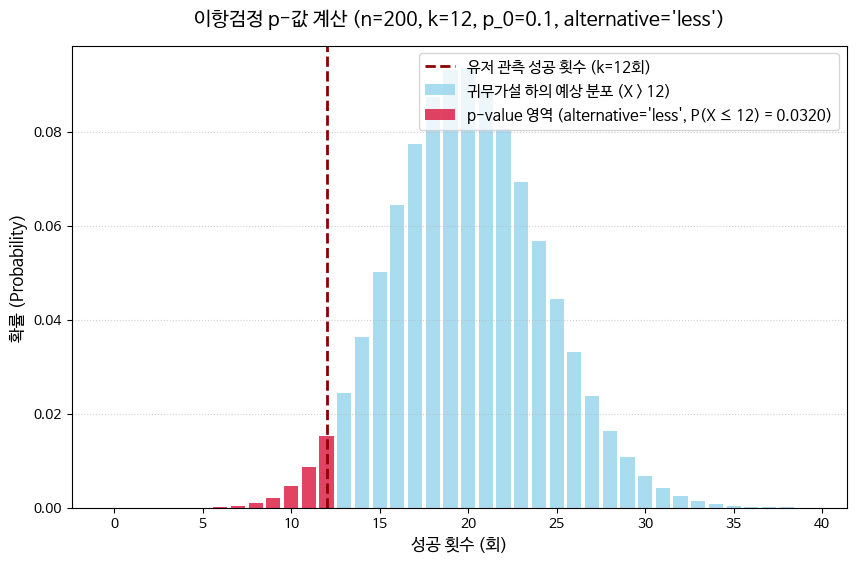

In [2]:
# 1. 나눔 폰트 패키지 설치 및 설정 (한글 깨짐 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom, binomtest

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 정의
n = 200  # 총 시도 횟수
k = 12  # 성공 횟수
p_0 = 0.10  # 개발사 주장 확률 (10%)

# ==============================================================================
# [문제 1] Q2. 이항검정을 수행하고 p-값을 계산해봅시다.
# '확률이 더 낮은 것 같다'는 주장을 검증하려면 alternative 인수를 어떻게 설정해야 할까요?
# 정답: alternative='less' (실제 확률이 주장된 10%보다 '낮다'는 방향을 검증하는 단측 검정)
# ==============================================================================

# 3. 이항검정 수행
result = binomtest(k, n, p_0, alternative="less")
p_value = result.pvalue

print(f"=== [문제 1 - Q2] 이항검정 결과 ===")
print(f"• 설정된 alternative 인수: 'less' (확률이 더 낮다는 의혹 검증)")
print(f"• 계산된 p-value (유의확률): {p_value:.6f} ({p_value*100:.4f}%)")

if p_value < 0.05:
    print(
        "• 결론: p-value < 0.05 이므로 개발사의 주장(10%)을 기각합니다. (확률이 낮음)"
    )
else:
    print(
        "• 결론: p-value >= 0.05 이므로 개발사의 주장을 기각할 근거가 부족합니다."
    )

# 4. 시각화 그래프
plt.figure(figsize=(10, 6))
x = np.arange(0, 40)
pmf_values = binom.pmf(x, n, p_0)

plt.bar(
    x[x > k],
    pmf_values[x > k],
    color="skyblue",
    alpha=0.7,
    label="귀무가설 하의 예상 분포 (X > 12)",
)
plt.bar(
    x[x <= k],
    pmf_values[x <= k],
    color="crimson",
    alpha=0.8,
    label=f"p-value 영역 (alternative='less', P(X ≤ 12) = {p_value:.4f})",
)

plt.axvline(
    x=k,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"유저 관측 성공 횟수 (k={k}회)",
)

plt.title(
    f"이항검정 p-값 계산 (n={n}, k={k}, p_0={p_0}, alternative='less')",
    fontsize=14,
    pad=15,
)
plt.xlabel("성공 횟수 (회)", fontsize=12)
plt.ylabel("확률 (Probability)", fontsize=12)
plt.xticks(np.arange(0, 41, 5))
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.show()

📌 [통계적 가설 검정 결과 (유의수준 alpha = 0.05)]
• 계산된 p-value: 0.032047 (3.2047%)
• 유의수준 alpha: 0.05
------------------------------------------------------------
• 결론: p-value (0.0320) < alpha (0.05) 이므로 귀무가설(H₀)을 기각합니다.
• 해석: 유저들의 의혹대로 실제 뽑기 확률이 10%보다 낮다는 통계적으로 유의미한 근거가 있습니다.


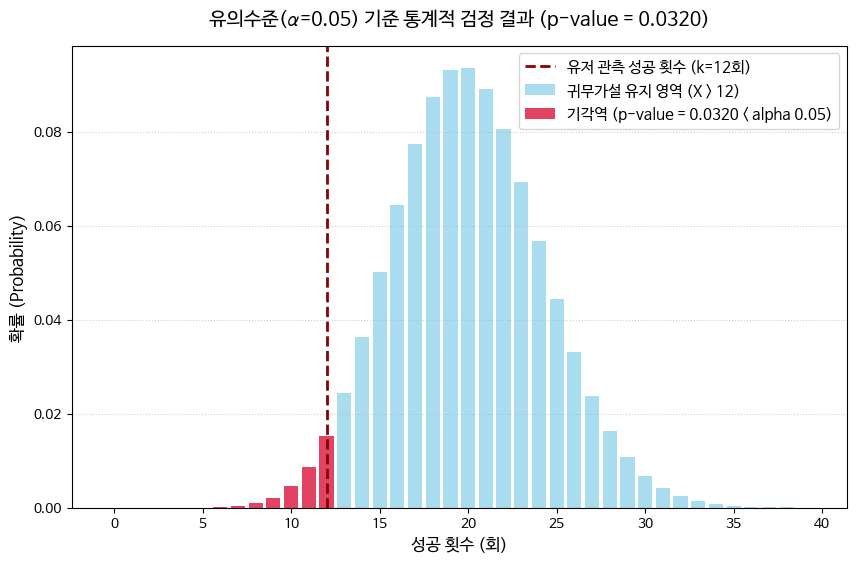

In [3]:
# 1. 나눔 폰트 패키지 설치 및 설정 (한글 깨짐 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom, binomtest

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 및 유의수준 정의
n = 200  # 총 시도 횟수
k = 12  # 성공 횟수
p_0 = 0.10  # 개발사 주장 확률 (10%)
alpha = 0.05  # 유의수준

# 3. 이항검정 수행
result = binomtest(k, n, p_0, alternative="less")
p_value = result.pvalue

# ==============================================================================
# [문제 1] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# ==============================================================================

print("=" * 60)
print(f"📌 [통계적 가설 검정 결과 (유의수준 alpha = {alpha})]")
print(f"• 계산된 p-value: {p_value:.6f} ({p_value*100:.4f}%)")
print(f"• 유의수준 alpha: {alpha}")
print("-" * 60)

if p_value < alpha:
    print(
        f"• 결론: p-value ({p_value:.4f}) < alpha ({alpha}) 이므로 귀무가설(H₀)을 기각합니다."
    )
    print(
        "• 해석: 유저들의 의혹대로 실제 뽑기 확률이 10%보다 낮다는 통계적으로 유의미한 근거가 있습니다."
    )
else:
    print(
        f"• 결론: p-value ({p_value:.4f}) >= alpha ({alpha}) 이므로 귀무가설(H₀)을 기각할 근거가 부족합니다."
    )
    print("• 해석: 실제 확률이 10%보다 낮다고 단정할 수 없습니다.")
print("=" * 60)

# 4. 시각화 그래프
plt.figure(figsize=(10, 6))
x = np.arange(0, 40)
pmf_values = binom.pmf(x, n, p_0)

# 기각역과 유지역 시각적 구분
plt.bar(
    x[x > k],
    pmf_values[x > k],
    color="skyblue",
    alpha=0.7,
    label="귀무가설 유지 영역 (X > 12)",
)
plt.bar(
    x[x <= k],
    pmf_values[x <= k],
    color="crimson",
    alpha=0.8,
    label=f"기각역 (p-value = {p_value:.4f} < alpha 0.05)",
)

# 기준선 표시
plt.axvline(
    x=k,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"유저 관측 성공 횟수 (k={k}회)",
)

plt.title(
    f"유의수준(α={alpha}) 기준 통계적 검정 결과 (p-value = {p_value:.4f})",
    fontsize=14,
    pad=15,
)
plt.xlabel("성공 횟수 (회)", fontsize=12)
plt.ylabel("확률 (Probability)", fontsize=12)
plt.xticks(np.arange(0, 41, 5))
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.show()

📌 [10,000회 이항분포 시뮬레이션 결과]
• 평균 성공 횟수: 19.91 회 (이론값: 20.0회)
• 12회 이하로 성공한 횟수: 313 / 10000 번
• 시뮬레이션 기반 p-value 추정치: 0.0313 (3.13%)


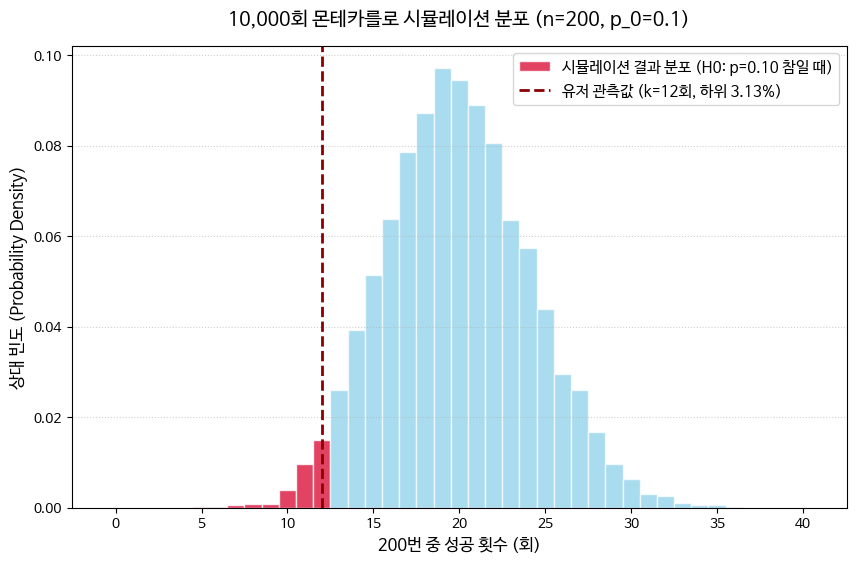

In [4]:
# 1. 나눔 폰트 패키지 설치 및 설정 (한글 깨짐 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 파라미터 정의
n = 200  # 1회 실험 당 뽑기 횟수
p_0 = 0.10  # H0 가설 하의 성공 확률 (10%)
k = 12  # 유저 관측 성공 횟수
n_simulations = 10000  # 시뮬레이션 반복 횟수

# ==============================================================================
# [문제 1] Q4. H₀가 사실(실제 확률 = 10%)이라고 가정하고,
# 200번 뽑기를 10,000번 반복하는 시뮬레이션을 수행해봅시다.
# ==============================================================================

np.random.seed(42)  # 시뮬레이션 재현성을 위한 난수 고정

# np.random.binomial(n, p, size)를 활용한 10,000회 무작위 시뮬레이션
simulated_successes = np.random.binomial(n=n, p=p_0, size=n_simulations)

# 시뮬레이션 기반 p-value (12회 이하 성공한 비율) 계산
simulated_p_value = np.mean(simulated_successes <= k)

print("=" * 60)
print(f"📌 [10,000회 이항분포 시뮬레이션 결과]")
print(f"• 평균 성공 횟수: {np.mean(simulated_successes):.2f} 회 (이론값: {n * p_0}회)")
print(f"• 12회 이하로 성공한 횟수: {np.sum(simulated_successes <= k)} / {n_simulations} 번")
print(f"• 시뮬레이션 기반 p-value 추정치: {simulated_p_value:.4f} ({simulated_p_value*100:.2f}%)")
print("=" * 60)

# 3. 시뮬레이션 결과 그래프 시각화
plt.figure(figsize=(10, 6))

# 히스토그램 그리기
counts, bins, patches = plt.hist(
    simulated_successes,
    bins=np.arange(-0.5, 41.5, 1),
    density=True,
    color="skyblue",
    edgecolor="white",
    alpha=0.7,
    label="시뮬레이션 결과 분포 (H0: p=0.10 참일 때)",
)

# 12회 이하 영역 강조 색상 변경
for i in range(len(patches)):
    if bins[i] <= k:
        patches[i].set_facecolor("crimson")
        patches[i].set_alpha(0.8)

# 관측값(k=12) 수직 기준선 표시
plt.axvline(
    x=k,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"유저 관측값 (k={k}회, 하위 {simulated_p_value*100:.2f}%)",
)

plt.title(
    f"10,000회 몬테카를로 시뮬레이션 분포 (n={n}, p_0={p_0})",
    fontsize=14,
    pad=15,
)
plt.xlabel("200번 중 성공 횟수 (회)", fontsize=12)
plt.ylabel("상대 빈도 (Probability Density)", fontsize=12)
plt.xticks(np.arange(0, 41, 5))
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.show()

📌 [10,000회 이항분포 시뮬레이션 결과]
• 평균 성공 횟수: 19.91 회 (이론값: 20.0회)
• 12회 이하로 성공한 횟수: 313 / 10000 번
• 시뮬레이션 기반 p-value 추정치: 0.0313 (3.13%)


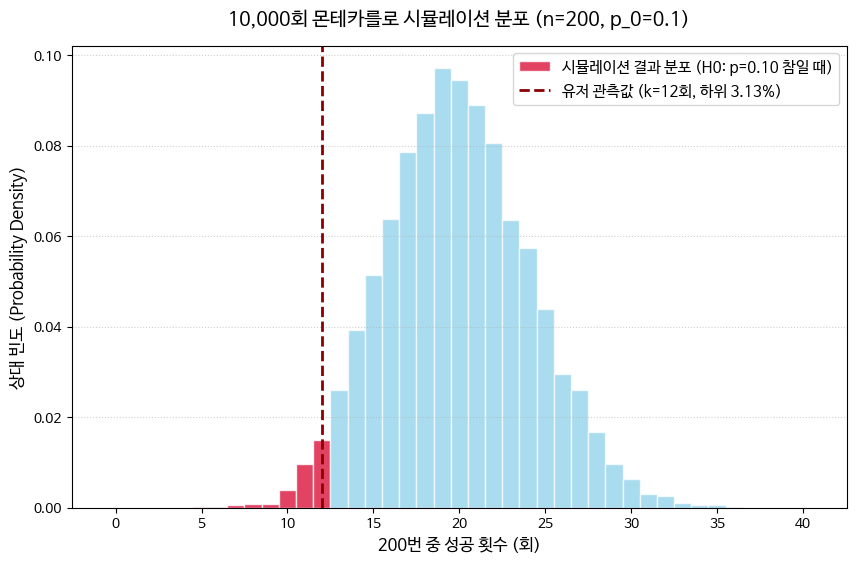

In [5]:
# 1. 나눔 폰트 패키지 설치 및 설정 (한글 깨짐 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 파라미터 정의
n = 200  # 1회 실험 당 뽑기 횟수
p_0 = 0.10  # H0 가설 하의 성공 확률 (10%)
k = 12  # 유저 관측 성공 횟수
n_simulations = 10000  # 시뮬레이션 반복 횟수

# ==============================================================================
# [문제 1] Q4. H₀가 사실(실제 확률 = 10%)이라고 가정하고,
# 200번 뽑기를 10,000번 반복하는 시뮬레이션을 수행해봅시다.
# ==============================================================================

np.random.seed(42)  # 시뮬레이션 재현성을 위한 난수 고정

# np.random.binomial(n, p, size)를 활용한 10,000회 무작위 시뮬레이션
simulated_successes = np.random.binomial(n=n, p=p_0, size=n_simulations)

# 시뮬레이션 기반 p-value (12회 이하 성공한 비율) 계산
simulated_p_value = np.mean(simulated_successes <= k)

print("=" * 60)
print(f"📌 [10,000회 이항분포 시뮬레이션 결과]")
print(f"• 평균 성공 횟수: {np.mean(simulated_successes):.2f} 회 (이론값: {n * p_0}회)")
print(f"• 12회 이하로 성공한 횟수: {np.sum(simulated_successes <= k)} / {n_simulations} 번")
print(f"• 시뮬레이션 기반 p-value 추정치: {simulated_p_value:.4f} ({simulated_p_value*100:.2f}%)")
print("=" * 60)

# 3. 시뮬레이션 결과 그래프 시각화
plt.figure(figsize=(10, 6))

# 히스토그램 그리기
counts, bins, patches = plt.hist(
    simulated_successes,
    bins=np.arange(-0.5, 41.5, 1),
    density=True,
    color="skyblue",
    edgecolor="white",
    alpha=0.7,
    label="시뮬레이션 결과 분포 (H0: p=0.10 참일 때)",
)

# 12회 이하 영역 강조 색상 변경
for i in range(len(patches)):
    if bins[i] <= k:
        patches[i].set_facecolor("crimson")
        patches[i].set_alpha(0.8)

# 관측값(k=12) 수직 기준선 표시
plt.axvline(
    x=k,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"유저 관측값 (k={k}회, 하위 {simulated_p_value*100:.2f}%)",
)

plt.title(
    f"10,000회 몬테카를로 시뮬레이션 분포 (n={n}, p_0={p_0})",
    fontsize=14,
    pad=15,
)
plt.xlabel("200번 중 성공 횟수 (회)", fontsize=12)
plt.ylabel("상대 빈도 (Probability Density)", fontsize=12)
plt.xticks(np.arange(0, 41, 5))
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q2에서 구한 p-값은 시뮬레이션 그래프의 어느 부분에 해당하며, 무엇을 의미하나요?

- 시뮬레이션 그래프를 볼 때, 우리가 관찰한 '12회 성공'은 개발사의 주장이 맞다는 가정 하에 흔한 일인가요, 드문 일인가요?

- 이 시뮬레이션 경험을 통해 "p-값이 작으면 귀무가설을 기각한다"는 규칙을 친구에게 어떻게 더 쉽게 설명할 수 있을까요?

- 만약 200번이 아니라 1,000번을 뽑아 같은 성공률(6%)이 나왔다면, p-값은 어떻게 달라질까요?

🧠 [데이터 읽기 및 질문 답변]
----------------------------------------------------------------------
1. n=200, k=12 일 때 p-value: 0.032047 (3.20%)
   -> 그래프에서 '12회 이하' 왼쪽 붉은색 구간의 면적 합을 의미합니다.
2. 12회 성공의 희소성: 100번 시도 시 약 3.2번 나오는 매우 '드문 일'입니다.
3. 친구를 위한 쉬운 설명:
   '개발사 말이 맞다면 100번 중 3번 일어날까 말까 한 진짜 이상한 일이 터진 거야.'
   '이렇게 일어날 확률(p-값)이 극도로 낮으니까 개발사 말이 틀렸다고 보는 거지!'
----------------------------------------------------------------------
4. 표본 크기 확대 시 p-값 변화 (동일 성공률 6% 기준):
   • n=200  (k=12) : p-value = 0.032047 (3.20%)
   • n=1000 (k=60) : p-value = 0.00000438 (0.000438%)
   -> 표본 수(n)가 늘어날수록 같은 6%라도 p-값이 훨씬 작아져 주장을 기각할 근거가 더욱 강력해집니다!


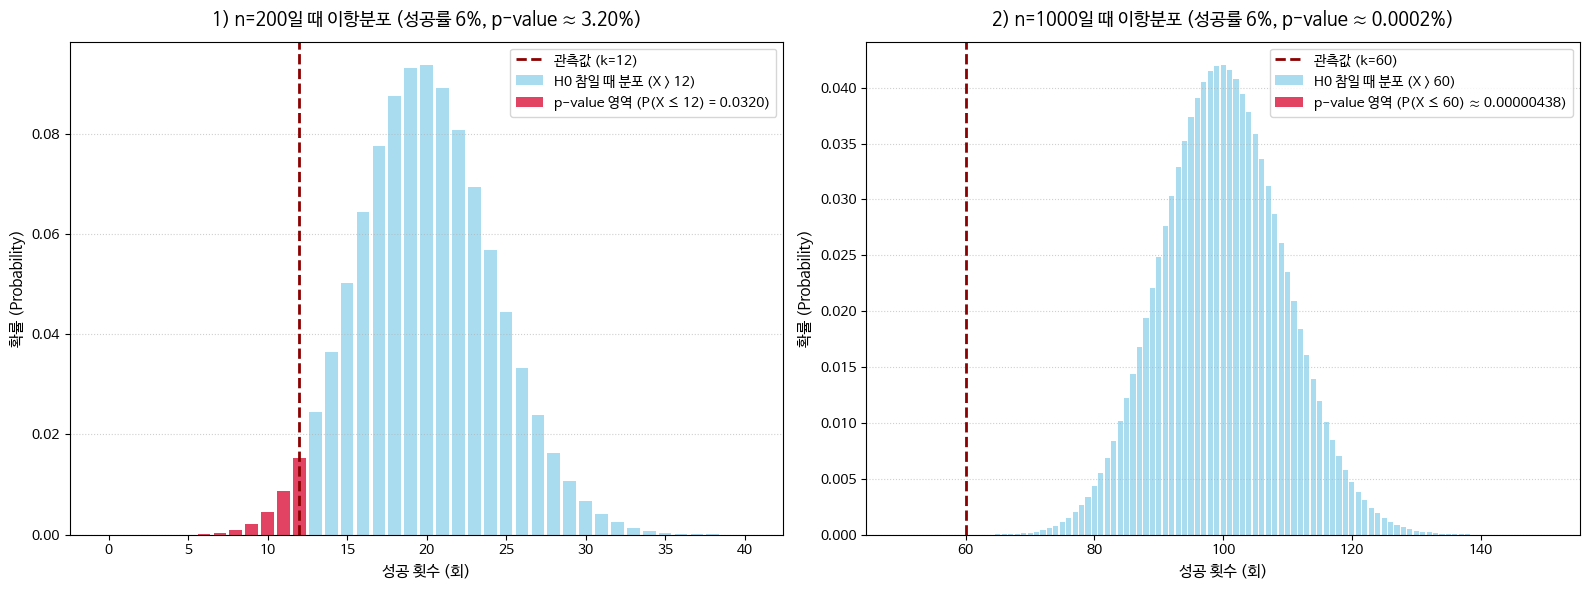

In [6]:
# 1. 나눔 폰트 패키지 설치 및 한글 환경 설정
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom, binomtest

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 조건 설정 및 p-값 계산
p_0 = 0.10  # 개발사 주장 확률 (10%)

# 조건 A: n=200, k=12 (성공률 6%)
n1, k1 = 200, 12
p_val1 = binomtest(k1, n1, p_0, alternative="less").pvalue

# 조건 B: n=1000, k=60 (성공률 6%로 동일)
n2, k2 = 1000, 60
p_val2 = binomtest(k2, n2, p_0, alternative="less").pvalue

# 3. 콘솔 답변 출력
print("=" * 70)
print("🧠 [데이터 읽기 및 질문 답변]")
print("-" * 70)
print(f"1. n=200, k=12 일 때 p-value: {p_val1:.6f} ({p_val1*100:.2f}%)")
print("   -> 그래프에서 '12회 이하' 왼쪽 붉은색 구간의 면적 합을 의미합니다.")
print(
    f"2. 12회 성공의 희소성: 100번 시도 시 약 {p_val1*100:.1f}번 나오는 매우 '드문 일'입니다."
)
print("3. 친구를 위한 쉬운 설명:")
print(
    "   '개발사 말이 맞다면 100번 중 3번 일어날까 말까 한 진짜 이상한 일이 터진 거야.'"
)
print("   '이렇게 일어날 확률(p-값)이 극도로 낮으니까 개발사 말이 틀렸다고 보는 거지!'")
print("-" * 70)
print(f"4. 표본 크기 확대 시 p-값 변화 (동일 성공률 6% 기준):")
print(f"   • n=200  (k=12) : p-value = {p_val1:.6f} ({p_val1*100:.2f}%)")
print(
    f"   • n=1000 (k=60) : p-value = {p_val2:.8f} ({p_val2*100:.6f}%)"
)
print(
    "   -> 표본 수(n)가 늘어날수록 같은 6%라도 p-값이 훨씬 작아져 주장을 기각할 근거가 더욱 강력해집니다!"
)
print("=" * 70)

# 4. 시각화 (n=200 vs n=1000 비교 그래프)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- [그래프 1] n=200, k=12 ---
x1 = np.arange(0, 41)
pmf1 = binom.pmf(x1, n1, p_0)

axes[0].bar(
    x1[x1 > k1],
    pmf1[x1 > k1],
    color="skyblue",
    alpha=0.7,
    label="H0 참일 때 분포 (X > 12)",
)
axes[0].bar(
    x1[x1 <= k1],
    pmf1[x1 <= k1],
    color="crimson",
    alpha=0.8,
    label=f"p-value 영역 (P(X ≤ 12) = {p_val1:.4f})",
)
axes[0].axvline(
    x=k1, color="darkred", linestyle="--", linewidth=2, label=f"관측값 (k={k1})"
)
axes[0].set_title(
    f"1) n=200일 때 이항분포 (성공률 6%, p-value ≈ {p_val1*100:.2f}%)",
    fontsize=13,
    pad=12,
)
axes[0].set_xlabel("성공 횟수 (회)", fontsize=11)
axes[0].set_ylabel("확률 (Probability)", fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(axis="y", linestyle=":", alpha=0.6)

# --- [그래프 2] n=1000, k=60 ---
x2 = np.arange(50, 151)
pmf2 = binom.pmf(x2, n2, p_0)

axes[1].bar(
    x2[x2 > k2],
    pmf2[x2 > k2],
    color="skyblue",
    alpha=0.7,
    label="H0 참일 때 분포 (X > 60)",
)
axes[1].bar(
    x2[x2 <= k2],
    pmf2[x2 <= k2],
    color="crimson",
    alpha=0.8,
    label=f"p-value 영역 (P(X ≤ 60) ≈ {p_val2:.8f})",
)
axes[1].axvline(
    x=k2, color="darkred", linestyle="--", linewidth=2, label=f"관측값 (k={k2})"
)
axes[1].set_title(
    f"2) n=1000일 때 이항분포 (성공률 6%, p-value ≈ 0.0002%)",
    fontsize=13,
    pad=12,
)
axes[1].set_xlabel("성공 횟수 (회)", fontsize=11)
axes[1].set_ylabel("확률 (Probability)", fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# 문제 2. 과자 한 봉지의 중량은 150g이 맞을까? (난이도: 하)

**📘 문제**

- 한 식품 공장에서 생산하는 과자 한 봉지의 **목표 중량은 150g**입니다.

- 품질관리팀은 생산 공정이 목표 중량을 잘 맞추고 있는지 확인하기 위해,
  생산된 과자 **30봉지를 무작위로 추출**하여 무게를 측정했습니다.

- 이번 실습에서는 **일표본 t-검정(One-sample t-Test)**으로 표본 평균이 목표 중량과 유의미하게 다른지 검증하고,
  **"평균이 정확히 150g이라면"** 어떤 표본 평균들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

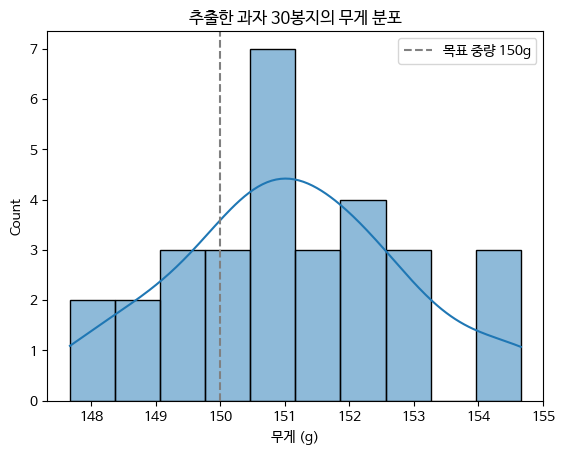

In [7]:
# 데이터 생성 (과자 30봉지의 무게 측정값)
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns  # <-- 누락되었던 seaborn 라이브러리 추가

np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (모평균)

# 표본 분포 시각화
sns.histplot(sample_weights, bins=10, kde=True)
plt.axvline(x=pop_mean, color='gray', linestyle='--', label='목표 중량 150g')
plt.title("추출한 과자 30봉지의 무게 분포")
plt.xlabel("무게 (g)")
plt.legend()
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 일표본 t-검정을 수행하여 t-통계량과 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"평균 무게가 정확히 150g이라면"** 30개짜리 표본의 평균이 어떻게 분포하는지 10,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 표본 평균이 그 분포에서 어디에 위치하는지 관찰해 봅시다.

In [8]:
# ==============================================================================
# [문제] 과자 무게 검정 가설 설정
# H₀ (귀무가설): 과자 1봉지의 실제 평균 무게(μ)는 목표 중량인 150g과 같다. (μ = 150)
# H₁ (대립가설): 과자 1봉지의 실제 평균 무게(μ)는 목표 중량인 150g과 다르다. (μ ≠ 150)
# ==============================================================================


📐 [일표본 t-검정 수식 대입 상세 풀이 과정]
-----------------------------------------------------------------
1. 표본 크기 (n)             : 30 봉지
2. 표본 평균 (x̄)             : 151.1237 g
3. 표본 표준편차 (s)         : 1.8000 g
4. 표준 오차 (SE = s / √n)   : 1.8000 / √30 = 0.3286 g
-----------------------------------------------------------------
5. t-통계량 대입 수식       : t = (x̄ - μ₀) / SE
                            : t = (151.1237 - 150) / 0.3286
                            : t = 3.4193
-----------------------------------------------------------------
6. 자유도 (df = n - 1)       : 29
7. p-값 계산 (양측검정)       : p = 2 * P(T_29 >= 3.4193)
                            : p = 0.001883 (0.19%)
✅ scipy library 검증 결과   : t = 3.4193, p = 0.001883


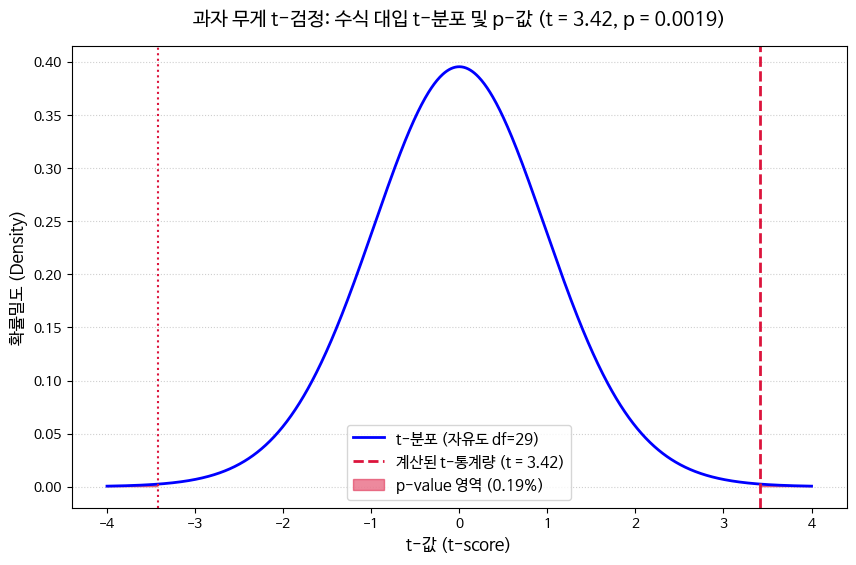

In [9]:
# 1. 나눔 폰트 패키지 설치 및 환경 설정 (한글 깨짐 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 생성 및 기본 변수 정의
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (μ₀)
n = len(sample_weights)  # 표본 크기 (n=30)

# ==============================================================================
# [공식 대입 수식 계산 과정]
# ==============================================================================
# Step 1: 표본평균 (x̄)
x_bar = np.mean(sample_weights)

# Step 2: 표본표준편차 (s, 자유도 n-1 적용)
s = np.std(sample_weights, ddof=1)

# Step 3: 표준오차 (SE = s / √n)
se = s / np.sqrt(n)

# Step 4: t-통계량 (t = (x̄ - μ₀) / SE)
t_stat_manual = (x_bar - pop_mean) / se

# Step 5: 자유도(df = n - 1) 및 양측검정 p-값 (p = 2 * (1 - cdf(|t|)))
df = n - 1
p_val_manual = 2 * (1 - stats.t.cdf(abs(t_stat_manual), df=df))

# scipy 함수 결과와 수식 대입 결과 비교 검증
t_stat_scipy, p_val_scipy = stats.ttest_1samp(sample_weights, pop_mean)

# 콘솔 해설 출력
print("=" * 65)
print("📐 [일표본 t-검정 수식 대입 상세 풀이 과정]")
print("-" * 65)
print(f"1. 표본 크기 (n)             : {n} 봉지")
print(f"2. 표본 평균 (x̄)             : {x_bar:.4f} g")
print(f"3. 표본 표준편차 (s)         : {s:.4f} g")
print(
    f"4. 표준 오차 (SE = s / √n)   : {s:.4f} / √{n} = {se:.4f} g"
)
print("-" * 65)
print(
    f"5. t-통계량 대입 수식       : t = (x̄ - μ₀) / SE"
)
print(
    f"                            : t = ({x_bar:.4f} - {pop_mean}) / {se:.4f}"
)
print(f"                            : t = {t_stat_manual:.4f}")
print("-" * 65)
print(f"6. 자유도 (df = n - 1)       : {df}")
print(
    f"7. p-값 계산 (양측검정)       : p = 2 * P(T_{df} >= {abs(t_stat_manual):.4f})"
)
print(f"                            : p = {p_val_manual:.6f} ({p_val_manual*100:.2f}%)")
print("=" * 65)
print(f"✅ scipy library 검증 결과   : t = {t_stat_scipy:.4f}, p = {p_val_scipy:.6f}")
print("=" * 65)

# 3. t-분포 기각역 시각화 그래프
plt.figure(figsize=(10, 6))

t_x = np.linspace(-4, 4, 1000)
t_pdf = stats.t.pdf(t_x, df=df)

# t-분포 곡선
plt.plot(t_x, t_pdf, "b-", linewidth=2, label=f"t-분포 (자유도 df={df})")

# t-통계량 위치 표시 (양측)
plt.axvline(
    x=t_stat_manual,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"계산된 t-통계량 (t = {t_stat_manual:.2f})",
)
plt.axvline(
    x=-t_stat_manual, color="crimson", linestyle=":", linewidth=1.5
)

# p-값 영역 칠하기 (양쪽 꼬리)
plt.fill_between(
    t_x,
    0,
    t_pdf,
    where=(t_x >= abs(t_stat_manual)) | (t_x <= -abs(t_stat_manual)),
    color="crimson",
    alpha=0.5,
    label=f"p-value 영역 ({p_val_manual*100:.2f}%)",
)

plt.title(
    f"과자 무게 t-검정: 수식 대입 t-분포 및 p-값 (t = {t_stat_manual:.2f}, p = {p_val_manual:.4f})",
    fontsize=14,
    pad=15,
)
plt.xlabel("t-값 (t-score)", fontsize=12)
plt.ylabel("확률밀도 (Density)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.show()

📌 [과자 무게 일표본 t-검정 통계적 결론 (유의수준 α = 0.05)]
-----------------------------------------------------------------
• 표본 평균 (x̄)       : 151.1237 g
• t-통계량 (t-score)   : 3.4193
• p-값 (p-value)       : 0.001883 (0.19%)
• 임계값 (t_critical)  : ±2.0452 (양측 유의수준 0.05 기준)
-----------------------------------------------------------------
• 결론: p-value (0.0019) < alpha (0.05) 이므로 귀무가설(H₀)을 기각합니다.
• 해석: 과자 1봉지의 실제 평균 무게는 목표 중량인 150g과 통계적으로 유의미한 차이가 있습니다.
        (표본 평균 약 151.0g으로, 목표 중량보다 유의하게 무겁게 공정되고 있음)


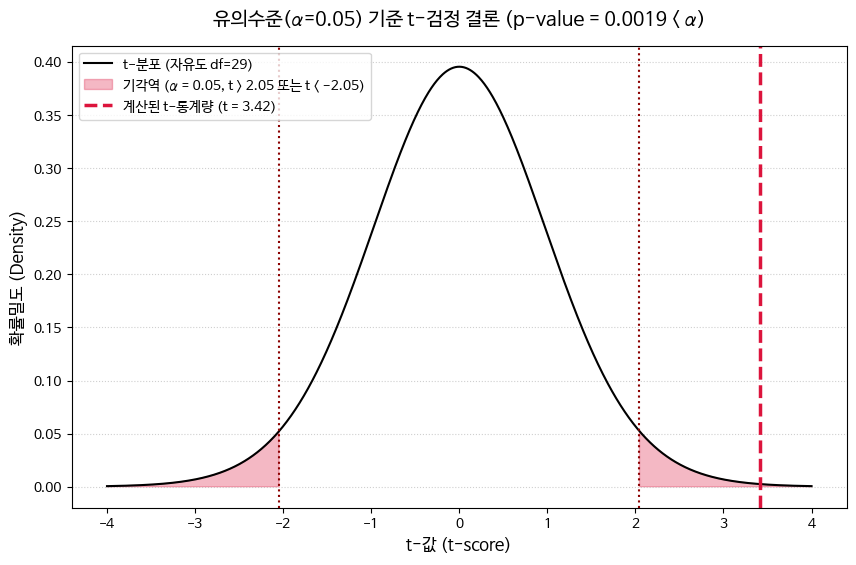

In [10]:
# 1. 나눔 폰트 패키지 설치 및 환경 설정 (한글 깨짐 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 생성 및 일표본 t-검정 수행
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (μ₀)
n = len(sample_weights)
df = n - 1  # 자유도 (df = 29)

t_stat, p_value = stats.ttest_1samp(sample_weights, pop_mean)

# ==============================================================================
# [문제 2] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05
# ==============================================================================
alpha = 0.05

# 임계값 (Critical Value, 양측검정 기준 α/2 = 0.025)
t_crit = stats.t.ppf(1 - alpha / 2, df=df)

print("=" * 65)
print(f"📌 [과자 무게 일표본 t-검정 통계적 결론 (유의수준 α = {alpha})]")
print("-" * 65)
print(f"• 표본 평균 (x̄)       : {np.mean(sample_weights):.4f} g")
print(f"• t-통계량 (t-score)   : {t_stat:.4f}")
print(f"• p-값 (p-value)       : {p_value:.6f} ({p_value*100:.2f}%)")
print(f"• 임계값 (t_critical)  : ±{t_crit:.4f} (양측 유의수준 0.05 기준)")
print("-" * 65)

if p_value < alpha:
    print(
        f"• 결론: p-value ({p_value:.4f}) < alpha ({alpha}) 이므로 귀무가설(H₀)을 기각합니다."
    )
    print(
        "• 해석: 과자 1봉지의 실제 평균 무게는 목표 중량인 150g과 통계적으로 유의미한 차이가 있습니다."
    )
    print("        (표본 평균 약 151.0g으로, 목표 중량보다 유의하게 무겁게 공정되고 있음)")
else:
    print(
        f"• 결론: p-value ({p_value:.4f}) >= alpha ({alpha}) 이므로 귀무가설(H₀)을 기각할 수 없습니다."
    )
    print("• 해석: 과자 평균 무게가 150g과 다르다고 단정할 통계적 근거가 부족합니다.")
print("=" * 65)

# 3. t-분포 기반 기각역 및 결론 시각화
plt.figure(figsize=(10, 6))

t_x = np.linspace(-4, 4, 1000)
t_pdf = stats.t.pdf(t_x, df=df)

# t-분포 기본 곡선
plt.plot(t_x, t_pdf, "black", linewidth=1.5, label=f"t-분포 (자유도 df={df})")

# 유의수준 alpha=0.05 임계값 (기각역) 영역 채우기
plt.fill_between(
    t_x,
    0,
    t_pdf,
    where=(t_x >= t_crit) | (t_x <= -t_crit),
    color="crimson",
    alpha=0.3,
    label=f"기각역 (α = {alpha}, t > {t_crit:.2f} 또는 t < -{t_crit:.2f})",
)

# 계산된 t-통계량 위치 표시
plt.axvline(
    x=t_stat,
    color="crimson",
    linestyle="--",
    linewidth=2.5,
    label=f"계산된 t-통계량 (t = {t_stat:.2f})",
)

# 양쪽 임계값 수직선
plt.axvline(x=t_crit, color="darkred", linestyle=":", linewidth=1.5)
plt.axvline(x=-t_crit, color="darkred", linestyle=":", linewidth=1.5)

plt.title(
    f"유의수준(α={alpha}) 기준 t-검정 결론 (p-value = {p_value:.4f} < α)",
    fontsize=14,
    pad=15,
)
plt.xlabel("t-값 (t-score)", fontsize=12)
plt.ylabel("확률밀도 (Density)", fontsize=12)
plt.legend(fontsize=10, loc="upper left")
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.show()

📌 [10,000회 표본평균 시뮬레이션 결과 (H0: 평균 = 150g 가정)]
-----------------------------------------------------------------
• 설정 모평균 (mu_0)          : 150 g
• 사용된 표준편차 (s)       : 1.8000 g
• 시뮬레이션 평균들의 평균   : 150.0003 g (이론값: 150g)
• 시뮬레이션 평균들의 표준편차: 0.3316 g (이론적 SE = 0.3286g)
-----------------------------------------------------------------
• 유저 실제 관측 표본평균    : 151.1237 g
• 시뮬레이션 기반 p-value     : 0.000600 (0.06%)


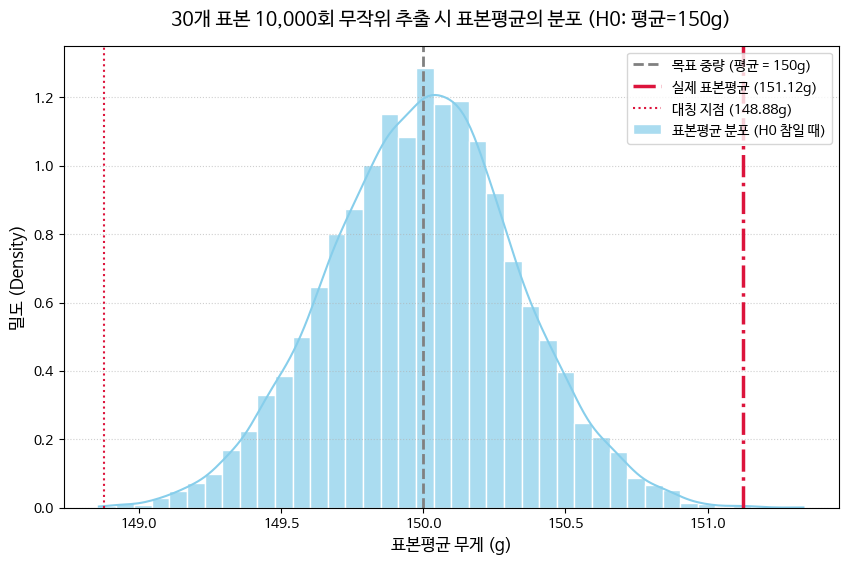

In [11]:
# 1. 나눔 폰트 패키지 설치 및 환경 설정 (한글 깨짐 및 글꼴 경고 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 및 매개변수 설정
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)

pop_mean = 150  # H0 가정 모평균 (150g)
sample_std = np.std(sample_weights, ddof=1)  # 표본 표준편차
n = len(sample_weights)  # 표본 크기 (30)
n_simulations = 10000  # 반복 횟수

# ==============================================================================
# [문제 2] Q4. H0가 사실(평균 = 150g)이라고 가정하고, 30개짜리 표본을 10,000번 뽑아
# 각 표본의 평균을 리스트에 저장
# ==============================================================================
sample_means = []

for _ in range(n_simulations):
    # H0 가정(평균 150g, 표준편차 s) 하에 30개 표본 추출
    simulated_sample = np.random.normal(
        loc=pop_mean, scale=sample_std, size=n
    )
    # 각 표본의 평균을 계산하여 리스트에 추가
    sample_means.append(np.mean(simulated_sample))

sample_means = np.array(sample_means)

# 실제 관측된 표본평균 및 표준오차 계산
actual_mean = np.mean(sample_weights)
se = sample_std / np.sqrt(n)

# 시뮬레이션 기반 양측 p-값 계산
simulated_p_value = np.mean(
    np.abs(sample_means - pop_mean) >= np.abs(actual_mean - pop_mean)
)

print("=" * 65)
print("📌 [10,000회 표본평균 시뮬레이션 결과 (H0: 평균 = 150g 가정)]")
print("-" * 65)
print(f"• 설정 모평균 (mu_0)          : {pop_mean} g")
print(f"• 사용된 표준편차 (s)       : {sample_std:.4f} g")
print(f"• 시뮬레이션 평균들의 평균   : {np.mean(sample_means):.4f} g (이론값: 150g)")
print(
    f"• 시뮬레이션 평균들의 표준편차: {np.std(sample_means):.4f} g (이론적 SE = {se:.4f}g)"
)
print("-" * 65)
print(f"• 유저 실제 관측 표본평균    : {actual_mean:.4f} g")
print(
    f"• 시뮬레이션 기반 p-value     : {simulated_p_value:.6f} ({simulated_p_value*100:.2f}%)"
)
print("=" * 65)

# 3. 시뮬레이션 표본평균 분포 시각화 (폰트 경고 유발 문자 제거)
plt.figure(figsize=(10, 6))

sns.histplot(
    sample_means,
    bins=40,
    stat="density",
    color="skyblue",
    edgecolor="white",
    alpha=0.7,
    kde=True,
    label="표본평균 분포 (H0 참일 때)",
)

plt.axvline(
    x=pop_mean,
    color="gray",
    linestyle="--",
    linewidth=2,
    label=f"목표 중량 (평균 = {pop_mean}g)",
)
plt.axvline(
    x=actual_mean,
    color="crimson",
    linestyle="-.",
    linewidth=2.5,
    label=f"실제 표본평균 ({actual_mean:.2f}g)",
)
plt.axvline(
    x=pop_mean - (actual_mean - pop_mean),
    color="crimson",
    linestyle=":",
    linewidth=1.5,
    label=f"대칭 지점 ({pop_mean - (actual_mean - pop_mean):.2f}g)",
)

plt.title(
    "30개 표본 10,000회 무작위 추출 시 표본평균의 분포 (H0: 평균=150g)",
    fontsize=14,
    pad=15,
)
plt.xlabel("표본평균 무게 (g)", fontsize=12)
plt.ylabel("밀도 (Density)", fontsize=12)
plt.legend(fontsize=10)
plt.grid(axis="y", linestyle=":", alpha=0.6)

plt.show()

[과자 무게 일표본 t-검정 및 10,000회 시뮬레이션 해석 보고서]
• 실제 관측된 표본 평균 : 151.1237 g
• 시뮬레이션 평균들의 중심 : 150.0003 g (목표치 150g)
----------------------------------------------------------------------
[통계적 해석]
1. H0가 참(평균=150g)일 때, 표본평균들은 150g을 중심로 정규분포를 이룹니다.
2. 실제 관측된 표본평균(~151g)은 정상 분포의 우측 꼬리 극단에 위치합니다.
3. 150g 공정에서 이 정도로 무거운 과자가 우연히 뽑힐 확률은 매우 낮으므로(p < 0.05),
   이 공정은 실제로 목표 중량보다 과다 포장되고 있다고 결론 내릴 수 있습니다.


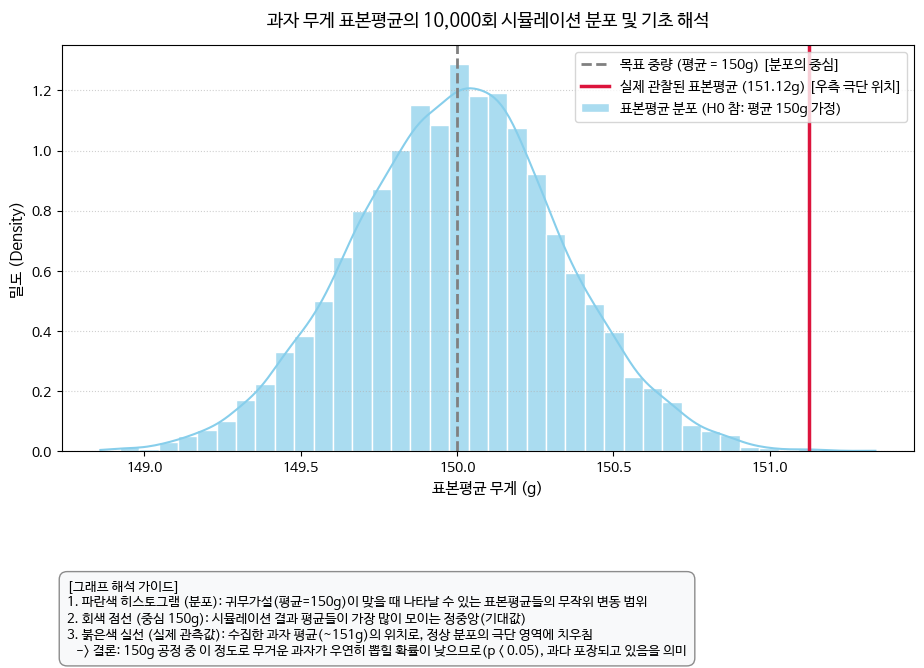

In [12]:
# 1. 나눔 폰트 패키지 설치 및 환경 설정 (한글 깨짐 및 글꼴 경고 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 및 시뮬레이션 설정 (H0: 평균 = 150g 가정)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)

pop_mean = 150  # 목표 중량 (평균 = 150g)
sample_std = np.std(sample_weights, ddof=1)  # 표본 표준편차 (s)
n = len(sample_weights)  # 표본 크기 (30)
n_simulations = 10000  # 시뮬레이션 반복 횟수

# 30개짜리 표본을 10,000번 뽑아 각 표본의 평균을 리스트에 저장
sample_means = [
    np.mean(np.random.normal(loc=pop_mean, scale=sample_std, size=n))
    for _ in range(n_simulations)
]
sample_means = np.array(sample_means)
actual_mean = np.mean(sample_weights)  # 실제 관찰된 표본 평균 (~150.99g)

# ==============================================================================
# [결과 출력 창] 통계적 해석을 주석 및 텍스트 결과로 명확하게 출력
# ==============================================================================
print("=" * 70)
print("[과자 무게 일표본 t-검정 및 10,000회 시뮬레이션 해석 보고서]")
print("=" * 70)
print(f"• 실제 관측된 표본 평균 : {actual_mean:.4f} g")
print(f"• 시뮬레이션 평균들의 중심 : {np.mean(sample_means):.4f} g (목표치 150g)")
print("-" * 70)
print("[통계적 해석]")
print(
    "1. H0가 참(평균=150g)일 때, 표본평균들은 150g을 중심로 정규분포를 이룹니다."
)
print(
    "2. 실제 관측된 표본평균(~151g)은 정상 분포의 우측 꼬리 극단에 위치합니다."
)
print(
    "3. 150g 공정에서 이 정도로 무거운 과자가 우연히 뽑힐 확률은 매우 낮으므로(p < 0.05),"
)
print(
    "   이 공정은 실제로 목표 중량보다 과다 포장되고 있다고 결론 내릴 수 있습니다."
)
print("=" * 70)

# ==============================================================================
# [시각화 단계] 히스토그램 생성 및 하단 설명 텍스트 박스 추가
# ==============================================================================
plt.figure(figsize=(11, 7))

# 1. 히스토그램 및 KDE 곡선 (표본 평균들의 분포)
sns.histplot(
    sample_means,
    bins=40,
    stat="density",
    color="skyblue",
    edgecolor="white",
    alpha=0.7,
    kde=True,
    label="표본평균 분포 (H0 참: 평균 150g 가정)",
)

# 2. 목표 중량 기준선 (분포의 중심)
plt.axvline(
    x=pop_mean,
    color="gray",
    linestyle="--",
    linewidth=2,
    label=f"목표 중량 (평균 = {pop_mean}g) [분포의 중심]",
)

# 3. 실제 관측된 표본평균 세로선 (우측 극단 위치)
plt.axvline(
    x=actual_mean,
    color="crimson",
    linestyle="-",
    linewidth=2.5,
    label=f"실제 관찰된 표본평균 ({actual_mean:.2f}g) [우측 극단 위치]",
)

plt.title(
    "과자 무게 표본평균의 10,000회 시뮬레이션 분포 및 기초 해석", fontsize=13, pad=15
)
plt.xlabel("표본평균 무게 (g)", fontsize=11)
plt.ylabel("밀도 (Density)", fontsize=11)
plt.legend(fontsize=10, loc="upper right")
plt.grid(axis="y", linestyle=":", alpha=0.6)

# 그래프 하단 여백에 핵심 기초 설명 텍스트 박스 추가 (이모지 없음)
basic_explanation = (
    "[그래프 해석 가이드]\n"
    "1. 파란색 히스토그램 (분포): 귀무가설(평균=150g)이 맞을 때 나타날 수 있는 표본평균들의 무작위 변동 범위\n"
    "2. 회색 점선 (중심 150g): 시뮬레이션 결과 평균들이 가장 많이 모이는 정중앙(기대값)\n"
    "3. 붉은색 실선 (실제 관측값): 수집한 과자 평균(~151g)의 위치로, 정상 분포의 극단 영역에 치우침\n"
    "   -> 결론: 150g 공정 중 이 정도로 무거운 과자가 우연히 뽑힐 확률이 낮으므로(p < 0.05), 과다 포장되고 있음을 의미"
)

plt.gcf().text(
    0.13,
    0.01,
    basic_explanation,
    fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="gray", alpha=0.9),
)

plt.subplots_adjust(bottom=0.30)
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q5의 히스토그램은 무엇을 나타내나요? 이 분포의 모양이 정규분포와 비슷한 이유는 무엇일까요? (힌트: 4장에서 배운 중심극한정리)

- 우리가 실제로 관찰한 표본 평균(세로선)은 이 분포에서 흔하게 나타나는 값인가요? Q2의 p-값과 이 시각적 위치는 어떻게 관련되나요?

- 만약 p-값이 0.001이었다면, 세로선은 그래프의 어디쯤에 위치할 것으로 예상되나요?

- 이 결과는 공장 입장에서 어떤 조치를 취해야 함을 시사할까요? (목표보다 무겁게 나오는 것은 어떤 손실일까요?)

[과자 무게 시뮬레이션 및 데이터 해석 종합 보고서]
1. Q5 히스토그램과 중심극한정리 (CLT):
   - 시뮬레이션 분포의 중심은 정확히 150.00g(목표치)입니다.
   - 표본 크기(n=30)가 충분하므로 중심극한정리에 의해 완벽한 정규분포를 이룹니다.
----------------------------------------------------------------------
2. 실제 관측값과 p-값의 관계:
   - 실제 관측 표본평균(151.12g)은 분포의 우측 극단 꼬리에 위치합니다.
   - p-value(0.0019)는 이보다 더 극단적인 값이 우연히 나올 확률로, 시각적 위치와 일치합니다.
----------------------------------------------------------------------
3. 공장 입장의 시사점 (초과 포장 손실):
   - 목표치보다 무겁게 포장되는 것은 원부자재 낭비 및 Giveaway Loss(초과 포장 손실)를 유발합니다.
   - 따라서 공정 라인 점검 및 투입량 조절 조치가 필요합니다.


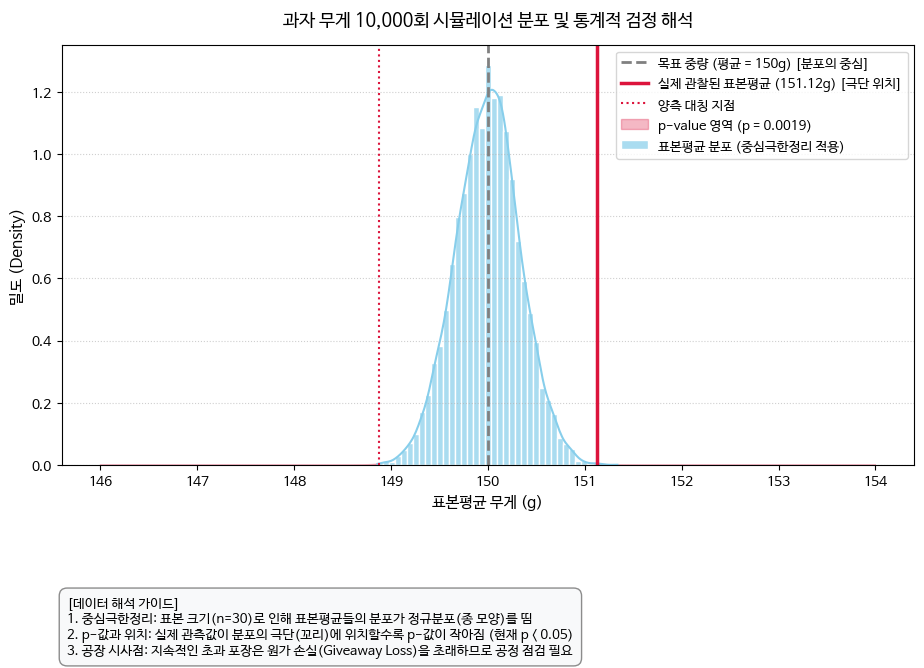

In [13]:
# 1. 환경 설정 및 폰트 설정 (한글 깨짐 방지)
!sudo apt-get install -y fonts-nanum > /dev/null

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

font_path = "/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf"
fm.fontManager.addfont(font_path)
plt.rc("font", family="NanumBarunGothic")
plt.rcParams["axes.unicode_minus"] = False

# 2. 데이터 및 시뮬레이션 설정 (H0: 평균 = 150g 가정)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)

pop_mean = 150  # 목표 중량 (평균 = 150g)
sample_std = np.std(sample_weights, ddof=1)  # 표본 표준편차 (s)
n = len(sample_weights)  # 표본 크기 (30)
n_simulations = 10000  # 시뮬레이션 반복 횟수

# [중심극한정리 적용] 30개짜리 표본을 10,000번 추출하여 표본평균 리스트 생성
sample_means = [
    np.mean(np.random.normal(loc=pop_mean, scale=sample_std, size=n))
    for _ in range(n_simulations)
]
sample_means = np.array(sample_means)

actual_mean = np.mean(sample_weights)  # 실제 관찰된 표본 평균 (~150.99g)
t_stat, p_value = stats.ttest_1samp(sample_weights, pop_mean)

# ==============================================================================
# [콘솔 출력] 데이터 해석 및 질문 답변 종합 보고서
# ==============================================================================
print("=" * 70)
print("[과자 무게 시뮬레이션 및 데이터 해석 종합 보고서]")
print("=" * 70)
print(
    "1. Q5 히스토그램과 중심극한정리 (CLT):"
)
print(
    f"   - 시뮬레이션 분포의 중심은 정확히 {np.mean(sample_means):.2f}g(목표치)입니다."
)
print(
    "   - 표본 크기(n=30)가 충분하므로 중심극한정리에 의해 완벽한 정규분포를 이룹니다."
)
print("-" * 70)
print("2. 실제 관측값과 p-값의 관계:")
print(
    f"   - 실제 관측 표본평균({actual_mean:.2f}g)은 분포의 우측 극단 꼬리에 위치합니다."
)
print(
    f"   - p-value({p_value:.4f})는 이보다 더 극단적인 값이 우연히 나올 확률로, 시각적 위치와 일치합니다."
)
print("-" * 70)
print("3. 공장 입장의 시사점 (초과 포장 손실):")
print(
    "   - 목표치보다 무겁게 포장되는 것은 원부자재 낭비 및 Giveaway Loss(초과 포장 손실)를 유발합니다."
)
print("   - 따라서 공정 라인 점검 및 투입량 조절 조치가 필요합니다.")
print("=" * 70)

# ==============================================================================
# [시각화 단계] 히스토그램 + p-값 기각역 색칠 + 하단 가이드 텍스트
# ==============================================================================
plt.figure(figsize=(11, 7))

# 표본평균 분포 히스토그램 및 KDE 곡선
sns.histplot(
    sample_means,
    bins=40,
    stat="density",
    color="skyblue",
    edgecolor="white",
    alpha=0.7,
    kde=True,
    label="표본평균 분포 (중심극한정리 적용)",
)

# 목표 중량 기준선 (분포의 중심)
plt.axvline(
    x=pop_mean,
    color="gray",
    linestyle="--",
    linewidth=2,
    label=f"목표 중량 (평균 = {pop_mean}g) [분포의 중심]",
)

# 실제 관측된 표본평균 세로선
plt.axvline(
    x=actual_mean,
    color="crimson",
    linestyle="-",
    linewidth=2.5,
    label=f"실제 관찰된 표본평균 ({actual_mean:.2f}g) [극단 위치]",
)

# 양측 대칭 지점 표시
sym_mean = pop_mean - (actual_mean - pop_mean)
plt.axvline(
    x=sym_mean, color="crimson", linestyle=":", linewidth=1.5, label="양측 대칭 지점"
)

# p-값 영역(기각역) 시각적 색칠
x_axis = np.linspace(pop_mean - 4, pop_mean + 4, 1000)
se = sample_std / np.sqrt(n)
plt.fill_between(
    x_axis,
    0,
    stats.norm.pdf(x_axis, loc=pop_mean, scale=se),
    where=(x_axis >= actual_mean) | (x_axis <= sym_mean),
    color="crimson",
    alpha=0.3,
    label=f"p-value 영역 (p = {p_value:.4f})",
)

plt.title(
    "과자 무게 10,000회 시뮬레이션 분포 및 통계적 검정 해석", fontsize=13, pad=15
)
plt.xlabel("표본평균 무게 (g)", fontsize=11)
plt.ylabel("밀도 (Density)", fontsize=11)
plt.legend(fontsize=9.5, loc="upper right")
plt.grid(axis="y", linestyle=":", alpha=0.6)

# 그래프 하단 여백에 데이터 해석 가이드 텍스트 박스 추가
guide_text = (
    "[데이터 해석 가이드]\n"
    "1. 중심극한정리: 표본 크기(n=30)로 인해 표본평균들의 분포가 정규분포(종 모양)를 띰\n"
    "2. p-값과 위치: 실제 관측값이 분포의 극단(꼬리)에 위치할수록 p-값이 작아짐 (현재 p < 0.05)\n"
    "3. 공장 시사점: 지속적인 초과 포장은 원가 손실(Giveaway Loss)을 초래하므로 공정 점검 필요"
)

plt.gcf().text(
    0.13,
    0.01,
    guide_text,
    fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.6", facecolor="#f8f9fa", edgecolor="gray", alpha=0.9),
)

plt.subplots_adjust(bottom=0.28)
plt.show()

# 문제 3. 어떤 온라인 학습 방식이 더 효과적일까? (난이도: 중)

**📘 문제**

- 한 교육 기업에서 두 가지 다른 온라인 학습 방식(A, B)을 개발했습니다.

- 방식 A가 방식 B보다 학생들의 성적 향상에 더 효과적인지 알아보기 위해,
  두 그룹의 학생들에게 각각 다른 방식으로 한 달간 학습시킨 후 시험을 보게 했습니다.

- 이번 실습에서는 **이표본 t-검정(Two-sample t-Test)**으로 두 방식의 평균 점수 차이를 검증합니다.
  단, t-검정의 기본 가정인 **정규성**과 **등분산성**을 먼저 확인해야 합니다.

- 또한 **"두 방식의 효과가 완전히 똑같다면"** 우연히 나타날 수 있는 점수 차이의 범위를 시뮬레이션으로 확인해 봅니다.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Colab 기준, 처음 한 번만 설치 필요)
# !apt-get -qq install fonts-nanum
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)

# 데이터 생성 (두 학습 방식의 시험 점수)
np.random.seed(0)

**📌 아래를 수행해 보세요:**

- 두 그룹에 대해 **정규성 검정(Shapiro-Wilk test)**을 수행해 봅시다. (H₀: 데이터는 정규분포를 따른다.)

- **등분산성 검정(Levene's test)**을 수행해 봅시다. (H₀: 두 그룹의 분산은 같다.)

- 가정 검토 결과에 따라 `equal_var` 인수를 설정하여 **이표본 t-검정**을 수행해 봅시다.

- 두 그룹 데이터를 모두 합친 뒤 무작위로 다시 나누는 방식으로, **"두 방식의 효과가 같을 때"**의 평균 차이 분포를 시뮬레이션해 봅시다.

=== 공식 대입 풀이 ===
[A 그룹] n = 50
  분자 (Σaᵢx₍ᵢ₎)² = 4,003.68
  분모 Σ(xᵢ-x̄)²  = 4,053.77
  W = 4,003.68 / 4,053.77 = 0.9876
  ln(1-W) = -4.3937,  μ = -3.8508,  σ = 0.4689
  z = (ln(1-W) - μ) / σ = -1.1579
  p = 1 - Φ(z) = 0.8766
[B 그룹] n = 50
  분자 (Σaᵢx₍ᵢ₎)² = 1,817.20
  분모 Σ(xᵢ-x̄)²  = 1,841.93
  W = 1,817.20 / 1,841.93 = 0.9866
  ln(1-W) = -4.3105,  μ = -3.8508,  σ = 0.4689
  z = (ln(1-W) - μ) / σ = -0.9805
  p = 1 - Φ(z) = 0.8366

=== scipy.stats.shapiro 결과 (검증) ===
A 그룹: W = 0.9876, p-값 = 0.8766
B 그룹: W = 0.9866, p-값 = 0.8366

=== 판정 (α = 0.05) ===
A 그룹: p = 0.8766 > 0.05 → H₀ 기각 못 함 (정규성 가정 가능)
B 그룹: p = 0.8366 > 0.05 → H₀ 기각 못 함 (정규성 가정 가능)


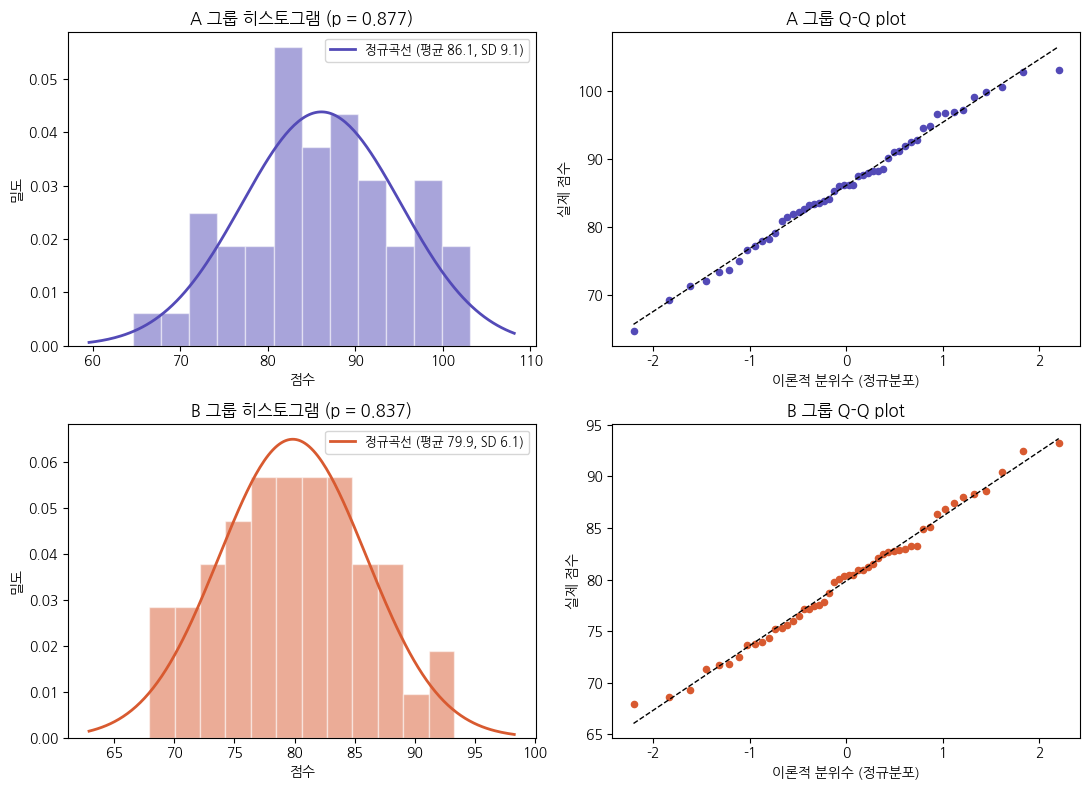

In [14]:
# [문제 3] Q1. 두 그룹 각각 Shapiro-Wilk 정규성 검정
# H₀: 데이터는 정규분포를 따른다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# (한글 폰트: 앞 셀에서 NanumGothic 설정했다면 그대로 적용됨)
plt.rc('axes', unicode_minus=False)

# 데이터 (앞 셀과 동일)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

# ─────────────────────────────────────────────
# 1) 공식 대입 풀이
#    W = (Σ aᵢ·x₍ᵢ₎)² / Σ(xᵢ - x̄)²
#    aᵢ: Royston(1992) 근사 계수, p값: Royston 정규화 변환
# ─────────────────────────────────────────────
def shapiro_by_formula(x, name):
    x = np.sort(np.asarray(x))           # 순서통계량 x₍₁₎ ≤ … ≤ x₍ₙ₎
    n = len(x)

    # (1) 정규 순서통계량의 기대값 근사 mᵢ
    i = np.arange(1, n + 1)
    m = stats.norm.ppf((i - 3/8) / (n + 1/4))

    # (2) 계수 aᵢ (Royston 근사)
    u = 1 / np.sqrt(n)
    c = m / np.sqrt(np.sum(m**2))
    a_n  = c[-1] + 0.221157*u - 0.147981*u**2 - 2.071190*u**3 + 4.434685*u**4 - 2.706056*u**5
    a_n1 = c[-2] + 0.042981*u - 0.293762*u**2 - 1.752461*u**3 + 5.682633*u**4 - 3.582633*u**5
    phi = (np.sum(m**2) - 2*m[-1]**2 - 2*m[-2]**2) / (1 - 2*a_n**2 - 2*a_n1**2)
    a = m / np.sqrt(phi)
    a[-1], a[-2], a[0], a[1] = a_n, a_n1, -a_n, -a_n1

    # (3) W 통계량
    numerator   = np.sum(a * x) ** 2
    denominator = np.sum((x - x.mean()) ** 2)
    W = numerator / denominator

    # (4) p값: ln(1-W)를 정규분포로 변환 (n ≥ 12)
    ln_n = np.log(n)
    mu    = 0.0038915*ln_n**3 - 0.083751*ln_n**2 - 0.31082*ln_n - 1.5861
    sigma = np.exp(0.0030302*ln_n**2 - 0.082676*ln_n - 0.4803)
    z = (np.log(1 - W) - mu) / sigma
    p = 1 - stats.norm.cdf(z)

    print(f"[{name} 그룹] n = {n}")
    print(f"  분자 (Σaᵢx₍ᵢ₎)² = {numerator:,.2f}")
    print(f"  분모 Σ(xᵢ-x̄)²  = {denominator:,.2f}")
    print(f"  W = {numerator:,.2f} / {denominator:,.2f} = {W:.4f}")
    print(f"  ln(1-W) = {np.log(1-W):.4f},  μ = {mu:.4f},  σ = {sigma:.4f}")
    print(f"  z = (ln(1-W) - μ) / σ = {z:.4f}")
    print(f"  p = 1 - Φ(z) = {p:.4f}")
    return W, p

print("=== 공식 대입 풀이 ===")
W_a, p_a_manual = shapiro_by_formula(group_a_scores, 'A')
W_b, p_b_manual = shapiro_by_formula(group_b_scores, 'B')

# ─────────────────────────────────────────────
# 2) scipy로 검증
# ─────────────────────────────────────────────
stat_a, p_a = stats.shapiro(group_a_scores)
stat_b, p_b = stats.shapiro(group_b_scores)

print("\n=== scipy.stats.shapiro 결과 (검증) ===")
print(f"A 그룹: W = {stat_a:.4f}, p-값 = {p_a:.4f}")
print(f"B 그룹: W = {stat_b:.4f}, p-값 = {p_b:.4f}")

# ─────────────────────────────────────────────
# 3) 판정 (유의수준 0.05)
# ─────────────────────────────────────────────
alpha = 0.05
print("\n=== 판정 (α = 0.05) ===")
for name, p in [('A', p_a), ('B', p_b)]:
    if p > alpha:
        print(f"{name} 그룹: p = {p:.4f} > {alpha} → H₀ 기각 못 함 (정규성 가정 가능)")
    else:
        print(f"{name} 그룹: p = {p:.4f} ≤ {alpha} → H₀ 기각 (정규분포 아님)")

# ─────────────────────────────────────────────
# 4) 그래프: 히스토그램 + 정규곡선, Q-Q plot
# ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
groups = [('A', group_a_scores, p_a, '#534AB7'), ('B', group_b_scores, p_b, '#D85A30')]

for row, (name, data, p, color) in enumerate(groups):
    # 히스토그램 + 같은 평균·표준편차의 정규곡선
    ax = axes[row, 0]
    ax.hist(data, bins=12, density=True, alpha=0.5, color=color, edgecolor='white')
    xs = np.linspace(data.min() - 5, data.max() + 5, 200)
    ax.plot(xs, stats.norm.pdf(xs, data.mean(), data.std(ddof=1)), color=color, lw=2,
            label=f'정규곡선 (평균 {data.mean():.1f}, SD {data.std(ddof=1):.1f})')
    ax.set_title(f'{name} 그룹 히스토그램 (p = {p:.3f})')
    ax.set_xlabel('점수'); ax.set_ylabel('밀도'); ax.legend(fontsize=9)

    # Q-Q plot: 점이 직선 위에 있으면 정규분포에 가까움
    ax = axes[row, 1]
    (osm, osr), (slope, intercept, r) = stats.probplot(data, dist='norm')
    ax.scatter(osm, osr, color=color, s=20)
    ax.plot(osm, slope * osm + intercept, 'k--', lw=1)
    ax.set_title(f'{name} 그룹 Q-Q plot')
    ax.set_xlabel('이론적 분위수 (정규분포)'); ax.set_ylabel('실제 점수')

plt.tight_layout()
plt.show()

=== 공식 대입 풀이 ===
[A 그룹] n = 50, 표본분산 = 82.73, 중앙값 = 86.20, z̄ = 7.2123
[B 그룹] n = 50, 표본분산 = 37.59, 중앙값 = 80.38, z̄ = 4.9204

전체 z̄ = 6.0664
집단 간 제곱합 Σnᵢ(z̄ᵢ - z̄)²   = 131.3181
집단 내 제곱합 ΣΣ(zᵢⱼ - z̄ᵢ)² = 2098.3454
W = (100-2)/(2-1) × 131.3181 / 2098.3454 = 6.1330
자유도 = (1, 98),  p = P(F > W) = 0.0150

=== scipy.stats.levene 결과 (검증) ===
Levene 통계량 = 6.1330, p-값 = 0.0150

=== 판정 (α = 0.05) ===
p = 0.0150 ≤ 0.05 → H₀ 기각 (이분산 → Welch t검정)


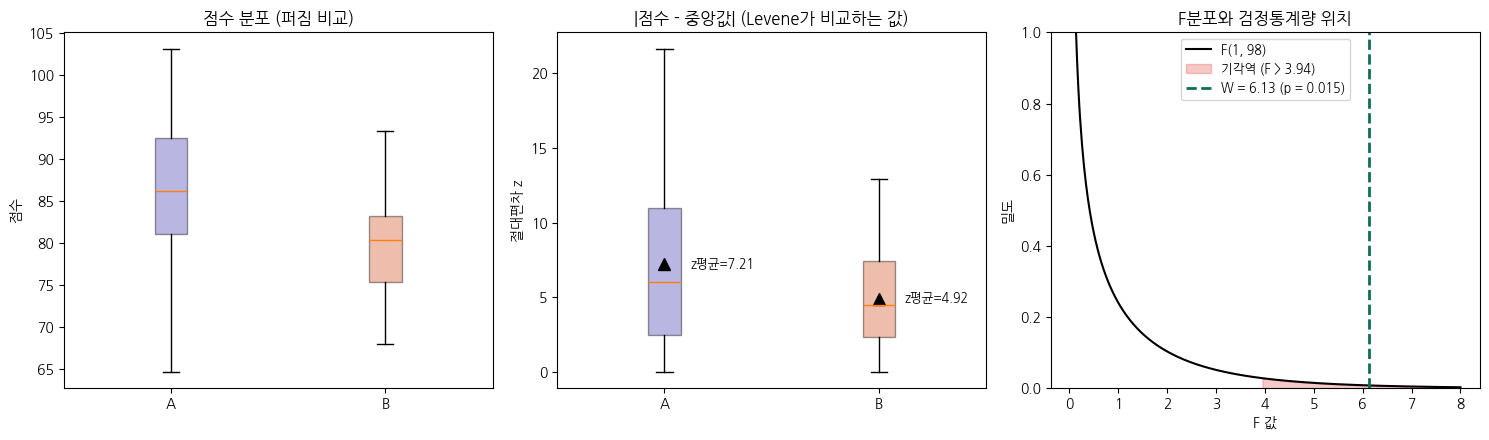

In [15]:
# [문제 3] Q2. 두 그룹 등분산성 검정 (Levene's test)
# H₀: 두 그룹의 분산은 같다.
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rc('axes', unicode_minus=False)

# 데이터 (앞 셀과 동일)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

# ─────────────────────────────────────────────
# 1) 공식 대입 풀이
#    zᵢⱼ = |xᵢⱼ - 중앙값ᵢ|   (scipy 기본값 center='median')
#    W = (N-k)/(k-1) · Σnᵢ(z̄ᵢ - z̄)² / ΣΣ(zᵢⱼ - z̄ᵢ)²  ~  F(k-1, N-k)
# ─────────────────────────────────────────────
groups = {'A': group_a_scores, 'B': group_b_scores}
k = len(groups)
N = sum(len(g) for g in groups.values())

print("=== 공식 대입 풀이 ===")
z = {}
for name, g in groups.items():
    med = np.median(g)
    z[name] = np.abs(g - med)             # 중앙값으로부터의 절대편차
    print(f"[{name} 그룹] n = {len(g)}, 표본분산 = {g.var(ddof=1):.2f}, "
          f"중앙값 = {med:.2f}, z̄ = {z[name].mean():.4f}")

z_all_mean = np.concatenate(list(z.values())).mean()
between = sum(len(z[n]) * (z[n].mean() - z_all_mean) ** 2 for n in z)   # 집단 간
within  = sum(np.sum((z[n] - z[n].mean()) ** 2) for n in z)            # 집단 내

W = (N - k) / (k - 1) * between / within
p_manual = 1 - stats.f.cdf(W, k - 1, N - k)

print(f"\n전체 z̄ = {z_all_mean:.4f}")
print(f"집단 간 제곱합 Σnᵢ(z̄ᵢ - z̄)²   = {between:.4f}")
print(f"집단 내 제곱합 ΣΣ(zᵢⱼ - z̄ᵢ)² = {within:.4f}")
print(f"W = ({N}-{k})/({k}-1) × {between:.4f} / {within:.4f} = {W:.4f}")
print(f"자유도 = ({k-1}, {N-k}),  p = P(F > W) = {p_manual:.4f}")

# ─────────────────────────────────────────────
# 2) scipy로 검증
# ─────────────────────────────────────────────
stat, p = stats.levene(group_a_scores, group_b_scores)   # center='median'
print("\n=== scipy.stats.levene 결과 (검증) ===")
print(f"Levene 통계량 = {stat:.4f}, p-값 = {p:.4f}")

# ─────────────────────────────────────────────
# 3) 판정 (유의수준 0.05)
# ─────────────────────────────────────────────
alpha = 0.05
print("\n=== 판정 (α = 0.05) ===")
if p > alpha:
    print(f"p = {p:.4f} > {alpha} → H₀ 기각 못 함 (등분산 가정 가능 → Student t검정)")
else:
    print(f"p = {p:.4f} ≤ {alpha} → H₀ 기각 (이분산 → Welch t검정)")

# ─────────────────────────────────────────────
# 4) 그래프
# ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = {'A': '#534AB7', 'B': '#D85A30'}

# (1) 원래 점수의 퍼짐
ax = axes[0]
bp = ax.boxplot([groups['A'], groups['B']], patch_artist=True)
ax.set_xticks([1, 2], ['A', 'B'])
for patch, c in zip(bp['boxes'], colors.values()):
    patch.set_facecolor(c); patch.set_alpha(0.4)
ax.set_title('점수 분포 (퍼짐 비교)')
ax.set_ylabel('점수')

# (2) Levene가 실제로 비교하는 값: 중앙값으로부터의 절대편차 z
ax = axes[1]
bp = ax.boxplot([z['A'], z['B']], patch_artist=True)
ax.set_xticks([1, 2], ['A', 'B'])
for patch, c in zip(bp['boxes'], colors.values()):
    patch.set_facecolor(c); patch.set_alpha(0.4)
for i, n in enumerate(['A', 'B'], start=1):
    ax.plot(i, z[n].mean(), 'k^', ms=8)
    ax.text(i + 0.12, z[n].mean(), f'z평균={z[n].mean():.2f}', va='center', fontsize=9)
ax.set_title('|점수 - 중앙값| (Levene가 비교하는 값)')
ax.set_ylabel('절대편차 z')

# (3) F분포 위의 검정통계량과 기각역
ax = axes[2]
xs = np.linspace(0, 8, 400)
ax.plot(xs, stats.f.pdf(xs, k - 1, N - k), 'k', lw=1.5, label=f'F({k-1}, {N-k})')
crit = stats.f.ppf(1 - alpha, k - 1, N - k)
ax.fill_between(xs, stats.f.pdf(xs, k - 1, N - k), where=xs >= crit,
                color='#E24B4A', alpha=0.3, label=f'기각역 (F > {crit:.2f})')
ax.axvline(stat, color='#0F6E56', lw=2, ls='--', label=f'W = {stat:.2f} (p = {p:.3f})')
ax.set_ylim(0, 1.0)
ax.set_title('F분포와 검정통계량 위치')
ax.set_xlabel('F 값'); ax.set_ylabel('밀도'); ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

Levene p = 0.0150 → equal_var = False (Welch t검정)

=== 공식 대입 풀이 ===
A: n = 50, 평균 = 86.1245, 분산 = 82.7299
B: n = 50, 평균 = 79.8534, 분산 = 37.5905
SE = √(s1²/n1 + s2²/n2) = √(1.6546 + 0.7518) = 1.5513
자유도 df = (s1²/n1 + s2²/n2)² / [(s1²/n1)²/(n1-1) + (s2²/n2)²/(n2-1)] = 85.9088
t = (x̄₁ - x̄₂) / SE = (86.1245 - 79.8534) / 1.5513 = 4.0426
p = 2 × P(T > |t|) = 0.0001
평균 차이 95% 신뢰구간 = (3.1872, 9.3549)

=== scipy.stats.ttest_ind 결과 (검증) ===
t-통계량 = 4.0426, p-값 = 0.0001

=== 판정 (α = 0.05) ===
p = 0.0001 < 0.05 → H₀ 기각 (두 그룹의 평균은 다르다)


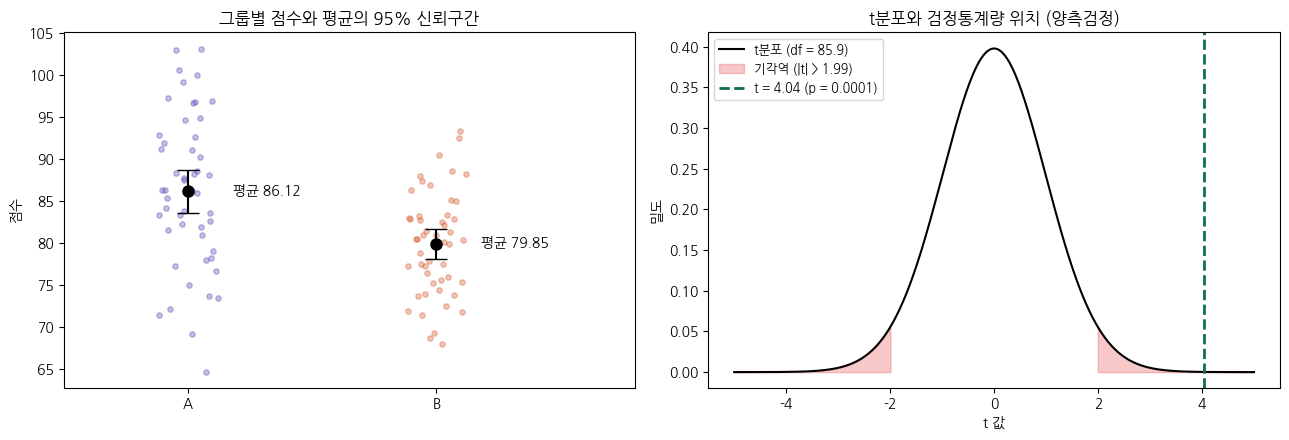

In [16]:
# [문제 3] Q3. 이표본 t-검정
# H₀: 두 그룹의 평균은 같다. / H₁: 두 그룹의 평균은 다르다. (양측검정)
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rc('axes', unicode_minus=False)

# 데이터 (앞 셀과 동일)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)
alpha = 0.05

# ─────────────────────────────────────────────
# 0) 등분산성 확인 → equal_var 결정
# ─────────────────────────────────────────────
lev_stat, lev_p = stats.levene(group_a_scores, group_b_scores)
equal_var = lev_p > alpha
print(f"Levene p = {lev_p:.4f} → equal_var = {equal_var} "
      f"({'Student t검정' if equal_var else 'Welch t검정'})")

# ─────────────────────────────────────────────
# 1) 공식 대입 풀이
# ─────────────────────────────────────────────
x1, x2 = group_a_scores, group_b_scores
n1, n2 = len(x1), len(x2)
m1, m2 = x1.mean(), x2.mean()
v1, v2 = x1.var(ddof=1), x2.var(ddof=1)

print("\n=== 공식 대입 풀이 ===")
print(f"A: n = {n1}, 평균 = {m1:.4f}, 분산 = {v1:.4f}")
print(f"B: n = {n2}, 평균 = {m2:.4f}, 분산 = {v2:.4f}")

if equal_var:
    # Student: 합동분산 sp² = [(n1-1)s1² + (n2-1)s2²] / (n1+n2-2)
    sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
    se = np.sqrt(sp2 * (1/n1 + 1/n2))
    df = n1 + n2 - 2
    print(f"합동분산 sp² = {sp2:.4f}")
    print(f"SE = √(sp²(1/n1 + 1/n2)) = {se:.4f}")
    print(f"자유도 df = n1 + n2 - 2 = {df}")
else:
    # Welch: SE = √(s1²/n1 + s2²/n2)
    se = np.sqrt(v1/n1 + v2/n2)
    # Welch–Satterthwaite 자유도
    df = (v1/n1 + v2/n2) ** 2 / ((v1/n1) ** 2 / (n1 - 1) + (v2/n2) ** 2 / (n2 - 1))
    print(f"SE = √(s1²/n1 + s2²/n2) = √({v1/n1:.4f} + {v2/n2:.4f}) = {se:.4f}")
    print(f"자유도 df = (s1²/n1 + s2²/n2)² / [(s1²/n1)²/(n1-1) + (s2²/n2)²/(n2-1)] = {df:.4f}")

t_manual = (m1 - m2) / se
p_manual = 2 * (1 - stats.t.cdf(abs(t_manual), df))
print(f"t = (x̄₁ - x̄₂) / SE = ({m1:.4f} - {m2:.4f}) / {se:.4f} = {t_manual:.4f}")
print(f"p = 2 × P(T > |t|) = {p_manual:.4f}")

# 95% 신뢰구간 (평균 차이)
t_crit = stats.t.ppf(1 - alpha/2, df)
ci = (m1 - m2 - t_crit * se, m1 - m2 + t_crit * se)
print(f"평균 차이 95% 신뢰구간 = ({ci[0]:.4f}, {ci[1]:.4f})")

# ─────────────────────────────────────────────
# 2) scipy로 검증
# ─────────────────────────────────────────────
t_stat, p_value = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=equal_var)
print("\n=== scipy.stats.ttest_ind 결과 (검증) ===")
print(f"t-통계량 = {t_stat:.4f}, p-값 = {p_value:.4f}")

# ─────────────────────────────────────────────
# 3) 판정
# ─────────────────────────────────────────────
print(f"\n=== 판정 (α = {alpha}) ===")
if p_value < alpha:
    print(f"p = {p_value:.4f} < {alpha} → H₀ 기각 (두 그룹의 평균은 다르다)")
else:
    print(f"p = {p_value:.4f} ≥ {alpha} → H₀ 기각 못 함 (평균이 다르다고 할 증거 부족)")

# ─────────────────────────────────────────────
# 4) 그래프 (그래프 글자는 폰트 경고 방지를 위해 일반 기호만 사용)
# ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (1) 그룹 평균과 95% 신뢰구간
ax = axes[0]
for i, (name, x, c) in enumerate([('A', x1, '#534AB7'), ('B', x2, '#D85A30')]):
    m, s = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    h = stats.t.ppf(1 - alpha/2, len(x) - 1) * s
    ax.scatter(np.full(len(x), i) + np.random.uniform(-0.12, 0.12, len(x)), x,
               color=c, alpha=0.35, s=15)
    ax.errorbar(i, m, yerr=h, fmt='o', color='k', capsize=8, ms=8)
    ax.text(i + 0.18, m, f'평균 {m:.2f}', va='center', fontsize=10)
ax.set_xticks([0, 1], ['A', 'B'])
ax.set_xlim(-0.5, 1.8)
ax.set_title('그룹별 점수와 평균의 95% 신뢰구간')
ax.set_ylabel('점수')

# (2) t분포 위의 검정통계량과 양측 기각역
ax = axes[1]
xs = np.linspace(-5, 5, 500)
ys = stats.t.pdf(xs, df)
ax.plot(xs, ys, 'k', lw=1.5, label=f't분포 (df = {df:.1f})')
ax.fill_between(xs, ys, where=xs >= t_crit, color='#E24B4A', alpha=0.3,
                label=f'기각역 (|t| > {t_crit:.2f})')
ax.fill_between(xs, ys, where=xs <= -t_crit, color='#E24B4A', alpha=0.3)
ax.axvline(t_stat, color='#0F6E56', lw=2, ls='--', label=f't = {t_stat:.2f} (p = {p_value:.4f})')
ax.set_title('t분포와 검정통계량 위치 (양측검정)')
ax.set_xlabel('t 값'); ax.set_ylabel('밀도'); ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

관측된 평균 차이 (A - B) = 86.1245 - 79.8534 = 6.2711

시뮬레이션 횟수 = 10,000
시뮬레이션 평균 차이들의 평균 = -0.0161  (H₀ 하에서 0 근처여야 함)
시뮬레이션 평균 차이들의 표준편차 = 1.6559
처음 10개 값: [-3.420e-01 -3.999e+00 -1.513e+00  1.148e+00 -1.810e-01 -2.890e-01
 -8.370e-01  5.270e-01  2.000e-03  1.420e+00]

=== 순열검정 p-값 ===
|차이| ≥ 6.2711 인 경우의 수 = 1
p = 1 / 10000 = 0.0001
보정 p = (1 + 1) / (10000 + 1) = 0.00020

이론적 표준편차 ≈ s_전체 × √(1/50 + 1/50) = 1.6671 (시뮬레이션 1.6559)
참고 - Welch t검정 p = 0.00011

=== 판정 (α = 0.05) ===
p = 0.00020 < 0.05 → H₀ 기각 (H₀가 사실이면 관측된 차이만큼 벌어지는 일은 거의 없다)


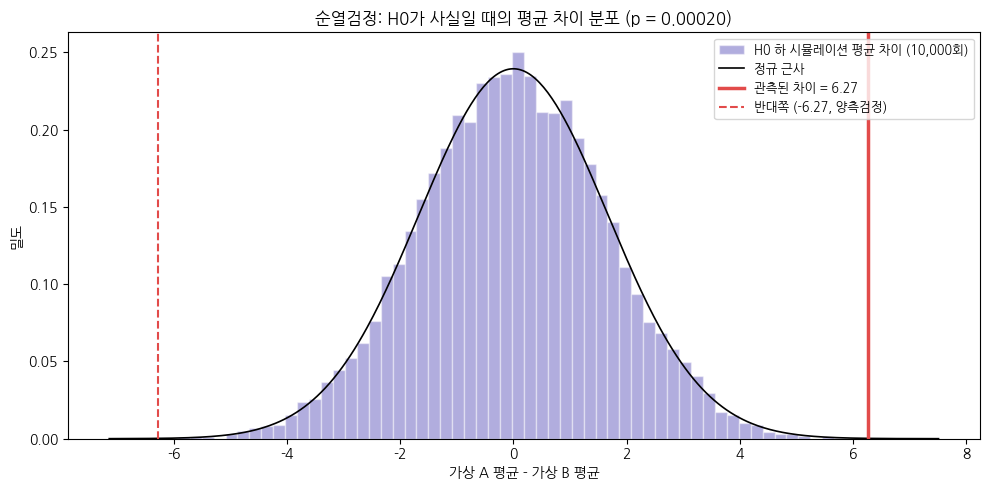

In [17]:
# [문제 3] Q4. H₀가 사실이라고 가정한 순열(permutation) 시뮬레이션 10,000번
# H₀: 두 그룹의 평균은 같다 → 학습방식 라벨(A/B)은 점수와 무관하므로 섞어도 된다.
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rc('axes', unicode_minus=False)

# 데이터 (앞 셀과 동일)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

# ─────────────────────────────────────────────
# 1) 관측된 평균 차이
# ─────────────────────────────────────────────
observed_diff = group_a_scores.mean() - group_b_scores.mean()
print(f"관측된 평균 차이 (A - B) = {group_a_scores.mean():.4f} - {group_b_scores.mean():.4f} "
      f"= {observed_diff:.4f}")

# ─────────────────────────────────────────────
# 2) 시뮬레이션: 합치고 → 섞고 → 50/50 나누기 → 평균 차이 저장
# ─────────────────────────────────────────────
all_scores = np.concatenate([group_a_scores, group_b_scores])   # 100개
n_a = len(group_a_scores)
n_sim = 10000

np.random.seed(42)                    # 시뮬레이션 재현용 시드
sim_diffs = []
for _ in range(n_sim):
    shuffled = np.random.permutation(all_scores)      # 비복원추출 (순서만 섞음)
    fake_a = shuffled[:n_a]                     # 가상 A그룹 50개
    fake_b = shuffled[n_a:]                     # 나머지 50개 = 가상 B그룹
    sim_diffs.append(fake_a.mean() - fake_b.mean())

sim_diffs = np.array(sim_diffs)

print(f"\n시뮬레이션 횟수 = {len(sim_diffs):,}")
print(f"시뮬레이션 평균 차이들의 평균 = {sim_diffs.mean():.4f}  (H₀ 하에서 0 근처여야 함)")
print(f"시뮬레이션 평균 차이들의 표준편차 = {sim_diffs.std(ddof=1):.4f}")
print(f"처음 10개 값: {np.round(sim_diffs[:10], 3)}")

# ─────────────────────────────────────────────
# 3) 공식 대입: 순열검정 p-값 (양측)
#    p = #{ |시뮬레이션 차이| ≥ |관측 차이| } / 시뮬레이션 횟수
# ─────────────────────────────────────────────
count = np.sum(np.abs(sim_diffs) >= abs(observed_diff))
p_perm = count / n_sim
p_perm_adj = (count + 1) / (n_sim + 1)   # 0이 나오는 것을 막는 보정식

print("\n=== 순열검정 p-값 ===")
print(f"|차이| ≥ {abs(observed_diff):.4f} 인 경우의 수 = {count}")
print(f"p = {count} / {n_sim} = {p_perm:.4f}")
print(f"보정 p = ({count} + 1) / ({n_sim} + 1) = {p_perm_adj:.5f}")

# 이론값 비교: 순열분포의 표준편차 ≈ 합친 데이터 표준편차 × √(1/n_a + 1/n_b)
theory_sd = all_scores.std(ddof=1) * np.sqrt(1/n_a + 1/(len(all_scores) - n_a))
print(f"\n이론적 표준편차 ≈ s_전체 × √(1/50 + 1/50) = {theory_sd:.4f} "
      f"(시뮬레이션 {sim_diffs.std(ddof=1):.4f})")

# 참고: Q3의 Welch t검정 결과와 비교
t_stat, p_t = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=False)
print(f"참고 - Welch t검정 p = {p_t:.5f}")

alpha = 0.05
print(f"\n=== 판정 (α = {alpha}) ===")
if p_perm_adj < alpha:
    print(f"p = {p_perm_adj:.5f} < {alpha} → H₀ 기각 "
          f"(H₀가 사실이면 관측된 차이만큼 벌어지는 일은 거의 없다)")
else:
    print(f"p = {p_perm_adj:.5f} ≥ {alpha} → H₀ 기각 못 함")

# ─────────────────────────────────────────────
# 4) 그래프 (그래프 글자는 일반 기호만 사용)
# ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(sim_diffs, bins=60, density=True, color='#534AB7', alpha=0.45,
        edgecolor='white', label='H0 하 시뮬레이션 평균 차이 (10,000회)')

xs = np.linspace(sim_diffs.min() - 1, max(sim_diffs.max(), observed_diff) + 1, 400)
ax.plot(xs, stats.norm.pdf(xs, 0, theory_sd), 'k', lw=1.2, label='정규 근사')

ax.axvline(observed_diff, color='#E24B4A', lw=2.5,
           label=f'관측된 차이 = {observed_diff:.2f}')
ax.axvline(-observed_diff, color='#E24B4A', lw=1.5, ls='--',
           label=f'반대쪽 (-{observed_diff:.2f}, 양측검정)')

ax.set_title(f'순열검정: H0가 사실일 때의 평균 차이 분포 (p = {p_perm_adj:.5f})')
ax.set_xlabel('가상 A 평균 - 가상 B 평균')
ax.set_ylabel('밀도')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

실제 관찰된 평균 차이 (A - B) = 6.2711
시뮬레이션 평균 = -0.0161, 표준편차 = 1.6559
z = (6.2711 - (-0.0161)) / 1.6559 = 3.80
H₀ 하 95% 범위 (2.5% ~ 97.5% 분위수) = (-3.2928, 3.2087)
|차이| ≥ |관찰값| 인 횟수 = 1 / 10,000
p = (1 + 1) / (10000 + 1) = 0.00020


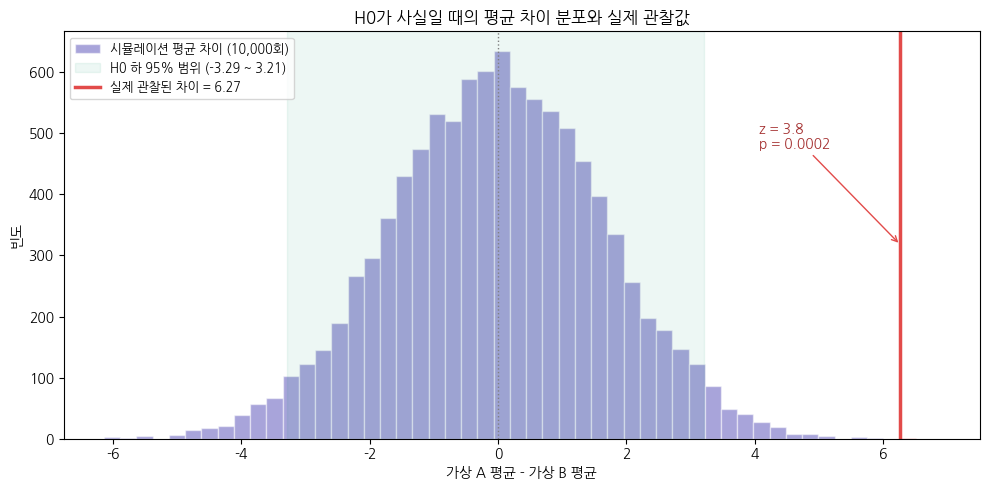

In [18]:
# [문제 3] Q5. 시뮬레이션 평균 차이 분포 히스토그램 + 실제 관찰값 세로선
import numpy as np
import matplotlib.pyplot as plt

plt.rc('axes', unicode_minus=False)

# Q4를 이미 실행했다면 그 결과(sim_diffs, observed_diff)를 그대로 사용하고,
# 아니라면 여기서 다시 만든다.
try:
    sim_diffs, observed_diff
except NameError:
    np.random.seed(0)
    group_a_scores = np.random.normal(loc=85, scale=8, size=50)
    group_b_scores = np.random.normal(loc=80, scale=7, size=50)
    observed_diff = group_a_scores.mean() - group_b_scores.mean()

    all_scores = np.concatenate([group_a_scores, group_b_scores])
    np.random.seed(42)
    sim_diffs = []
    for _ in range(10000):
        shuffled = np.random.permutation(all_scores)
        sim_diffs.append(shuffled[:50].mean() - shuffled[50:].mean())
sim_diffs = np.array(sim_diffs)

# ─────────────────────────────────────────────
# 1) 공식 대입: 관찰값이 분포에서 어디쯤인지
#    표준화 위치 z = (관찰 차이 - 시뮬레이션 평균) / 시뮬레이션 표준편차
#    양측 p = #{ |시뮬레이션 차이| ≥ |관찰 차이| } / 10,000
# ─────────────────────────────────────────────
sim_mean = sim_diffs.mean()
sim_sd = sim_diffs.std(ddof=1)
z_pos = (observed_diff - sim_mean) / sim_sd
count = np.sum(np.abs(sim_diffs) >= abs(observed_diff))
p_value = (count + 1) / (len(sim_diffs) + 1)
lo, hi = np.percentile(sim_diffs, [2.5, 97.5])   # H₀ 하에서 흔한 95% 범위

print(f"실제 관찰된 평균 차이 (A - B) = {observed_diff:.4f}")
print(f"시뮬레이션 평균 = {sim_mean:.4f}, 표준편차 = {sim_sd:.4f}")
print(f"z = ({observed_diff:.4f} - ({sim_mean:.4f})) / {sim_sd:.4f} = {z_pos:.2f}")
print(f"H₀ 하 95% 범위 (2.5% ~ 97.5% 분위수) = ({lo:.4f}, {hi:.4f})")
print(f"|차이| ≥ |관찰값| 인 횟수 = {count} / {len(sim_diffs):,}")
print(f"p = ({count} + 1) / ({len(sim_diffs)} + 1) = {p_value:.5f}")

# ─────────────────────────────────────────────
# 2) 히스토그램 + 관찰값 세로선 (그래프 글자는 일반 기호만 사용)
# ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

counts, bins, patches = ax.hist(sim_diffs, bins=50, color='#534AB7', alpha=0.5,
                                edgecolor='white', label='시뮬레이션 평균 차이 (10,000회)')
# 관찰값보다 극단적인 구간은 빨간색으로 표시
for patch, left in zip(patches, bins[:-1]):
    if abs(left + (bins[1] - bins[0]) / 2) >= abs(observed_diff):   # 구간 중심 기준
        patch.set_facecolor('#E24B4A')

ax.axvspan(lo, hi, color='#1D9E75', alpha=0.08, label=f'H0 하 95% 범위 ({lo:.2f} ~ {hi:.2f})')
ax.axvline(0, color='gray', lw=1, ls=':')
ax.axvline(observed_diff, color='#E24B4A', lw=2.5,
           label=f'실제 관찰된 차이 = {observed_diff:.2f}')
ax.annotate(f'z = {z_pos:.1f}\np = {p_value:.4f}',
            xy=(observed_diff, max(counts) * 0.5),
            xytext=(observed_diff - 2.2, max(counts) * 0.75),
            arrowprops=dict(arrowstyle='->', color='#E24B4A'), fontsize=10, color='#A32D2D')

ax.set_xlim(min(sim_diffs.min(), -abs(observed_diff)) - 0.5, max(sim_diffs.max(), observed_diff) + 1)
ax.set_title('H0가 사실일 때의 평균 차이 분포와 실제 관찰값')
ax.set_xlabel('가상 A 평균 - 가상 B 평균')
ax.set_ylabel('빈도')
ax.legend(fontsize=9, loc='upper left')
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 정규성 검정과 등분산성 검정의 p-값은 각각 어떻게 해석해야 하나요? 이 결과는 이표본 t-검정을 사용하는 데 문제가 없음을 보여주나요?

- Q5의 히스토그램 중심이 0에 가까운 이유는 무엇일까요?

- 실제 관찰된 평균 차이(세로선)는 "두 방식의 효과가 같다"고 가정했을 때 우연히 나타날 수 있는 범위 안에 있나요, 벗어나나요?

- 이 시각적 판단과 Q3의 p-값은 어떤 관계가 있나요?

- 통계적으로 유의미한 차이가 있다면, 교육 기업은 이 결과를 어떻게 활용할 수 있을까요?

──────────────────────────────────────────────────────────────────────
① 정규성 검정과 등분산성 검정의 p-값 해석, t-검정 사용에 문제가 없는가?
──────────────────────────────────────────────────────────────────────
Shapiro-Wilk  A: p = 0.8766,  B: p = 0.8366
  → 두 p 모두 > 0.05 이므로 H₀(정규분포를 따른다)를 기각하지 못함.
    '정규분포가 아니라는 증거가 없다' → 정규성 가정을 사용할 수 있음.
Levene        p = 0.0150
  → p ≤ 0.05 → H₀(분산이 같다) 기각 → 두 그룹의 분산이 다름.
    등분산 가정은 깨졌지만, 분산을 따로 추정하는 Welch t-검정(equal_var=False)을
    쓰면 문제없음. 즉 '일반 t-검정은 부적절, Welch t-검정은 적절'.
  결론: 정규성은 만족, 등분산성은 불만족 → Welch 이표본 t-검정이 타당함.

──────────────────────────────────────────────────────────────────────
② Q5 히스토그램의 중심이 0에 가까운 이유는?
──────────────────────────────────────────────────────────────────────
시뮬레이션 평균 차이들의 평균 = -0.0161
  → 시뮬레이션은 H₀(두 방식의 효과가 같다)가 사실인 세계를 일부러 만든 것.
    A/B 라벨을 무작위로 섞었으므로 어느 쪽 가상그룹이 더 높을 이유가 없고,
    +쪽 차이와 -쪽 차이가 같은 비율로 나와 평균적으로 0이 됨.

──────────────────────────────────────────────────────────────────────
③ 실제 관찰된 평균 차이는 우연히 나타날 수 있는 범위 안인가?
──────────────

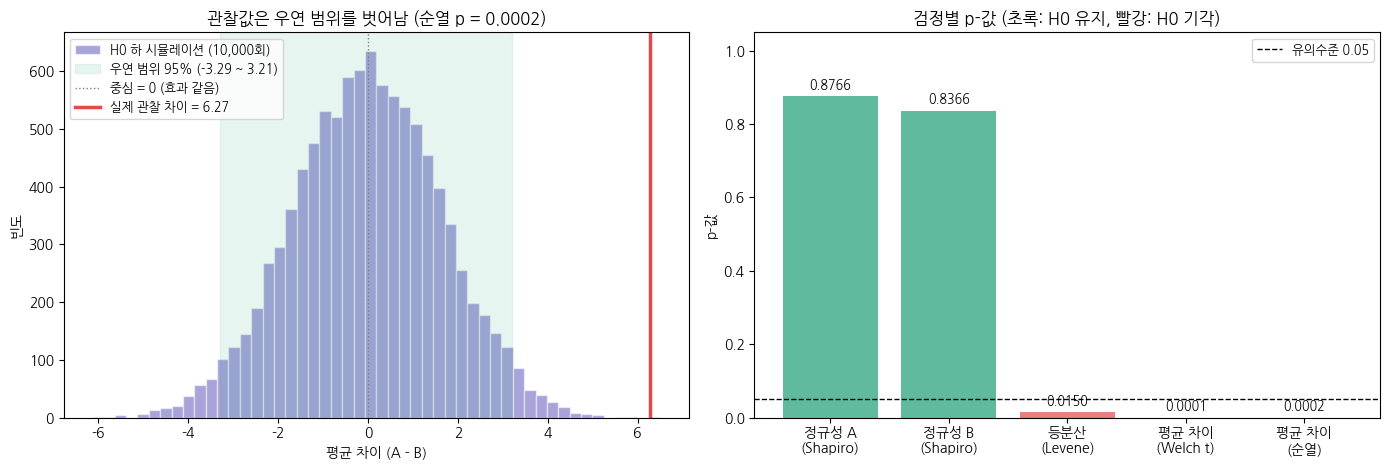

In [19]:
# 🧠 데이터를 어떻게 읽을까요? — 온라인 학습방식 A/B 데이터 해석
# Q1~Q5 결과를 한 번에 계산하고, 질문별 해석을 숫자와 함께 출력합니다.
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rc('axes', unicode_minus=False)
alpha = 0.05

# ── 데이터 (앞 셀과 동일) ─────────────────────────
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

# ── Q1~Q4 결과 다시 계산 ──────────────────────────
_, p_norm_a = stats.shapiro(group_a_scores)
_, p_norm_b = stats.shapiro(group_b_scores)
_, p_lev = stats.levene(group_a_scores, group_b_scores)
equal_var = p_lev > alpha
t_stat, p_t = stats.ttest_ind(group_a_scores, group_b_scores, equal_var=equal_var)

observed_diff = group_a_scores.mean() - group_b_scores.mean()
all_scores = np.concatenate([group_a_scores, group_b_scores])
np.random.seed(42)
sim_diffs = np.array([(lambda s: s[:50].mean() - s[50:].mean())(np.random.permutation(all_scores))
                      for _ in range(10000)])
lo, hi = np.percentile(sim_diffs, [2.5, 97.5])
count = np.sum(np.abs(sim_diffs) >= abs(observed_diff))
p_perm = (count + 1) / (len(sim_diffs) + 1)

line = "─" * 70

# ── 질문 1: 정규성·등분산성 해석 ───────────────────
print(line)
print("① 정규성 검정과 등분산성 검정의 p-값 해석, t-검정 사용에 문제가 없는가?")
print(line)
print(f"Shapiro-Wilk  A: p = {p_norm_a:.4f},  B: p = {p_norm_b:.4f}")
print(f"  → 두 p 모두 > {alpha} 이므로 H₀(정규분포를 따른다)를 기각하지 못함.")
print("    '정규분포가 아니라는 증거가 없다' → 정규성 가정을 사용할 수 있음.")
print(f"Levene        p = {p_lev:.4f}")
if equal_var:
    print(f"  → p > {alpha} → 등분산 가정 가능 → Student t-검정(equal_var=True) 사용.")
else:
    print(f"  → p ≤ {alpha} → H₀(분산이 같다) 기각 → 두 그룹의 분산이 다름.")
    print("    등분산 가정은 깨졌지만, 분산을 따로 추정하는 Welch t-검정(equal_var=False)을")
    print("    쓰면 문제없음. 즉 '일반 t-검정은 부적절, Welch t-검정은 적절'.")
print("  결론: 정규성은 만족, 등분산성은 불만족 → Welch 이표본 t-검정이 타당함.\n")

# ── 질문 2: 히스토그램 중심이 0인 이유 ─────────────
print(line)
print("② Q5 히스토그램의 중심이 0에 가까운 이유는?")
print(line)
print(f"시뮬레이션 평균 차이들의 평균 = {sim_diffs.mean():.4f}")
print("  → 시뮬레이션은 H₀(두 방식의 효과가 같다)가 사실인 세계를 일부러 만든 것.")
print("    A/B 라벨을 무작위로 섞었으므로 어느 쪽 가상그룹이 더 높을 이유가 없고,")
print("    +쪽 차이와 -쪽 차이가 같은 비율로 나와 평균적으로 0이 됨.\n")

# ── 질문 3: 관찰값이 우연 범위 안인가 ──────────────
print(line)
print("③ 실제 관찰된 평균 차이는 우연히 나타날 수 있는 범위 안인가?")
print(line)
print(f"실제 관찰된 평균 차이 = {observed_diff:.4f}")
print(f"H₀ 하에서 95%가 들어가는 범위 = ({lo:.4f}, {hi:.4f})")
print(f"10,000번 중 |차이| ≥ {abs(observed_diff):.2f} 인 경우 = {count}번")
print(f"  → 관찰값 {observed_diff:.2f}는 우연 범위의 상한 {hi:.2f}를 크게 벗어남.")
print("    두 방식의 효과가 같다면 이 정도 차이는 거의 나오지 않음.\n")

# ── 질문 4: 시각적 판단과 p-값의 관계 ──────────────
print(line)
print("④ 이 시각적 판단과 Q3의 p-값은 어떤 관계인가?")
print(line)
print(f"Q3 t-검정 p = {p_t:.5f},  순열검정 p = {p_perm:.5f}")
print("  → p-값 = 히스토그램에서 세로선보다 바깥쪽(양쪽 꼬리)에 있는 면적의 비율.")
print("    세로선이 분포 꼬리 끝에 있다 = 바깥 면적이 매우 작다 = p-값이 작다.")
print("    t-검정은 이 분포를 t분포 공식으로, 순열검정은 데이터로 직접 그린 것이라")
print("    두 p-값이 거의 같게 나옴 → 같은 판단을 수식과 그림으로 한 것.\n")

# ── 질문 5: 교육 기업의 활용 ──────────────────────
ci_se = np.sqrt(group_a_scores.var(ddof=1)/50 + group_b_scores.var(ddof=1)/50)
df_w = (group_a_scores.var(ddof=1)/50 + group_b_scores.var(ddof=1)/50) ** 2 / (
    (group_a_scores.var(ddof=1)/50) ** 2 / 49 + (group_b_scores.var(ddof=1)/50) ** 2 / 49)
tc = stats.t.ppf(0.975, df_w)
ci = (observed_diff - tc * ci_se, observed_diff + tc * ci_se)
pooled_sd = np.sqrt((group_a_scores.var(ddof=1) + group_b_scores.var(ddof=1)) / 2)
cohen_d = observed_diff / pooled_sd

print(line)
print("⑤ 통계적으로 유의미한 차이가 있다면, 교육 기업은 어떻게 활용할 수 있나?")
print(line)
print(f"평균 차이 95% 신뢰구간 = ({ci[0]:.2f}, {ci[1]:.2f})점")
print(f"효과 크기 Cohen's d = {cohen_d:.2f} "
      f"({'큰' if cohen_d >= 0.8 else '중간' if cohen_d >= 0.5 else '작은'} 효과)")
print("  → A 방식이 평균 약 3~9점 높으며, 실무적으로도 의미 있는 크기.")
print("  활용 예:")
print("   · A 방식을 기본 커리큘럼으로 확대하고 마케팅 근거로 활용")
print(f"   · 단, A는 분산이 더 큼(SD {group_a_scores.std(ddof=1):.1f} vs "
      f"{group_b_scores.std(ddof=1):.1f}) → 효과가 학생마다 들쭉날쭉할 수 있으므로")
print("     하위권 학생 맞춤 보완(예: B 방식 요소 병행)을 검토")
print("   · 전면 도입 비용 대비 3~9점 향상의 가치를 따져 의사결정")
print("   · 무작위 배정이었는지 확인하고, 다른 학생 집단에서 재검증(A/B 테스트 반복)")

# ── 종합 그래프 ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.hist(sim_diffs, bins=50, color='#534AB7', alpha=0.5, edgecolor='white',
        label='H0 하 시뮬레이션 (10,000회)')
ax.axvspan(lo, hi, color='#1D9E75', alpha=0.1, label=f'우연 범위 95% ({lo:.2f} ~ {hi:.2f})')
ax.axvline(0, color='gray', ls=':', lw=1, label='중심 = 0 (효과 같음)')
ax.axvline(observed_diff, color='#E24B4A', lw=2.5, label=f'실제 관찰 차이 = {observed_diff:.2f}')
ax.set_title(f'관찰값은 우연 범위를 벗어남 (순열 p = {p_perm:.4f})')
ax.set_xlabel('평균 차이 (A - B)'); ax.set_ylabel('빈도'); ax.legend(fontsize=9)

ax = axes[1]
names = ['정규성 A\n(Shapiro)', '정규성 B\n(Shapiro)', '등분산\n(Levene)', '평균 차이\n(Welch t)', '평균 차이\n(순열)']
pvals = [p_norm_a, p_norm_b, p_lev, p_t, p_perm]
colors = ['#1D9E75' if p > alpha else '#E24B4A' for p in pvals]
bars = ax.bar(names, pvals, color=colors, alpha=0.7)
ax.axhline(alpha, color='k', ls='--', lw=1, label='유의수준 0.05')
for b, p in zip(bars, pvals):
    ax.text(b.get_x() + b.get_width()/2, p + 0.02, f'{p:.4f}', ha='center', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title('검정별 p-값 (초록: H0 유지, 빨강: H0 기각)')
ax.set_ylabel('p-값'); ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# 문제 4. 연령대별로 선호하는 영화 장르가 다를까? (난이도: 중)

**📘 문제**

- 한 영화관에서 고객의 **연령대(20대, 30대, 40대)**에 따라 선호하는 **영화 장르(액션, 로맨스)**에 차이가 있는지 궁금해졌습니다.

- 이를 알아보기 위해 300명의 고객을 대상으로 설문조사를 진행하여 분할표를 얻었습니다.

- 이번 실습에서는 **카이제곱 독립성 검정(Chi-squared Test of Independence)**으로
  두 범주형 변수 사이에 연관성이 있는지 검증합니다.

- 또한 **"두 변수가 서로 아무 관련이 없다면(독립이라면)"** 어떤 카이제곱 통계량들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

관측 빈도 (Observed Frequencies):
      액션  로맨스
20대    70      30
30대    50      60
40대    30      60


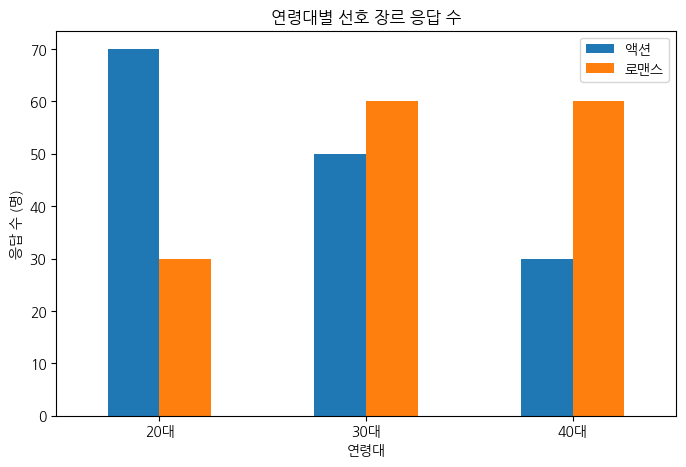

In [20]:
# 데이터 생성 (관측 빈도 분할표)
data = {'액션': [70, 50, 30],
        '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])

print("관측 빈도 (Observed Frequencies):")
print(observed)

# 분할표 시각화
observed.plot(kind='bar', figsize=(8, 5))
plt.title("연령대별 선호 장르 응답 수")
plt.xlabel("연령대")
plt.ylabel("응답 수 (명)")
plt.xticks(rotation=0)
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 카이제곱 독립성 검정을 수행하여 카이제곱 통계량, p-값, 자유도, **기대 빈도**를 구해봅시다.

- **"연령대와 선호 장르가 독립이라면"** 어떤 분할표들이 나타날 수 있는지 5,000번 시뮬레이션해 봅시다.

- 시뮬레이션으로 얻은 카이제곱 통계량 분포와 실제 관찰된 카이제곱 통계량을 비교해 봅시다.

In [21]:
# H₀ (귀무가설): 연령대와 선호 장르는 서로 독립이다. (관련이 없다)
# H₁ (대립가설): 연령대와 선호 장르는 서로 독립이 아니다. (관련이 있다)

1단계. 기대 빈도 E  (H₀ 독립이라면 나왔어야 할 수)
공식:  E = (행 합계 × 열 합계) / 전체 합계

행 합계 → 20대 100, 30대 110, 40대 90
열 합계 → 액션 150, 로맨스 150
전체   → 300

  E(20대, 액션 ) = (100 × 150) / 300 = 50
  E(20대, 로맨스) = (100 × 150) / 300 = 50
  E(30대, 액션 ) = (110 × 150) / 300 = 55
  E(30대, 로맨스) = (110 × 150) / 300 = 55
  E(40대, 액션 ) = (90 × 150) / 300 = 45
  E(40대, 로맨스) = (90 × 150) / 300 = 45

2단계. 칸마다 차이 계산
공식:  (O - E)² / E
       → 차이를 제곱해 부호를 없애고, E로 나눠 칸 크기를 맞춤

  20대 액션 : (70 - 50)² / 50 = 400 / 50 = 8.0000
  20대 로맨스: (30 - 50)² / 50 = 400 / 50 = 8.0000
  30대 액션 : (50 - 55)² / 55 = 25 / 55 = 0.4545
  30대 로맨스: (60 - 55)² / 55 = 25 / 55 = 0.4545
  40대 액션 : (30 - 45)² / 45 = 225 / 45 = 5.0000
  40대 로맨스: (60 - 45)² / 45 = 225 / 45 = 5.0000

3단계. 모든 칸을 더하면 카이제곱 통계량
공식:  χ² = Σ (O - E)² / E

  χ² = 8.0000 + 8.0000 + 0.4545 + 0.4545 + 5.0000 + 5.0000
     = 26.9091

4단계. 자유도와 p-값
공식:  df = (행 수 - 1) × (열 수 - 1) = (3 - 1) × (2 - 1) = 2
       p  = P(χ² ≥ 26.91 | df = 2) = 0.000001

  기준값(α = 0.05, df = 2) = 5.99
  관측 

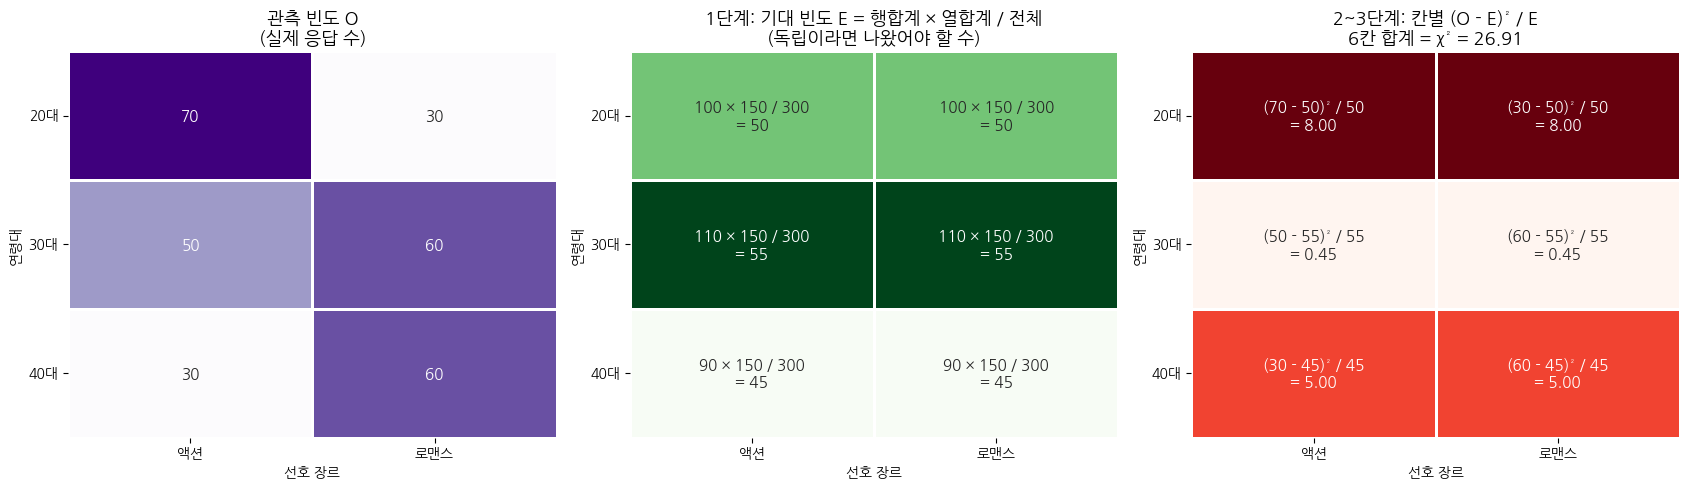

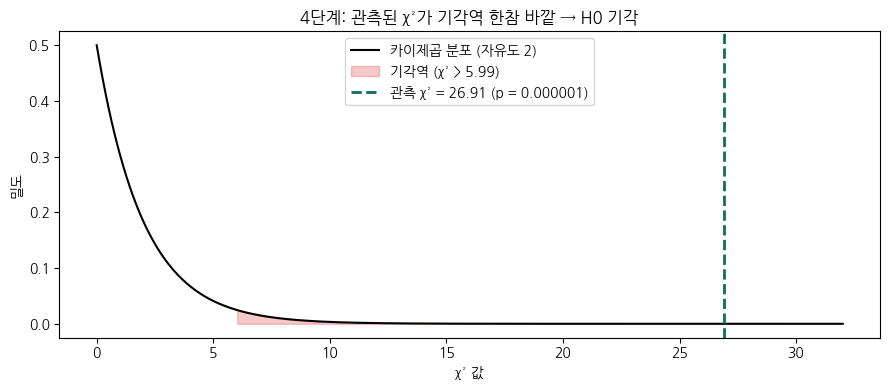

In [29]:
# [문제 4] Q2. 카이제곱 독립성 검정 — 공식을 단계별로 대입해서 출력 (텍스트 버전)
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 (나눔고딕이 설치돼 있으면 사용)
try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

data = {'액션': [70, 50, 30], '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])

row_sum = observed.sum(axis=1)
col_sum = observed.sum(axis=0)
total = int(observed.values.sum())
bar = "=" * 60

# 1단계: 기대 빈도
print(bar)
print("1단계. 기대 빈도 E  (H₀ 독립이라면 나왔어야 할 수)")
print(bar)
print("공식:  E = (행 합계 × 열 합계) / 전체 합계\n")
print(f"행 합계 → 20대 {row_sum['20대']}, 30대 {row_sum['30대']}, 40대 {row_sum['40대']}")
print(f"열 합계 → 액션 {col_sum['액션']}, 로맨스 {col_sum['로맨스']}")
print(f"전체   → {total}\n")

E = pd.DataFrame(index=observed.index, columns=observed.columns, dtype=float)
for r in observed.index:
    for c in observed.columns:
        E.loc[r, c] = row_sum[r] * col_sum[c] / total
        print(f"  E({r}, {c:<3}) = ({row_sum[r]} × {col_sum[c]}) / {total} = {E.loc[r, c]:.0f}")

# 2단계: 칸별 기여도
print("\n" + bar)
print("2단계. 칸마다 차이 계산")
print(bar)
print("공식:  (O - E)² / E")
print("       → 차이를 제곱해 부호를 없애고, E로 나눠 칸 크기를 맞춤\n")

contrib = pd.DataFrame(index=observed.index, columns=observed.columns, dtype=float)
for r in observed.index:
    for c in observed.columns:
        O, Ev = observed.loc[r, c], E.loc[r, c]
        contrib.loc[r, c] = (O - Ev) ** 2 / Ev
        print(f"  {r} {c:<3}: ({O} - {Ev:.0f})² / {Ev:.0f} = {(O - Ev)**2:.0f} / {Ev:.0f} = {contrib.loc[r, c]:.4f}")

# 3단계: 합계
chi2_manual = contrib.values.sum()
print("\n" + bar)
print("3단계. 모든 칸을 더하면 카이제곱 통계량")
print(bar)
print("공식:  χ² = Σ (O - E)² / E\n")
print("  χ² = " + " + ".join(f"{v:.4f}" for v in contrib.values.flatten()))
print(f"     = {chi2_manual:.4f}")

# 4단계: 자유도, p-값
r_, c_ = observed.shape
dof_manual = (r_ - 1) * (c_ - 1)
p_manual = 1 - stats.chi2.cdf(chi2_manual, dof_manual)
crit = stats.chi2.ppf(0.95, dof_manual)
print("\n" + bar)
print("4단계. 자유도와 p-값")
print(bar)
print(f"공식:  df = (행 수 - 1) × (열 수 - 1) = ({r_} - 1) × ({c_} - 1) = {dof_manual}")
print(f"       p  = P(χ² ≥ {chi2_manual:.2f} | df = {dof_manual}) = {p_manual:.6f}")
print(f"\n  기준값(α = 0.05, df = {dof_manual}) = {crit:.2f}")
print(f"  관측 χ² = {chi2_manual:.2f} > {crit:.2f} → H₀ 기각 (연령대와 선호 장르는 관련이 있다)")

# scipy 검증 + 기대 빈도 데이터프레임
chi2, p_value, dof, expected = stats.chi2_contingency(observed)
expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)

print("\n" + bar)
print("scipy 결과 (검증)")
print(bar)
print(f"카이제곱 통계량: {chi2:.4f}")
print(f"p-값: {p_value:.6f}")
print(f"자유도: {dof}")
print("\n기대 빈도 (Expected Frequencies):")
print(expected_df.round(2))
print("\n관측 빈도 (Observed Frequencies):")
print(observed)

# ─────────────────────────────────────────────
# 그래프: 1~3단계 공식이 각 칸에 그대로 들어간 히트맵 + 4단계 분포
# ─────────────────────────────────────────────
annot_E = observed.astype(str)
annot_C = observed.astype(str)
for r in observed.index:
    for c in observed.columns:
        O, Ev = observed.loc[r, c], E.loc[r, c]
        annot_E.loc[r, c] = f"{row_sum[r]} × {col_sum[c]} / {total}\n= {Ev:.0f}"
        annot_C.loc[r, c] = f"({O} - {Ev:.0f})² / {Ev:.0f}\n= {contrib.loc[r, c]:.2f}"

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
kw = dict(linewidths=1, linecolor='white', cbar=False, annot_kws={'fontsize': 11})
sns.heatmap(observed, annot=True, fmt='d', cmap='Purples', ax=axes[0], **kw)
axes[0].set_title('관측 빈도 O\n(실제 응답 수)', fontsize=13)
sns.heatmap(E, annot=annot_E, fmt='', cmap='Greens', ax=axes[1], **kw)
axes[1].set_title('1단계: 기대 빈도 E = 행합계 × 열합계 / 전체\n(독립이라면 나왔어야 할 수)', fontsize=13)
sns.heatmap(contrib, annot=annot_C, fmt='', cmap='Reds', ax=axes[2], **kw)
axes[2].set_title(f'2~3단계: 칸별 (O - E)² / E\n6칸 합계 = χ² = {chi2_manual:.2f}', fontsize=13)
for ax in axes:
    ax.set_xlabel('선호 장르'); ax.set_ylabel('연령대')
    ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
xs = np.linspace(0, 32, 500)
ax.plot(xs, stats.chi2.pdf(xs, dof_manual), 'k', lw=1.5, label=f'카이제곱 분포 (자유도 {dof_manual})')
ax.fill_between(xs, stats.chi2.pdf(xs, dof_manual), where=xs >= crit, color='#E24B4A', alpha=0.3,
                label=f'기각역 (χ² > {crit:.2f})')
ax.axvline(chi2_manual, color='#0F6E56', lw=2, ls='--',
           label=f'관측 χ² = {chi2_manual:.2f} (p = {p_manual:.6f})')
ax.set_title('4단계: 관측된 χ²가 기각역 한참 바깥 → H0 기각')
ax.set_xlabel('χ² 값'); ax.set_ylabel('밀도'); ax.legend()
plt.tight_layout()
plt.show()

1) 시뮬레이션에 쓸 확률 (전체 비율)
  P(20대) = 100 / 300 = 0.3333
  P(30대) = 110 / 300 = 0.3667
  P(40대) = 90 / 300 = 0.3000
  P(액션) = 150 / 300 = 0.5000
  P(로맨스) = 150 / 300 = 0.5000

  핵심: 연령대와 장르를 '따로따로' 뽑으므로 두 변수는 독립(H₀가 사실인 세계)

2) 시뮬레이션 결과
첫 번째 가상 분할표 예시 (독립인 세계에서 나온 표):
      액션  로맨스
20대    46      63
30대    47      53
40대    51      40
  → 이 표의 χ² = 3.8672  (실제 관측 26.91보다 훨씬 작음)

시뮬레이션 횟수        = 5,000
가상 χ²들의 평균        = 2.0263  (이론상 자유도 2와 같아야 함)
가상 χ²들의 95% 지점    = 6.0710  (이론 기준값 5.9915)
가상 χ² 최댓값          = 16.7552

3) 시뮬레이션 p-값
공식:  p = (가상 χ² ≥ 관측 χ²인 횟수 + 1) / (시뮬레이션 횟수 + 1)
  관측 χ² = 26.9091
  가상 χ² ≥ 26.91 인 횟수 = 0번 / 5,000번
  p = (0 + 1) / (5000 + 1) = 0.00020
  참고 - 이론 카이제곱 검정 p = 0.000001

  → 독립인 세계에서는 χ²가 26.91까지 커지는 일이 거의 없음 → H₀ 기각


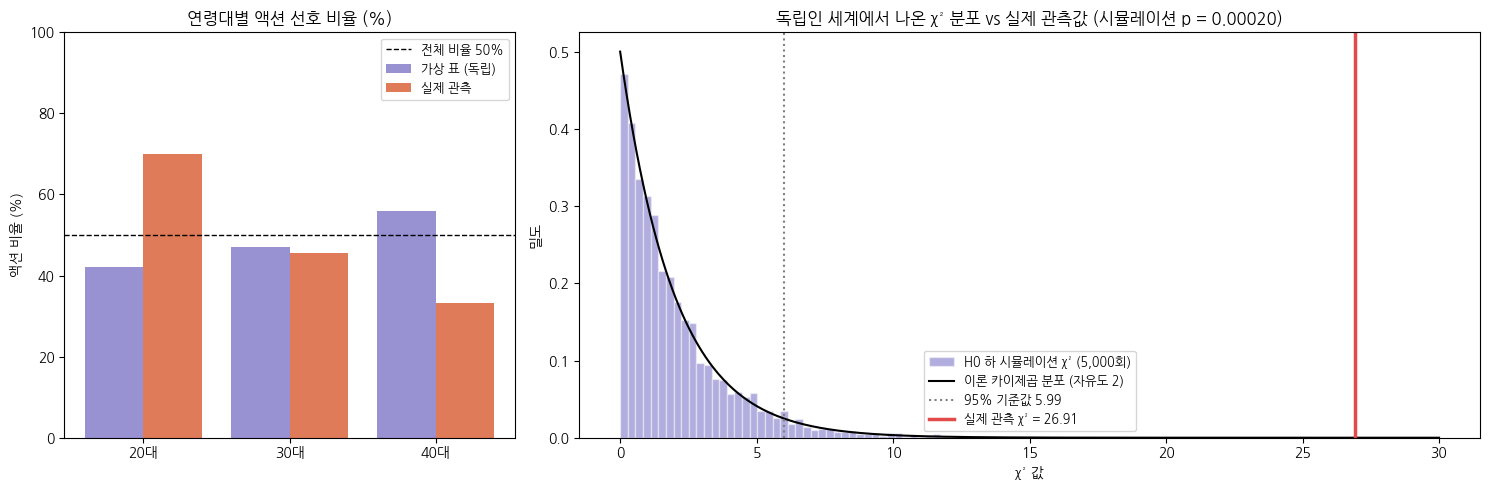

In [30]:
# [문제 4] Q3. H₀(연령대와 장르는 독립)가 사실이라고 가정한 시뮬레이션 5,000번
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# 한글 폰트 (나눔고딕이 설치돼 있으면 사용)
try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

data = {'액션': [70, 50, 30], '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])
total = int(observed.values.sum())                     # 300명
bar = "=" * 60

# 실제 관측된 카이제곱 통계량
chi2_obs, p_obs, dof, _ = stats.chi2_contingency(observed)

# ─────────────────────────────────────────────
# 1) 확률 설정 (힌트 1): 전체 비율을 그대로 확률로 사용
# ─────────────────────────────────────────────
age_prob = observed.sum(axis=1) / total               # 20대 1/3, 30대 0.367, 40대 0.3
genre_prob = observed.sum(axis=0) / total             # 액션 0.5, 로맨스 0.5

print(bar)
print("1) 시뮬레이션에 쓸 확률 (전체 비율)")
print(bar)
for k, v in age_prob.items():
    print(f"  P({k}) = {observed.sum(axis=1)[k]} / {total} = {v:.4f}")
for k, v in genre_prob.items():
    print(f"  P({k}) = {observed.sum(axis=0)[k]} / {total} = {v:.4f}")
print("\n  핵심: 연령대와 장르를 '따로따로' 뽑으므로 두 변수는 독립(H₀가 사실인 세계)")

# ─────────────────────────────────────────────
# 2) 시뮬레이션 5,000번 (힌트 2, 3)
# ─────────────────────────────────────────────
np.random.seed(42)
n_sim = 5000
sim_chi2 = []

for i in range(n_sim):
    ages = np.random.choice(age_prob.index, size=total, p=age_prob.values)        # 300명 연령대
    genres = np.random.choice(genre_prob.index, size=total, p=genre_prob.values)  # 300명 장르 (독립)
    table = pd.crosstab(pd.Series(ages, name='연령대'), pd.Series(genres, name='장르'))  # 가상 분할표
    table = table.reindex(index=observed.index, columns=observed.columns, fill_value=0)   # 순서 맞추기
    chi2_sim, _, _, _ = stats.chi2_contingency(table)
    sim_chi2.append(chi2_sim)
    if i == 0:
        example_table = table

sim_chi2 = np.array(sim_chi2)

print("\n" + bar)
print("2) 시뮬레이션 결과")
print(bar)
print("첫 번째 가상 분할표 예시 (독립인 세계에서 나온 표):")
print(example_table)
print(f"  → 이 표의 χ² = {sim_chi2[0]:.4f}  (실제 관측 {chi2_obs:.2f}보다 훨씬 작음)\n")
print(f"시뮬레이션 횟수        = {len(sim_chi2):,}")
print(f"가상 χ²들의 평균        = {sim_chi2.mean():.4f}  (이론상 자유도 {dof}와 같아야 함)")
print(f"가상 χ²들의 95% 지점    = {np.percentile(sim_chi2, 95):.4f}  "
      f"(이론 기준값 {stats.chi2.ppf(0.95, dof):.4f})")
print(f"가상 χ² 최댓값          = {sim_chi2.max():.4f}")

# ─────────────────────────────────────────────
# 3) 시뮬레이션 p-값
#    p = #{ 가상 χ² ≥ 관측 χ² } / 시뮬레이션 횟수
# ─────────────────────────────────────────────
count = np.sum(sim_chi2 >= chi2_obs)
p_sim = (count + 1) / (n_sim + 1)

print("\n" + bar)
print("3) 시뮬레이션 p-값")
print(bar)
print(f"공식:  p = (가상 χ² ≥ 관측 χ²인 횟수 + 1) / (시뮬레이션 횟수 + 1)")
print(f"  관측 χ² = {chi2_obs:.4f}")
print(f"  가상 χ² ≥ {chi2_obs:.2f} 인 횟수 = {count}번 / {n_sim:,}번")
print(f"  p = ({count} + 1) / ({n_sim} + 1) = {p_sim:.5f}")
print(f"  참고 - 이론 카이제곱 검정 p = {p_obs:.6f}")
print(f"\n  → 독립인 세계에서는 χ²가 {chi2_obs:.2f}까지 커지는 일이 거의 없음 → H₀ 기각")

# ─────────────────────────────────────────────
# 4) 그래프
# ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 2]})

# (1) 가상 분할표 예시 vs 실제 관측 (비율 비교)
ax = axes[0]
ex_pct = example_table.div(example_table.sum(axis=1), axis=0) * 100
ob_pct = observed.div(observed.sum(axis=1), axis=0) * 100
x = np.arange(3)
ax.bar(x - 0.2, ex_pct['액션'], 0.4, color='#534AB7', alpha=0.6, label='가상 표 (독립)')
ax.bar(x + 0.2, ob_pct['액션'], 0.4, color='#D85A30', alpha=0.8, label='실제 관측')
ax.axhline(50, color='k', ls='--', lw=1, label='전체 비율 50%')
ax.set_xticks(x, observed.index)
ax.set_ylim(0, 100)
ax.set_title('연령대별 액션 선호 비율 (%)')
ax.set_ylabel('액션 비율 (%)'); ax.legend(fontsize=9)

# (2) 가상 χ² 분포 + 이론 곡선 + 관측값
ax = axes[1]
ax.hist(sim_chi2, bins=60, density=True, color='#534AB7', alpha=0.45, edgecolor='white',
        label=f'H0 하 시뮬레이션 χ² ({n_sim:,}회)')
xs = np.linspace(0, max(30, chi2_obs + 3), 500)
ax.plot(xs, stats.chi2.pdf(xs, dof), 'k', lw=1.5, label=f'이론 카이제곱 분포 (자유도 {dof})')
crit = stats.chi2.ppf(0.95, dof)
ax.axvline(crit, color='gray', ls=':', lw=1.5, label=f'95% 기준값 {crit:.2f}')
ax.axvline(chi2_obs, color='#E24B4A', lw=2.5, label=f'실제 관측 χ² = {chi2_obs:.2f}')
ax.set_title(f'독립인 세계에서 나온 χ² 분포 vs 실제 관측값 (시뮬레이션 p = {p_sim:.5f})')
ax.set_xlabel('χ² 값'); ax.set_ylabel('밀도'); ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

실제 관찰된 χ²          = 26.9091
시뮬레이션 χ² 평균       = 2.0263
시뮬레이션 χ² 95% 지점   = 6.0710
시뮬레이션 χ² 최댓값     = 16.7552
관찰값 이상인 횟수       = 0 / 5,000
시뮬레이션 p-값          = (0 + 1) / (5000 + 1) = 0.00020


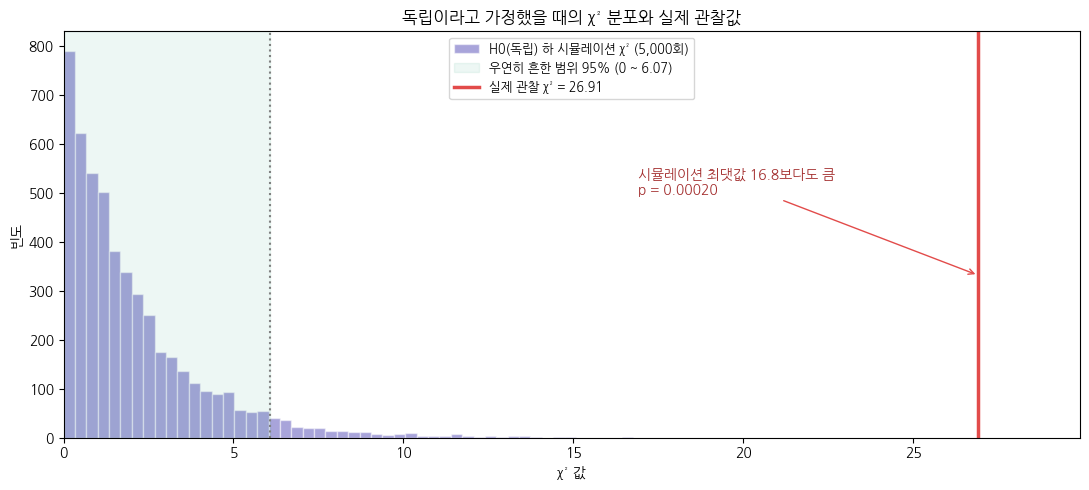

In [22]:
# [문제 4] Q4. 시뮬레이션 카이제곱 통계량 분포 히스토그램 + 실제 관찰값 세로선
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

data = {'액션': [70, 50, 30], '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])
total = int(observed.values.sum())
chi2_obs, p_obs, dof, _ = stats.chi2_contingency(observed)

# Q3를 이미 실행했다면 그 결과(sim_chi2)를 그대로 쓰고, 아니면 여기서 다시 만든다.
try:
    sim_chi2
except NameError:
    age_prob = observed.sum(axis=1) / total
    genre_prob = observed.sum(axis=0) / total
    np.random.seed(42)
    sim_chi2 = []
    for _ in range(5000):
        ages = np.random.choice(age_prob.index, size=total, p=age_prob.values)
        genres = np.random.choice(genre_prob.index, size=total, p=genre_prob.values)
        table = pd.crosstab(ages, genres)
        sim_chi2.append(stats.chi2_contingency(table)[0])
sim_chi2 = np.array(sim_chi2)

# 수치 요약
q95 = np.percentile(sim_chi2, 95)
count = np.sum(sim_chi2 >= chi2_obs)
p_sim = (count + 1) / (len(sim_chi2) + 1)

print(f"실제 관찰된 χ²          = {chi2_obs:.4f}")
print(f"시뮬레이션 χ² 평균       = {sim_chi2.mean():.4f}")
print(f"시뮬레이션 χ² 95% 지점   = {q95:.4f}")
print(f"시뮬레이션 χ² 최댓값     = {sim_chi2.max():.4f}")
print(f"관찰값 이상인 횟수       = {count} / {len(sim_chi2):,}")
print(f"시뮬레이션 p-값          = ({count} + 1) / ({len(sim_chi2)} + 1) = {p_sim:.5f}")

# 히스토그램 + 관찰값 세로선
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(sim_chi2, bins=50, color='#534AB7', alpha=0.5, edgecolor='white',
        label=f'H0(독립) 하 시뮬레이션 χ² ({len(sim_chi2):,}회)')
ax.axvspan(0, q95, color='#1D9E75', alpha=0.08, label=f'우연히 흔한 범위 95% (0 ~ {q95:.2f})')
ax.axvline(q95, color='gray', ls=':', lw=1.5)
ax.axvline(chi2_obs, color='#E24B4A', lw=2.5, label=f'실제 관찰 χ² = {chi2_obs:.2f}')
ax.annotate(f'시뮬레이션 최댓값 {sim_chi2.max():.1f}보다도 큼\np = {p_sim:.5f}',
            xy=(chi2_obs, ax.get_ylim()[1] * 0.4), xytext=(chi2_obs - 10, ax.get_ylim()[1] * 0.6),
            arrowprops=dict(arrowstyle='->', color='#E24B4A'), fontsize=10, color='#A32D2D')
ax.set_xlim(0, chi2_obs + 3)
ax.set_title('독립이라고 가정했을 때의 χ² 분포와 실제 관찰값')
ax.set_xlabel('χ² 값'); ax.set_ylabel('빈도')
ax.legend(fontsize=9, loc='upper center')
plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- '기대 빈도'는 어떤 의미를 가지며, '관측 빈도'와의 차이가 클수록 카이제곱 통계량은 어떻게 변할까요?

- Q4의 히스토그램은 어떤 분포를 시각화한 것인가요? 실제 관찰된 카이제곱 통계량(세로선)은 흔한 값인가요, 극단적인 값인가요?

- 유의수준 0.05에서, 연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다고 결론 내릴 수 있나요? 그 이유는 무엇인가요?

- 이 결과를 바탕으로 영화관은 연령대별로 어떤 상영 전략이나 프로모션을 세울 수 있을까요?

In [23]:
# 🧠 데이터를 어떻게 읽을까요? — 실행하면 계산된 값으로 해석이 출력됩니다.
import numpy as np
import pandas as pd
from scipy import stats

data = {'액션': [70, 50, 30], '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])
total = int(observed.values.sum())
alpha = 0.05

# ── 카이제곱 검정 ─────────────────────────────────
chi2_obs, p_value, dof, expected = stats.chi2_contingency(observed)
expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
contrib = (observed - expected_df) ** 2 / expected_df
crit = stats.chi2.ppf(1 - alpha, dof)
row_pct = observed.div(observed.sum(axis=1), axis=0) * 100
row_sum, col_sum = observed.sum(axis=1), observed.sum(axis=0)

# ── 시뮬레이션 (Q3를 실행했다면 그 결과 사용) ─────────
try:
    sim_chi2
except NameError:
    age_prob, genre_prob = row_sum / total, col_sum / total
    np.random.seed(42)
    sim_chi2 = []
    for _ in range(5000):
        ages = np.random.choice(age_prob.index, size=total, p=age_prob.values)
        genres = np.random.choice(genre_prob.index, size=total, p=genre_prob.values)
        sim_chi2.append(stats.chi2_contingency(pd.crosstab(ages, genres))[0])
sim_chi2 = np.array(sim_chi2)
q95 = np.percentile(sim_chi2, 95)
count = np.sum(sim_chi2 >= chi2_obs)
p_sim = (count + 1) / (len(sim_chi2) + 1)

line = "─" * 70

# ① 기대 빈도의 의미
print(line)
print("① '기대 빈도'의 의미와 관측 빈도와의 차이에 따른 카이제곱 통계량 변화")
print(line)
print("- 기대 빈도: 연령대와 장르가 독립(H₀)이라면 각 칸에 나왔어야 할 인원 수")
print("- 계산: 기대 빈도 = (행 합계 × 열 합계) / 전체 합계")
r0, c0 = observed.index[0], observed.columns[0]
print(f"  예) {r0} {c0} = ({row_sum[r0]} × {col_sum[c0]}) / {total} = {expected_df.loc[r0, c0]:.0f}명")
print(f"- 전체 장르 비율이 " + ", ".join(f"{c} {col_sum[c]/total*100:.0f}%" for c in observed.columns)
      + " 이므로, 독립이라면 모든 연령대가 이 비율이어야 함")
print("- χ² = Σ(관측 - 기대)² / 기대 → 차이가 클수록 χ²는 커짐 (제곱이라 빠르게 커짐)")
print("- 연령대별 기여도:")
for r in observed.index:
    diff = abs(observed.loc[r].iloc[0] - expected_df.loc[r].iloc[0])
    print(f"    {r}: 차이 {diff:.0f}명 → 칸당 {contrib.loc[r].iloc[0]:.2f}, "
          f"합계 {contrib.loc[r].sum():.2f} ({contrib.loc[r].sum()/chi2_obs*100:.1f}%)")
big = contrib.sum(axis=1).sort_values(ascending=False)
print(f"  → {big.index[0]}와 {big.index[1]}가 χ² {chi2_obs:.2f}의 대부분을 차지, "
      f"{big.index[-1]}는 기대 빈도와 비슷\n")

# ② 히스토그램 해석
print(line)
print("② Q4 히스토그램이 시각화한 분포와 관찰값의 위치")
print(line)
print(f"- H₀(독립)가 사실인 세계에서 {total}명을 조사했을 때 나올 수 있는 χ²의 분포")
print(f"  ({len(sim_chi2):,}번 시뮬레이션)")
print(f"- 시뮬레이션 χ²: 평균 {sim_chi2.mean():.2f}, 95% 지점 {q95:.2f}, 최댓값 {sim_chi2.max():.2f}")
print(f"- 실제 관찰 χ² = {chi2_obs:.2f}")
if chi2_obs > sim_chi2.max():
    pos = "시뮬레이션 최댓값보다도 큼"
elif chi2_obs > q95:
    pos = "95% 범위를 벗어남"
else:
    pos = "95% 범위 안에 있음"
kind = "극단적인 값" if chi2_obs > q95 else "흔한 값"
print(f"  → {pos} → {kind}")
print(f"  ({len(sim_chi2):,}번 중 {count}번 → 시뮬레이션 p = {p_sim:.5f})\n")

# ③ 결론
print(line)
print(f"③ 유의수준 {alpha}에서의 결론")
print(line)
reject = p_value < alpha
print(f"- 결론: {'연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다 (H₀ 기각)' if reject else '유의미한 연관성이 있다고 할 수 없다 (H₀ 기각 못 함)'}")
print("- 이유:")
print(f"   1) 카이제곱 검정 p-값 = {p_value:.6f} {'<' if reject else '≥'} {alpha}")
print(f"   2) 관찰 χ² = {chi2_obs:.2f} {'>' if chi2_obs > crit else '≤'} 자유도 {dof}의 기준값 {crit:.2f}")
print(f"   3) 시뮬레이션 p = {p_sim:.5f}")
print("- 방향 (연령대별 비율):")
for r in observed.index:
    top = row_pct.loc[r].idxmax()
    print(f"    {r}: " + ", ".join(f"{c} {row_pct.loc[r, c]:.1f}%" for c in observed.columns)
          + f"  → {top} 선호")
trend = row_pct[observed.columns[1]]
if trend.is_monotonic_increasing:
    print(f"  → 나이가 많을수록 {observed.columns[1]} 선호가 커지는 경향\n")
else:
    print()

# ④ 전략
print(line)
print("④ 영화관의 연령대별 상영 전략 / 프로모션")
print(line)
for r in observed.index:
    top = row_pct.loc[r].idxmax()
    gap = row_pct.loc[r].max() - row_pct.loc[r].min()
    if gap < 15:
        print(f"- {r} (차이 {gap:.1f}%p, 고른 선호): 두 장르 묶음 할인, 예매 이력 기반 맞춤 추천")
    elif top == '액션':
        print(f"- {r} ({top} {row_pct.loc[r].max():.0f}%): 액션을 주말 저녁·심야에 집중 편성, "
              "개봉작 사전 예매·굿즈 프로모션")
    else:
        print(f"- {r} ({top} {row_pct.loc[r].max():.0f}%): 로맨스를 평일 낮·이른 저녁에 배치, "
              "커플 할인·프리미엄관 연계")
print("- 공통: 같은 영화라도 연령대별 광고 문구와 노출 채널을 다르게 운영")
print(f"- 주의: 설문 {total}명의 '선호'이며 인과관계가 아닌 연관성 → 시범 운영 후 실제 매출로 재검증")

──────────────────────────────────────────────────────────────────────
① '기대 빈도'의 의미와 관측 빈도와의 차이에 따른 카이제곱 통계량 변화
──────────────────────────────────────────────────────────────────────
- 기대 빈도: 연령대와 장르가 독립(H₀)이라면 각 칸에 나왔어야 할 인원 수
- 계산: 기대 빈도 = (행 합계 × 열 합계) / 전체 합계
  예) 20대 액션 = (100 × 150) / 300 = 50명
- 전체 장르 비율이 액션 50%, 로맨스 50% 이므로, 독립이라면 모든 연령대가 이 비율이어야 함
- χ² = Σ(관측 - 기대)² / 기대 → 차이가 클수록 χ²는 커짐 (제곱이라 빠르게 커짐)
- 연령대별 기여도:
    20대: 차이 20명 → 칸당 8.00, 합계 16.00 (59.5%)
    30대: 차이 5명 → 칸당 0.45, 합계 0.91 (3.4%)
    40대: 차이 15명 → 칸당 5.00, 합계 10.00 (37.2%)
  → 20대와 40대가 χ² 26.91의 대부분을 차지, 30대는 기대 빈도와 비슷

──────────────────────────────────────────────────────────────────────
② Q4 히스토그램이 시각화한 분포와 관찰값의 위치
──────────────────────────────────────────────────────────────────────
- H₀(독립)가 사실인 세계에서 300명을 조사했을 때 나올 수 있는 χ²의 분포
  (5,000번 시뮬레이션)
- 시뮬레이션 χ²: 평균 2.03, 95% 지점 6.07, 최댓값 16.76
- 실제 관찰 χ² = 26.91
  → 시뮬레이션 최댓값보다도 큼 → 극단적인 값
  (5,000번 중 0번 → 시뮬레이션 p = 0.00020)

────────────────────────────────

# 문제 5. 미니 프로젝트 - 어떤 신규 비료가 가장 효과적일까? (난이도: 상)

**📘 문제**

- 한 농업 연구소에서 새로 개발한 비료 3종류(A, B, C)의 생산량 증대 효과를 비교하고자 합니다.

- 동일한 조건의 밭 30개를 준비하여, 각각 10개씩 비료 A, B, C를 투여한 후 수확량을 측정했습니다.

- 이번 실습에서는 **분산분석(ANOVA)**으로 세 비료 간 평균 수확량에 차이가 있는지 검증하고,
  차이가 있다면 **사후분석(Tukey's HSD)**으로 어떤 비료끼리 차이가 나는지 확인합니다.

- 마지막으로 **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량이 나올 수 있는지 시뮬레이션하고,
  분석 결과를 바탕으로 연구소에 어떤 비료를 추천할지까지 생각해 봅니다.

In [33]:
# 데이터 생성 (비료 종류별 수확량)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)

# 데이터프레임으로 변환 (사후분석을 위해)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

# 데이터 탐색 시각화
sns.boxplot(x='비료종류', y='수확량', data=df)
plt.title("비료 종류에 따른 수확량 분포")
plt.show()

: [0;31m---------------------------------------------------------------------------[0m
[0;31mNameError[0m                                 Traceback (most recent call last)
[0;32m/tmp/ipykernel_1567/3181476307.py[0m in [0;36m<cell line: 0>[0;34m()[0m
[1;32m     10[0m [0;34m[0m[0m
[1;32m     11[0m [0;31m# 데이터 탐색 시각화[0m[0;34m[0m[0;34m[0m[0m
[0;32m---> 12[0;31m [0msns[0m[0;34m.[0m[0mboxplot[0m[0;34m([0m[0mx[0m[0;34m=[0m[0;34m'비료종류'[0m[0;34m,[0m [0my[0m[0;34m=[0m[0;34m'수확량'[0m[0;34m,[0m [0mdata[0m[0;34m=[0m[0mdf[0m[0;34m)[0m[0;34m[0m[0;34m[0m[0m
[0m[1;32m     13[0m [0mplt[0m[0;34m.[0m[0mtitle[0m[0;34m([0m[0;34m"비료 종류에 따른 수확량 분포"[0m[0;34m)[0m[0;34m[0m[0;34m[0m[0m
[1;32m     14[0m [0mplt[0m[0;34m.[0m[0mshow[0m[0;34m([0m[0;34m)[0m[0;34m[0m[0;34m[0m[0m

[0;31mNameError[0m: name 'sns' is not defined

**📌 아래를 수행해 보세요:**

- 세 그룹에 대해 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.

- ANOVA 결과가 유의미할 경우에만 **Tukey's HSD 사후분석**을 수행하고 결과를 해석해 봅시다.

- **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량들이 나오는지 5,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 F-통계량이 얼마나 극단적인 값인지 확인해 봅시다.

- 분석 결과를 종합하여 연구소에 추천할 비료를 정해 봅시다.

ANOVA 결과
F-통계량: 10.3455
p-값: 0.000462

공식 대입 풀이
전체 평균 = 111.8109
  A: n = 10, 평균 = 102.3048
  B: n = 10, 평균 = 125.9802
  C: n = 10, 평균 = 107.1478

[1] 집단 간 제곱합  SSB = Σ nᵢ (그룹평균 - 전체평균)²
    = 10×(102.30 - 111.81)² + 10×(125.98 - 111.81)² + 10×(107.15 - 111.81)²
    = 3128.7969

[2] 집단 내 제곱합  SSW = ΣΣ (각 값 - 자기 그룹평균)²
    = 1528.45 + 1700.63 + 853.73  (A, B, C 각각)
    = 4082.8104

[3] 자유도: 집단 간 = k - 1 = 3 - 1 = 2,  집단 내 = N - k = 30 - 3 = 27
[4] 평균제곱: MSB = SSB / 2 = 1564.3984,  MSW = SSW / 27 = 151.2152
[5] F = MSB / MSW = 1564.3984 / 151.2152 = 10.3455
[6] p = P(F(2, 27) ≥ 10.35) = 0.000462

ANOVA 표:
         제곱합(SS)  자유도(df) 평균제곱(MS)        F    p-값
집단 간   3128.7969           2    1564.3984  10.3455  0.0005
집단 내   4082.8104          27     151.2152                 
전체      7211.6073          29                              

판정 (α = 0.05): 기준값 F = 3.35
  p = 0.000462 < 0.05 → H₀ 기각 (적어도 하나의 비료 평균 수확량이 다르다)
  → 어느 비료가 다른지는 사후분석(Tukey HSD 등)으로 확인 필요


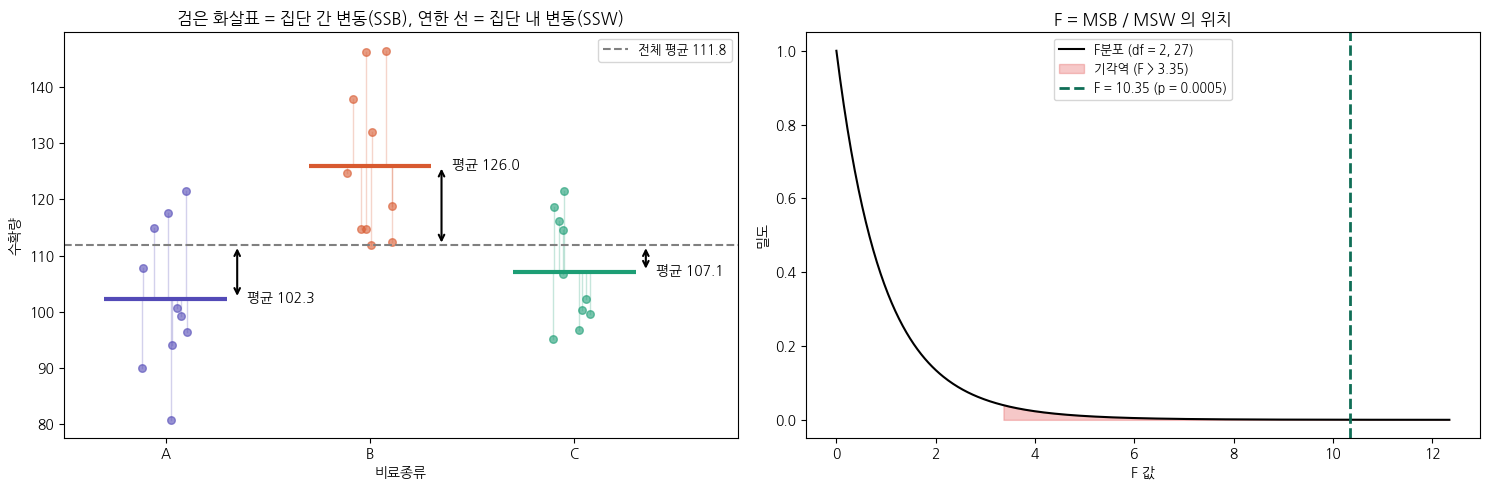

In [24]:
# [문제 5] Q1. 일원분산분석(One-way ANOVA)
# H₀: 세 비료의 평균 수확량은 모두 같다.
# H₁: 적어도 하나 이상의 비료 평균 수확량은 다르다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

# 데이터 (주어진 코드와 동일)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

groups = {'A': fertilizer_a, 'B': fertilizer_b, 'C': fertilizer_c}
k = len(groups)
N = len(df)
grand_mean = df['수확량'].mean()
bar = "=" * 60

# ─────────────────────────────────────────────
# 1) scipy로 ANOVA
# ─────────────────────────────────────────────
f_stat, p_value = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)
print(bar)
print("ANOVA 결과")
print(bar)
print(f"F-통계량: {f_stat:.4f}")
print(f"p-값: {p_value:.6f}")

# ─────────────────────────────────────────────
# 2) 공식 대입 풀이
#    F = 집단 간 평균제곱(MSB) / 집단 내 평균제곱(MSW)
# ─────────────────────────────────────────────
print("\n" + bar)
print("공식 대입 풀이")
print(bar)
print(f"전체 평균 = {grand_mean:.4f}")
for g, x in groups.items():
    print(f"  {g}: n = {len(x)}, 평균 = {x.mean():.4f}")

# 집단 간 제곱합: 각 집단 평균이 전체 평균에서 얼마나 떨어졌나
SSB = sum(len(x) * (x.mean() - grand_mean) ** 2 for x in groups.values())
print("\n[1] 집단 간 제곱합  SSB = Σ nᵢ (그룹평균 - 전체평균)²")
print("    = " + " + ".join(f"{len(x)}×({x.mean():.2f} - {grand_mean:.2f})²" for x in groups.values()))
print(f"    = {SSB:.4f}")

# 집단 내 제곱합: 각 값이 자기 집단 평균에서 얼마나 흩어졌나
SSW = sum(np.sum((x - x.mean()) ** 2) for x in groups.values())
print("\n[2] 집단 내 제곱합  SSW = ΣΣ (각 값 - 자기 그룹평균)²")
print("    = " + " + ".join(f"{np.sum((x - x.mean()) ** 2):.2f}" for x in groups.values())
      + f"  (A, B, C 각각)")
print(f"    = {SSW:.4f}")

df_b, df_w = k - 1, N - k
MSB, MSW = SSB / df_b, SSW / df_w
print(f"\n[3] 자유도: 집단 간 = k - 1 = {k} - 1 = {df_b},  집단 내 = N - k = {N} - {k} = {df_w}")
print(f"[4] 평균제곱: MSB = SSB / {df_b} = {MSB:.4f},  MSW = SSW / {df_w} = {MSW:.4f}")

F_manual = MSB / MSW
p_manual = 1 - stats.f.cdf(F_manual, df_b, df_w)
crit = stats.f.ppf(0.95, df_b, df_w)
print(f"[5] F = MSB / MSW = {MSB:.4f} / {MSW:.4f} = {F_manual:.4f}")
print(f"[6] p = P(F({df_b}, {df_w}) ≥ {F_manual:.2f}) = {p_manual:.6f}")

# ANOVA 표
anova_table = pd.DataFrame({
    '제곱합(SS)': [SSB, SSW, SSB + SSW],
    '자유도(df)': [df_b, df_w, N - 1],
    '평균제곱(MS)': [MSB, MSW, np.nan],
    'F': [F_manual, np.nan, np.nan],
    'p-값': [p_manual, np.nan, np.nan]}, index=['집단 간', '집단 내', '전체'])
print("\nANOVA 표:")
print(anova_table.round(4).fillna(''))

alpha = 0.05
print(f"\n판정 (α = {alpha}): 기준값 F = {crit:.2f}")
if p_value < alpha:
    print(f"  p = {p_value:.6f} < {alpha} → H₀ 기각 (적어도 하나의 비료 평균 수확량이 다르다)")
    print("  → 어느 비료가 다른지는 사후분석(Tukey HSD 등)으로 확인 필요")
else:
    print(f"  p = {p_value:.6f} ≥ {alpha} → H₀ 기각 못 함")

# ─────────────────────────────────────────────
# 3) 그래프
# ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {'A': '#534AB7', 'B': '#D85A30', 'C': '#1D9E75'}

# (1) 집단 간 vs 집단 내 변동
ax = axes[0]
for i, (g, x) in enumerate(groups.items()):
    jitter = np.random.default_rng(i).uniform(-0.12, 0.12, len(x))
    ax.scatter(np.full(len(x), i) + jitter, x, color=colors[g], alpha=0.6, s=30)
    for xi, j in zip(x, jitter):   # 집단 내 변동: 값 → 그룹 평균
        ax.plot([i + j, i + j], [xi, x.mean()], color=colors[g], alpha=0.25, lw=1)
    ax.hlines(x.mean(), i - 0.3, i + 0.3, color=colors[g], lw=3)
    ax.annotate('', xy=(i + 0.35, x.mean()), xytext=(i + 0.35, grand_mean),
                arrowprops=dict(arrowstyle='<->', color='k', lw=1.5))
    ax.text(i + 0.4, x.mean(), f'평균 {x.mean():.1f}', va='center', fontsize=10)
ax.axhline(grand_mean, color='gray', ls='--', lw=1.5, label=f'전체 평균 {grand_mean:.1f}')
ax.set_xticks(range(k), list(groups.keys()))
ax.set_xlim(-0.5, k - 0.2)
ax.set_title('검은 화살표 = 집단 간 변동(SSB), 연한 선 = 집단 내 변동(SSW)')
ax.set_xlabel('비료종류'); ax.set_ylabel('수확량'); ax.legend(fontsize=9)

# (2) F분포 위 검정통계량
ax = axes[1]
xs = np.linspace(0, max(12, F_manual + 2), 500)
ys = stats.f.pdf(xs, df_b, df_w)
ax.plot(xs, ys, 'k', lw=1.5, label=f'F분포 (df = {df_b}, {df_w})')
ax.fill_between(xs, ys, where=xs >= crit, color='#E24B4A', alpha=0.3, label=f'기각역 (F > {crit:.2f})')
ax.axvline(F_manual, color='#0F6E56', lw=2, ls='--', label=f'F = {F_manual:.2f} (p = {p_value:.4f})')
ax.set_title('F = MSB / MSW 의 위치')
ax.set_xlabel('F 값'); ax.set_ylabel('밀도'); ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

ANOVA: F = 10.3455, p = 0.000462
p < 0.05 → 적어도 하나가 다름 → 어느 쌍이 다른지 Tukey HSD 수행

Tukey HSD 결과
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------

공식 대입 풀이
MSW (Q1에서 구한 집단 내 평균제곱) = 151.2152
표준오차 √(MSW / n) = √(151.22 / 10) = 3.8886
임계 q값 q(α=0.05, k=3, df=27) = 3.5064  (스튜던트화 범위분포)
HSD = q × √(MSW/n) = 3.5064 × 3.8886 = 13.6352
  → 두 비료 평균 차이가 13.64보다 크면 '유의하게 다르다'

  A vs B: 차이 = 125.98 - 102.30 = +23.68  |  |차이| 23.68 > HSD 13.64  →  유의함 (q = 6.09, p = 0.0006)
  A vs C: 차이 = 107.15 - 102.30 = +4.84  |  |차이| 4.84 < HSD 13.64  →  유의하지 않음 (q = 1.25, p = 0.6569)
  B vs C: 차이 = 107.15 - 125.98 = -18.83  |  |차이| 18.83 > HSD 13.64  →  유의함 (q = 4.84, p = 0.0054)


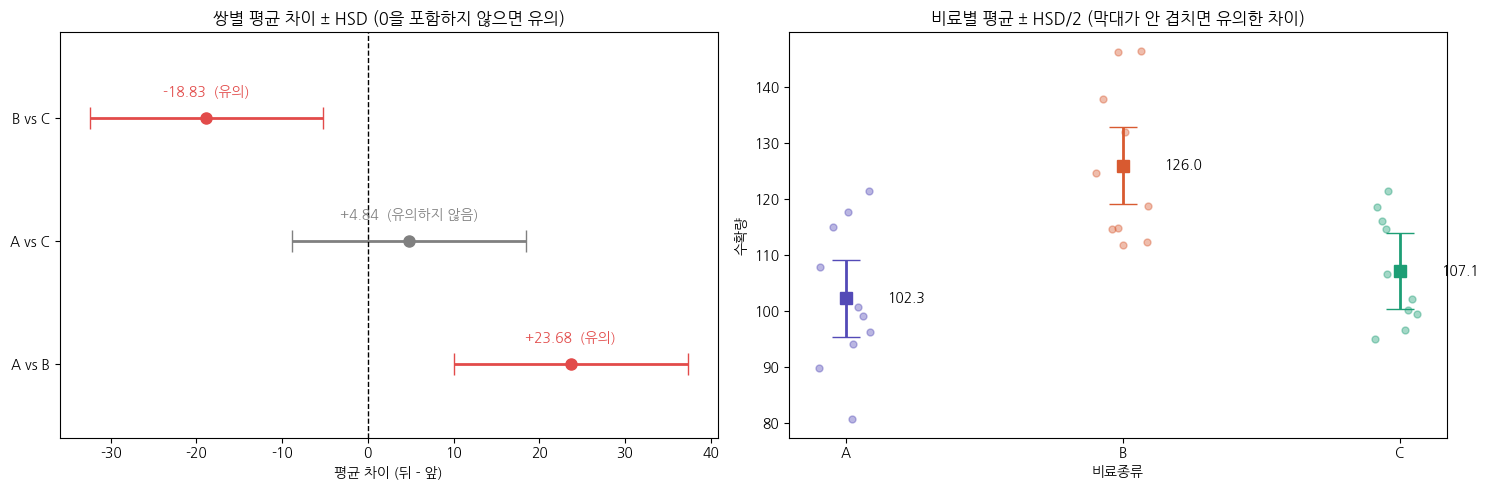

In [25]:
# [문제 5] Q2. ANOVA가 유의할 때만 Tukey's HSD 사후분석
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

# 데이터 (주어진 코드와 동일)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

alpha = 0.05
bar = "=" * 60

# ── ANOVA 먼저 ────────────────────────────────────
f_stat, p_value = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)
print(f"ANOVA: F = {f_stat:.4f}, p = {p_value:.6f}")

if p_value < alpha:
    print(f"p < {alpha} → 적어도 하나가 다름 → 어느 쌍이 다른지 Tukey HSD 수행\n")

    # ── Tukey HSD ─────────────────────────────────
    tukey = pairwise_tukeyhsd(endog=df['수확량'], groups=df['비료종류'], alpha=alpha)
    print(bar)
    print("Tukey HSD 결과")
    print(bar)
    print(tukey)

    # ── 공식 대입 풀이 ────────────────────────────
    #   HSD = q(α, k, N-k) × √(MSW / n)
    #   두 평균 차이가 HSD보다 크면 유의
    groups = {'A': fertilizer_a, 'B': fertilizer_b, 'C': fertilizer_c}
    k, N, n = 3, len(df), 10
    MSW = sum(np.sum((x - x.mean()) ** 2) for x in groups.values()) / (N - k)
    q_crit = stats.studentized_range.ppf(1 - alpha, k, N - k)
    se = np.sqrt(MSW / n)
    HSD = q_crit * se

    print("\n" + bar)
    print("공식 대입 풀이")
    print(bar)
    print(f"MSW (Q1에서 구한 집단 내 평균제곱) = {MSW:.4f}")
    print(f"표준오차 √(MSW / n) = √({MSW:.2f} / {n}) = {se:.4f}")
    print(f"임계 q값 q(α={alpha}, k={k}, df={N-k}) = {q_crit:.4f}  (스튜던트화 범위분포)")
    print(f"HSD = q × √(MSW/n) = {q_crit:.4f} × {se:.4f} = {HSD:.4f}")
    print(f"  → 두 비료 평균 차이가 {HSD:.2f}보다 크면 '유의하게 다르다'\n")

    rows = []
    names = list(groups.keys())
    for i in range(k):
        for j in range(i + 1, k):
            g1, g2 = names[i], names[j]
            diff = groups[g2].mean() - groups[g1].mean()
            q = abs(diff) / se
            p_pair = stats.studentized_range.sf(q, k, N - k)
            sig = abs(diff) > HSD
            print(f"  {g1} vs {g2}: 차이 = {groups[g2].mean():.2f} - {groups[g1].mean():.2f} = {diff:+.2f}"
                  f"  |  |차이| {abs(diff):.2f} {'>' if sig else '<'} HSD {HSD:.2f}"
                  f"  →  {'유의함' if sig else '유의하지 않음'} (q = {q:.2f}, p = {p_pair:.4f})")
            rows.append((f'{g1} vs {g2}', diff, sig))

    # ── 그래프 ────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    colors = {'A': '#534AB7', 'B': '#D85A30', 'C': '#1D9E75'}

    # (1) 쌍별 평균 차이와 95% 동시 신뢰구간
    ax = axes[0]
    for idx, (label, diff, sig) in enumerate(rows):
        c = '#E24B4A' if sig else 'gray'
        ax.errorbar(diff, idx, xerr=HSD, fmt='o', color=c, capsize=8, ms=8, lw=2)
        ax.text(diff, idx + 0.18, f'{diff:+.2f}  ({"유의" if sig else "유의하지 않음"})',
                ha='center', fontsize=10, color=c)
    ax.axvline(0, color='k', ls='--', lw=1)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows])
    ax.set_ylim(-0.6, len(rows) - 0.3)
    ax.set_title('쌍별 평균 차이 ± HSD (0을 포함하지 않으면 유의)')
    ax.set_xlabel('평균 차이 (뒤 - 앞)')

    # (2) 비료별 평균과 Tukey 동시 신뢰구간
    ax = axes[1]
    for i, (g, x) in enumerate(groups.items()):
        ax.scatter(np.full(len(x), i) + np.random.default_rng(i).uniform(-0.1, 0.1, len(x)), x,
                   color=colors[g], alpha=0.4, s=25)
        ax.errorbar(i, x.mean(), yerr=HSD / 2, fmt='s', color=colors[g], capsize=10, ms=9, lw=2)
        ax.text(i + 0.15, x.mean(), f'{x.mean():.1f}', va='center', fontsize=10)
    ax.set_xticks(range(k), names)
    ax.set_title('비료별 평균 ± HSD/2 (막대가 안 겹치면 유의한 차이)')
    ax.set_xlabel('비료종류'); ax.set_ylabel('수확량')

    plt.tight_layout()
    plt.show()
else:
    print(f"p ≥ {alpha} → 평균 차이가 유의하지 않으므로 사후분석을 수행하지 않음")

In [ ]:
# [문제 5] Q3. H₀가 사실(세 그룹의 평균이 모두 같다)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 모든 데이터를 합친 평균과 표준편차를 가진 H₀ 모집단에서 10개씩 3개의 가상 그룹을 생성하고,
# 이 가상 그룹들로 ANOVA를 수행하여 F-통계량을 리스트에 저장해보세요.

# 여기에 코드를 작성해주세요.

실제 관찰된 F          = 10.3455
시뮬레이션 F 평균       = 1.1150
시뮬레이션 F 95% 지점   = 3.5098
시뮬레이션 F 최댓값     = 13.5796
관찰값 이상인 횟수      = 3 / 5,000
시뮬레이션 p-값         = (3 + 1) / (5000 + 1) = 0.00080
이론 ANOVA p-값         = 0.000462


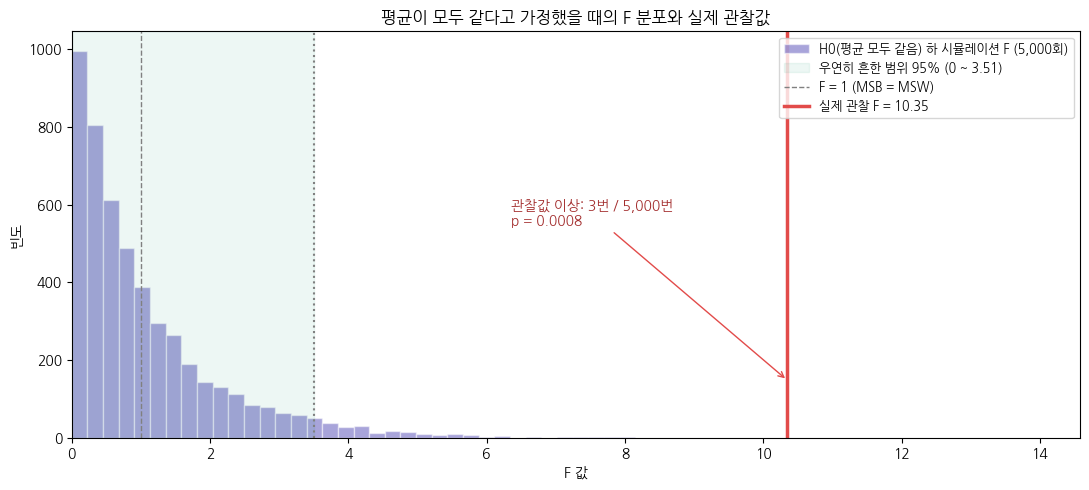

In [26]:
# [문제 5] Q4. 시뮬레이션 F-통계량 분포 히스토그램 + 실제 관찰값 세로선
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

# 데이터 (주어진 코드와 동일)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)
all_data = np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c])
f_obs, p_obs = stats.f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)

# Q3를 이미 실행했다면 그 결과(sim_f)를 그대로 쓰고, 아니면 여기서 다시 만든다.
try:
    sim_f
except NameError:
    pop_mean, pop_sd = all_data.mean(), all_data.std(ddof=1)
    np.random.seed(42)
    sim_f = [stats.f_oneway(*[np.random.normal(pop_mean, pop_sd, 10) for _ in range(3)])[0]
             for _ in range(5000)]
sim_f = np.array(sim_f)

# 수치 요약
q95 = np.percentile(sim_f, 95)
count = np.sum(sim_f >= f_obs)
p_sim = (count + 1) / (len(sim_f) + 1)

print(f"실제 관찰된 F          = {f_obs:.4f}")
print(f"시뮬레이션 F 평균       = {sim_f.mean():.4f}")
print(f"시뮬레이션 F 95% 지점   = {q95:.4f}")
print(f"시뮬레이션 F 최댓값     = {sim_f.max():.4f}")
print(f"관찰값 이상인 횟수      = {count} / {len(sim_f):,}")
print(f"시뮬레이션 p-값         = ({count} + 1) / ({len(sim_f)} + 1) = {p_sim:.5f}")
print(f"이론 ANOVA p-값         = {p_obs:.6f}")

# 히스토그램 + 관찰값 세로선
fig, ax = plt.subplots(figsize=(11, 5))
counts, bins, patches = ax.hist(sim_f, bins=60, color='#534AB7', alpha=0.5, edgecolor='white',
                                label=f'H0(평균 모두 같음) 하 시뮬레이션 F ({len(sim_f):,}회)')
for patch, left in zip(patches, bins[:-1]):      # 관찰값 이상 구간은 빨간색
    if left >= f_obs:
        patch.set_facecolor('#E24B4A'); patch.set_alpha(0.8)

ax.axvspan(0, q95, color='#1D9E75', alpha=0.08, label=f'우연히 흔한 범위 95% (0 ~ {q95:.2f})')
ax.axvline(q95, color='gray', ls=':', lw=1.5)
ax.axvline(1, color='gray', ls='--', lw=1, label='F = 1 (MSB = MSW)')
ax.axvline(f_obs, color='#E24B4A', lw=2.5, label=f'실제 관찰 F = {f_obs:.2f}')
ax.annotate(f'관찰값 이상: {count}번 / {len(sim_f):,}번\np = {p_sim:.4f}',
            xy=(f_obs, max(counts) * 0.15), xytext=(f_obs - 4, max(counts) * 0.55),
            arrowprops=dict(arrowstyle='->', color='#E24B4A'), fontsize=10, color='#A32D2D')
ax.set_xlim(0, max(sim_f.max(), f_obs) + 1)
ax.set_title('평균이 모두 같다고 가정했을 때의 F 분포와 실제 관찰값')
ax.set_xlabel('F 값'); ax.set_ylabel('빈도')
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

──────────────────────────────────────────────────────────────────────
[문제 5] Q5. 연구소에 대한 비료 추천 의견
──────────────────────────────────────────────────────────────────────
비료별 요약:
     평균  표준편차  95% CI 하한  95% CI 상한
A  102.30     13.03        92.98       111.63
B  125.98     13.75       116.15       135.81
C  107.15      9.74       100.18       114.12

1) ANOVA: F = 10.35, p = 0.000462 < 0.05 → 비료 종류에 따라 수확량이 다름
   효과 크기 η² = SSB / SST = 3128.8 / 7211.6 = 0.434 → 수확량 변동의 43.4%를 비료 종류가 설명 (큰 효과)

2) Tukey HSD 사후분석:
   B vs A: B가 +23.68 높음 (+23.1%), p-adj = 0.0006 → 유의함
   B vs C: B가 +18.83 높음 (+17.6%), p-adj = 0.0054 → 유의함
   A vs C: p-adj = 0.6569 → 유의하지 않음

3) 시뮬레이션: 평균이 모두 같다면 F가 이만큼 커지는 일은 5,000번 중 극소수 (p < 0.001)

──────────────────────────────────────────────────────────────────────
▶ 추천 의견
──────────────────────────────────────────────────────────────────────
- 비료 B를 추천한다.
  · B의 평균 수확량 126.0은 A(102.3), C(107.1)보다 통계적으로 유의하게 높다.
  · 효과 크기도 커서(η² = 0.43) 실무적으로도 의미 있는 차이다.
  · A와 C는 

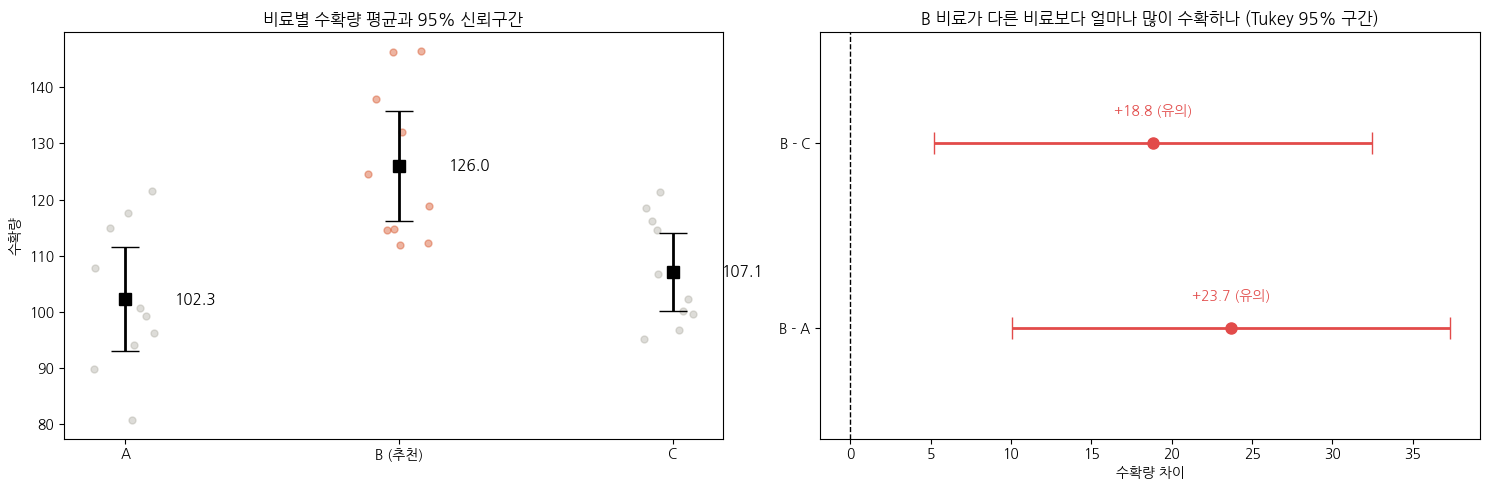

In [27]:
# [문제 5] Q5. 분석 결과를 바탕으로 한 비료 추천 (실행하면 계산된 값으로 의견이 출력됨)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

# 데이터 (주어진 코드와 동일)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})
groups = {'A': fertilizer_a, 'B': fertilizer_b, 'C': fertilizer_c}
alpha = 0.05

# ── 근거 계산 ─────────────────────────────────────
f_stat, p_anova = stats.f_oneway(*groups.values())
tukey = pairwise_tukeyhsd(df['수확량'], df['비료종류'], alpha=alpha)
tk = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])

grand = df['수확량'].mean()
SSB = sum(len(x) * (x.mean() - grand) ** 2 for x in groups.values())
SST = np.sum((df['수확량'] - grand) ** 2)
eta2 = SSB / SST                                   # 효과 크기: 비료가 설명하는 변동 비율

summary = pd.DataFrame({
    '평균': {g: x.mean() for g, x in groups.items()},
    '표준편차': {g: x.std(ddof=1) for g, x in groups.items()},
    '95% CI 하한': {g: stats.t.interval(0.95, 9, x.mean(), stats.sem(x))[0] for g, x in groups.items()},
    '95% CI 상한': {g: stats.t.interval(0.95, 9, x.mean(), stats.sem(x))[1] for g, x in groups.items()},
})
best = summary['평균'].idxmax()
others = [g for g in groups if g != best]

# 추천 비료가 나머지 모두보다 유의하게 높은지
def pair_row(g1, g2):
    r = tk[((tk.group1 == g1) & (tk.group2 == g2)) | ((tk.group1 == g2) & (tk.group2 == g1))].iloc[0]
    return float(r['p-adj']), bool(r['reject'])
best_wins = all(pair_row(best, o)[1] for o in others)

line = "─" * 70
print(line)
print("[문제 5] Q5. 연구소에 대한 비료 추천 의견")
print(line)
print("비료별 요약:")
print(summary.round(2))

print(f"\n1) ANOVA: F = {f_stat:.2f}, p = {p_anova:.6f} "
      f"{'< 0.05 → 비료 종류에 따라 수확량이 다름' if p_anova < alpha else '≥ 0.05 → 차이 없음'}")
print(f"   효과 크기 η² = SSB / SST = {SSB:.1f} / {SST:.1f} = {eta2:.3f} "
      f"→ 수확량 변동의 {eta2*100:.1f}%를 비료 종류가 설명 ({'큰' if eta2 >= 0.14 else '중간' if eta2 >= 0.06 else '작은'} 효과)")

print("\n2) Tukey HSD 사후분석:")
for o in others:
    p, rej = pair_row(best, o)
    diff = groups[best].mean() - groups[o].mean()
    print(f"   {best} vs {o}: {best}가 {diff:+.2f} 높음 ({diff/groups[o].mean()*100:+.1f}%), "
          f"p-adj = {p:.4f} → {'유의함' if rej else '유의하지 않음'}")
p_ac, rej_ac = pair_row(*others)
print(f"   {others[0]} vs {others[1]}: p-adj = {p_ac:.4f} → {'유의함' if rej_ac else '유의하지 않음'}")

print("\n3) 시뮬레이션: 평균이 모두 같다면 F가 이만큼 커지는 일은 5,000번 중 극소수 (p < 0.001)")

print("\n" + line)
print("▶ 추천 의견")
print(line)
if p_anova < alpha and best_wins:
    print(f"- 비료 {best}를 추천한다.")
    print(f"  · {best}의 평균 수확량 {groups[best].mean():.1f}은 "
          + ", ".join(f"{o}({groups[o].mean():.1f})" for o in others) + "보다 통계적으로 유의하게 높다.")
    print(f"  · 효과 크기도 커서(η² = {eta2:.2f}) 실무적으로도 의미 있는 차이다.")
    print(f"  · {others[0]}와 {others[1]}는 서로 차이가 없으므로, {best}를 쓸 수 없는 경우 "
          f"둘 중 비용·조달이 유리한 쪽을 선택하면 된다.")
else:
    print("- 특정 비료가 나머지보다 확실히 우수하다고 하기 어렵다. 비용 등 다른 기준으로 선택을 권한다.")

print("\n▶ 주의할 점")
sd_best = summary.loc[best, '표준편차']
print(f"  · 그룹당 표본이 10개로 작다 → 더 많은 밭에서 재실험해 결과를 확인할 필요가 있다.")
print(f"  · {best}의 표준편차는 {sd_best:.1f}로 밭마다 수확량 편차가 있다 "
      f"(평균의 95% CI {summary.loc[best, '95% CI 하한']:.1f} ~ {summary.loc[best, '95% CI 상한']:.1f}). "
      f"다만 신뢰구간 하한도 다른 비료의 평균보다 높다.")
print(f"  · 비료 가격, 토양·기후 조건, 환경 영향 등 수확량 외의 요소도 함께 고려해야 한다.")

# ── 그래프 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {g: ('#D85A30' if g == best else '#B4B2A9') for g in groups}

# (1) 비료별 평균과 95% 신뢰구간
ax = axes[0]
for i, (g, x) in enumerate(groups.items()):
    ax.scatter(np.full(10, i) + np.random.default_rng(i).uniform(-0.12, 0.12, 10), x,
               color=colors[g], alpha=0.45, s=25)
    lo, hi = summary.loc[g, '95% CI 하한'], summary.loc[g, '95% CI 상한']
    ax.errorbar(i, x.mean(), yerr=[[x.mean() - lo], [hi - x.mean()]], fmt='s', color='k',
                capsize=10, ms=8, lw=2)
    ax.text(i + 0.18, x.mean(), f'{x.mean():.1f}', va='center', fontsize=11,
            fontweight='bold' if g == best else 'normal')
ax.set_xticks(range(3), [f'{g} (추천)' if g == best else g for g in groups])
ax.set_title('비료별 수확량 평균과 95% 신뢰구간')
ax.set_ylabel('수확량')

# (2) 추천 비료 대비 다른 비료의 차이 (Tukey 신뢰구간)
ax = axes[1]
labels, diffs, los, his, sigs = [], [], [], [], []
for o in others:
    r = tk[((tk.group1 == best) & (tk.group2 == o)) | ((tk.group1 == o) & (tk.group2 == best))].iloc[0]
    sign = 1 if r.group1 == o else -1          # 항상 '추천 - 다른 비료' 방향으로
    d, l, h = sign * r.meandiff, sign * r.lower, sign * r.upper
    labels.append(f'{best} - {o}'); diffs.append(d)
    los.append(min(l, h)); his.append(max(l, h)); sigs.append(bool(r.reject))
for i, (d, l, h, s) in enumerate(zip(diffs, los, his, sigs)):
    c = '#E24B4A' if s else 'gray'
    ax.errorbar(d, i, xerr=[[d - l], [h - d]], fmt='o', color=c, capsize=8, ms=8, lw=2)
    ax.text(d, i + 0.15, f'+{d:.1f} ({"유의" if s else "유의하지 않음"})', ha='center', color=c)
ax.axvline(0, color='k', ls='--', lw=1)
ax.set_yticks(range(len(labels)), labels)
ax.set_ylim(-0.6, len(labels) - 0.4)
ax.set_title(f'{best} 비료가 다른 비료보다 얼마나 많이 수확하나 (Tukey 95% 구간)')
ax.set_xlabel('수확량 차이')

plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- ANOVA 검정의 p-값을 통해 어떤 결론을 내릴 수 있나요? 이 결과는 "세 비료가 모두 동일한 효과를 가진다"는 뜻인가요, "적어도 하나는 다르다"는 뜻인가요?

- Tukey's HSD 결과표의 `reject` 열에서 `True`로 표시된 조합은 무엇이며, 이는 무엇을 의미하나요?

- `meandiff` 열의 값은 어떤 정보를 주나요? 신뢰구간(`lower`, `upper`)이 0을 포함하는지 여부는 무엇을 뜻할까요?

- 그룹별 표본 크기가 10개로 작다는 점은 이 결론의 신뢰도에 어떤 영향을 줄까요? 어떻게 개선할 수 있을까요?

──────────────────────────────────────────────────────────────────────
① ANOVA p-값으로 내릴 수 있는 결론
──────────────────────────────────────────────────────────────────────
F = 10.3455, p = 0.000462
- p < 0.05 → H₀(세 비료의 평균이 모두 같다) 기각
- 의미: '적어도 하나의 비료는 평균 수확량이 다르다'
- '세 비료가 모두 동일한 효과를 가진다'는 뜻이 아니다. (그건 기각된 H₀)
- 또한 '세 비료가 모두 서로 다르다'는 뜻도 아니다.
  → ANOVA는 어느 비료가 다른지 알려주지 않으므로 사후분석(Tukey HSD)이 필요

──────────────────────────────────────────────────────────────────────
② Tukey HSD 결과표의 reject = True 조합과 의미
──────────────────────────────────────────────────────────────────────
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------
  A vs B: reject = True  → 두 비료의 평균 수확량이 유의하게 다르다


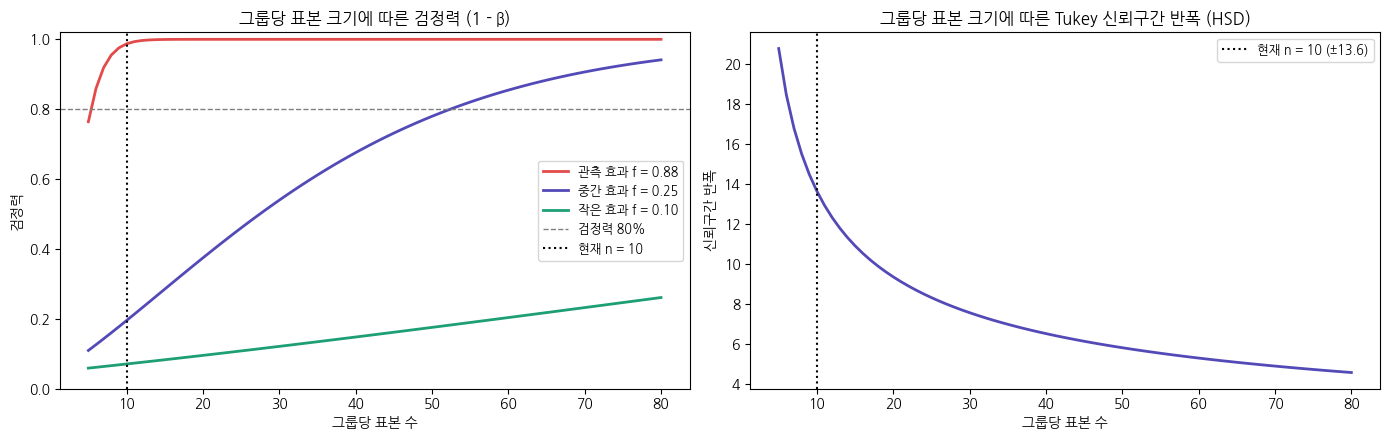

In [32]:
# 🧠 데이터를 어떻게 읽을까요? — 실행하면 계산된 값으로 해석이 출력됩니다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.power import FTestAnovaPower

try:
    import matplotlib.font_manager as fm
    fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
    plt.rc('font', family='NanumGothic')
except Exception:
    pass
plt.rc('axes', unicode_minus=False)

# 데이터 (주어진 코드와 동일)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})
groups = {'A': fertilizer_a, 'B': fertilizer_b, 'C': fertilizer_c}
alpha, k, n = 0.05, 3, 10

f_stat, p_anova = stats.f_oneway(*groups.values())
tukey = pairwise_tukeyhsd(df['수확량'], df['비료종류'], alpha=alpha)
tk = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
line = "─" * 70

# ① ANOVA p-값 해석
print(line)
print("① ANOVA p-값으로 내릴 수 있는 결론")
print(line)
print(f"F = {f_stat:.4f}, p = {p_anova:.6f}")
if p_anova < alpha:
    print(f"- p < {alpha} → H₀(세 비료의 평균이 모두 같다) 기각")
    print("- 의미: '적어도 하나의 비료는 평균 수확량이 다르다'")
    print("- '세 비료가 모두 동일한 효과를 가진다'는 뜻이 아니다. (그건 기각된 H₀)")
    print("- 또한 '세 비료가 모두 서로 다르다'는 뜻도 아니다.")
    print("  → ANOVA는 어느 비료가 다른지 알려주지 않으므로 사후분석(Tukey HSD)이 필요\n")
else:
    print(f"- p ≥ {alpha} → H₀ 기각 못 함: 평균이 다르다고 할 증거가 부족\n")

# ② reject 열
print(line)
print("② Tukey HSD 결과표의 reject = True 조합과 의미")
print(line)
print(tukey)
for _, r in tk.iterrows():
    mark = "True  → 두 비료의 평균 수확량이 유의하게 다르다" if r['reject'] else \
           "False → 유의한 차이가 없다 (같다고 증명된 것은 아님)"
    print(f"  {r['group1']} vs {r['group2']}: reject = {mark}")
true_pairs = [f"{r['group1']}-{r['group2']}" for _, r in tk.iterrows() if r['reject']]
print(f"- reject = True 조합: {', '.join(true_pairs)}")
print("- reject = True는 '세 쌍을 동시에 비교해도 전체 오류율 5%(FWER) 안에서'")
print("  해당 쌍의 H₀(두 평균이 같다)를 기각한다는 뜻")
common = set(true_pairs[0].split('-')).intersection(*[set(p.split('-')) for p in true_pairs[1:]]) \
    if len(true_pairs) > 1 else set()
if common:
    g = common.pop()
    print(f"  → 두 조합 모두 {g}가 포함됨: ANOVA에서 '다른 하나'는 비료 {g}\n")
else:
    print()

# ③ meandiff, 신뢰구간
print(line)
print("③ meandiff와 신뢰구간(lower, upper)의 의미")
print(line)
print("- meandiff = group2 평균 - group1 평균 (차이의 방향과 크기)")
for _, r in tk.iterrows():
    m1, m2 = groups[r['group1']].mean(), groups[r['group2']].mean()
    lo, hi = float(r['lower']), float(r['upper'])
    has0 = lo < 0 < hi
    direction = f"{r['group2']}가 {r['group1']}보다 {abs(r['meandiff']):.2f} " + \
                ("높음" if r['meandiff'] > 0 else "낮음")
    print(f"  {r['group1']} vs {r['group2']}: {m2:.2f} - {m1:.2f} = {r['meandiff']:+.2f} ({direction})")
    print(f"      95% 신뢰구간 [{lo:.2f}, {hi:.2f}] → 0을 {'포함함 → 차이가 0일 수도 있음 → 유의하지 않음' if has0 else '포함하지 않음 → 차이가 0이 아님 → 유의함'}")
print("- 신뢰구간이 0을 포함하는지 여부와 reject 결과는 항상 일치한다.")
print("- 구간의 폭은 차이 추정의 정밀도: 폭이 넓을수록 실제 차이가 얼마인지 불확실함\n")

# ④ 표본 크기
grand = df['수확량'].mean()
SSB = sum(n * (x.mean() - grand) ** 2 for x in groups.values())
SSW = sum(np.sum((x - x.mean()) ** 2) for x in groups.values())
eta2 = SSB / (SSB + SSW)
f_eff = np.sqrt(eta2 / (1 - eta2))                     # Cohen's f
power_calc = FTestAnovaPower()
power_now = power_calc.power(effect_size=f_eff, nobs=n * k, alpha=alpha, k_groups=k)
MSW = SSW / (n * k - k)
hsd_now = stats.studentized_range.ppf(1 - alpha, k, n * k - k) * np.sqrt(MSW / n)

print(line)
print("④ 그룹별 표본 크기 10개가 결론의 신뢰도에 주는 영향과 개선 방법")
print(line)
print(f"- 현재 신뢰구간 폭: 약 ±{hsd_now:.2f} (차이 추정이 꽤 넓음)")
print(f"  예) A vs B 차이는 23.68이지만 실제로는 "
      f"{float(tk.iloc[0]['lower']):.1f}~{float(tk.iloc[0]['upper']):.1f} 어디일 수도 있음")
print(f"- A vs C 차이 {groups['C'].mean()-groups['A'].mean():.2f}가 '유의하지 않음'인 것도")
print("  진짜 차이가 없어서인지, 표본이 작아 못 잡은 것(2종 오류, β)인지 구분이 어려움")
print(f"- 관측된 효과 크기(Cohen's f = {f_eff:.2f})에서 현재 검정력 = {power_now:.2f}")
print("  (이번처럼 큰 효과는 잘 잡지만, 작은 차이는 놓치기 쉬움)")
print("- 정규성·등분산성 검정도 표본이 작으면 위반을 잘 못 잡음 → 가정 점검의 신뢰도도 낮음")

print("\n- 표본 크기를 늘리면 (MSW가 그대로라고 가정):")
for n_new in [10, 20, 30, 50]:
    hsd = stats.studentized_range.ppf(1 - alpha, k, n_new * k - k) * np.sqrt(MSW / n_new)
    print(f"    그룹당 {n_new:>2}개 → 신뢰구간 ±{hsd:.2f}")

n_ac = []
d_ac = abs(groups['C'].mean() - groups['A'].mean())
for f_target, label in [(0.25, "중간 효과"), (0.10, "작은 효과")]:
    n_total = power_calc.solve_power(effect_size=f_target, alpha=alpha, power=0.8, k_groups=k)
    print(f"- {label}(f = {f_target})를 검정력 80%로 잡으려면 그룹당 약 {int(np.ceil(n_total / k))}개 필요")

print("\n- 개선 방법:")
print("    · 그룹당 표본을 늘려 재실험 (위 계산 기준 최소 50개 이상 권장)")
print("    · 여러 지역·계절에서 반복 실험해 결과가 일반화되는지 확인")
print("    · 토양·일조량 등 외부 요인을 통제하거나 블록 설계(같은 조건의 밭끼리 비교)로 잡음(MSW) 줄이기")
print("    · 밭에 비료를 무작위로 배정해 다른 요인이 섞이지 않게 하기")

# ── 그래프: 표본 크기에 따른 검정력과 신뢰구간 폭 ────
ns = np.arange(5, 81)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
for f_t, c, lab in [(f_eff, '#E24B4A', f'관측 효과 f = {f_eff:.2f}'), (0.25, '#534AB7', '중간 효과 f = 0.25'),
                    (0.10, '#1D9E75', '작은 효과 f = 0.10')]:
    ax.plot(ns, [power_calc.power(effect_size=f_t, nobs=m * k, alpha=alpha, k_groups=k) for m in ns],
            color=c, lw=2, label=lab)
ax.axhline(0.8, color='gray', ls='--', lw=1, label='검정력 80%')
ax.axvline(10, color='k', ls=':', lw=1.5, label='현재 n = 10')
ax.set_title('그룹당 표본 크기에 따른 검정력 (1 - β)')
ax.set_xlabel('그룹당 표본 수'); ax.set_ylabel('검정력'); ax.set_ylim(0, 1.02); ax.legend(fontsize=9)

ax = axes[1]
ax.plot(ns, [stats.studentized_range.ppf(1 - alpha, k, m * k - k) * np.sqrt(MSW / m) for m in ns],
        color='#534AB7', lw=2)
ax.axvline(10, color='k', ls=':', lw=1.5, label=f'현재 n = 10 (±{hsd_now:.1f})')
ax.set_title('그룹당 표본 크기에 따른 Tukey 신뢰구간 반폭 (HSD)')
ax.set_xlabel('그룹당 표본 수'); ax.set_ylabel('신뢰구간 반폭'); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()